In [1]:
# Put the repository root on sys.path, wherever the kernel was started from.
import os, sys

def _find_repo_root():
    _pkgs = ("genotyping", "pipelines", "screening", "sequencing")
    for _cand in [os.getcwd(), *sys.path]:
        if not _cand:
            continue
        _d = os.path.abspath(_cand)
        while True:
            if all(os.path.isdir(os.path.join(_d, _p)) for _p in _pkgs):
                return _d
            _parent = os.path.dirname(_d)
            if _parent == _d:
                break
            _d = _parent
    return None

_repo_root = _find_repo_root()
if _repo_root and _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import A13_config as config

import sys
import os
import multiprocessing as mp
import importlib

from pipelines import common_tasks

# Reload the modules
importlib.reload(config)
importlib.reload(common_tasks)


/mnt/mnemo2/opt/conda/envs/tnpb-analysis/lib/python3.10/site-packages/Bio/pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


<module 'pipelines.common_tasks' from '/home/tao/code/tnpb-analysis/pipelines/common_tasks.py'>

In [2]:
NAS_folder = "/mnt/G_Pharma/Users/tfang/Cell_Screen/Priscilla_A13_Screen"

In [3]:
samples=config.get_samples()
samples

,long_name,short_name,file_name_R1,file_name_R2,conversion_type,cell_line,library_name,editor,nuclease_yes_no,ABE_yes_no,control_yes_no,replicate,Reference file
0,HEK293T_TnpB-WT_ABE_d10_rep_1,A13-01_Sample-1,377671_415-A13-01_Sample-1_S36_R1_001.fastq.gz,377671_415-A13-01_Sample-1_S36_R2_001.fastq.gz,ABE,HEK293T,TWIST3_0,TnpB-WT_ABE_d10,no,yes,no,1,20240405_TnpB_Sample_Info_ISDra2TnpB_TWIST3_RE...
1,HEK293T_TnpB-Var1-140_ABE_d10_rep_1,A13-01_Sample-2,377671_416-A13-01_Sample-2_S17_R1_001.fastq.gz,377671_416-A13-01_Sample-2_S17_R2_001.fastq.gz,ABE,HEK293T,TWIST3_0,TnpB-Var1-140_ABE_d10,no,yes,no,1,20240405_TnpB_Sample_Info_ISDra2TnpB_TWIST3_RE...
2,HEK293T_TnpB-Var2-163_ABE_d10_rep_1,A13-01_Sample-3,377671_417-A13-01_Sample-3_S112_R1_001.fastq.gz,377671_417-A13-01_Sample-3_S112_R2_001.fastq.gz,ABE,HEK293T,TWIST3_0,TnpB-Var2-163_ABE_d10,no,yes,no,1,20240405_TnpB_Sample_Info_ISDra2TnpB_TWIST3_RE...
3,HEK293T_TnpB-Var3-164_ABE_d10_rep_1,A13-01_Sample-4,377671_418-A13-01_Sample-4_S41_R1_001.fastq.gz,377671_418-A13-01_Sample-4_S41_R2_001.fastq.gz,ABE,HEK293T,TWIST3_0,TnpB-Var3-164_ABE_d10,no,yes,no,1,20240405_TnpB_Sample_Info_ISDra2TnpB_TWIST3_RE...
4,HEK293T_TnpB-NONE_ABE_mock_d10_rep_1,A13-01_Sample-5,377671_419-A13-01_Sample-5_S194_R1_001.fastq.gz,377671_419-A13-01_Sample-5_S194_R2_001.fastq.gz,CTRL_ABE,HEK293T,TWIST3_0,TnpB-NONE_ABE_mock_d10,no,yes,yes,1,20240405_TnpB_Sample_Info_ISDra2TnpB_TWIST3_RE...
5,HEK293T_TnpB-WT_ABE_d10_rep_2,A13-01_Sample-6,377671_420-A13-01_Sample-6_S426_R1_001.fastq.gz,377671_420-A13-01_Sample-6_S426_R2_001.fastq.gz,ABE,HEK293T,TWIST3_0,TnpB-WT_ABE_d10,no,yes,no,2,20240405_TnpB_Sample_Info_ISDra2TnpB_TWIST3_RE...
6,HEK293T_TnpB-Var1-140_ABE_d10_rep_2,A13-01_Sample-7,377671_421-A13-01_Sample-7_S404_R1_001.fastq.gz,377671_421-A13-01_Sample-7_S404_R2_001.fastq.gz,ABE,HEK293T,TWIST3_0,TnpB-Var1-140_ABE_d10,no,yes,no,2,20240405_TnpB_Sample_Info_ISDra2TnpB_TWIST3_RE...
7,HEK293T_TnpB-Var2-163_ABE_d10_rep_2,A13-01_Sample-8,377671_422-A13-01_Sample-8_S396_R1_001.fastq.gz,377671_422-A13-01_Sample-8_S396_R2_001.fastq.gz,ABE,HEK293T,TWIST3_0,TnpB-Var2-163_ABE_d10,no,yes,no,2,20240405_TnpB_Sample_Info_ISDra2TnpB_TWIST3_RE...
8,HEK293T_TnpB-Var3-164_ABE_d10_rep_2,A13-01_Sample-9,377671_423-A13-01_Sample-9_S356_R1_001.fastq.gz,377671_423-A13-01_Sample-9_S356_R2_001.fastq.gz,ABE,HEK293T,TWIST3_0,TnpB-Var3-164_ABE_d10,no,yes,no,2,20240405_TnpB_Sample_Info_ISDra2TnpB_TWIST3_RE...
9,HEK293T_TnpB-NONE_ABE_mock_d10_rep_2,A13-01_Sample-10,377671_424-A13-01_Sample-10_S39_R1_001.fastq.gz,377671_424-A13-01_Sample-10_S39_R2_001.fastq.gz,CTRL_ABE,HEK293T,TWIST3_0,TnpB-NONE_ABE_mock_d10,no,yes,yes,2,20240405_TnpB_Sample_Info_ISDra2TnpB_TWIST3_RE...


# analysis of the results

In [4]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import A13_config as config
import pandas as pd
import numpy as np
import os
import sys

import os, sys
_repo_root = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

from screening import screen_utils

# import A13_config as config

# import sys
# import os
# import multiprocessing as mp
import importlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# import os, sys
_repo_root = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

# # Reload the modules
importlib.reload(config)
importlib.reload(screen_utils)
# importlib.reload(common_tasks)

<module 'screening.screen_utils' from '/home/tao/code/tnpb-analysis/screening/screen_utils.py'>

In [5]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

def check_A_to_A_or_C(df):
    df['valid_diff_nt'] = df.apply(lambda row: sum(tsl == ts or (tsl == 'A' and ts in ['C', 'G']) for tsl, ts in zip(row['target_site_lib'], row['most_common_diff_target_site'])) if pd.notna(row['most_common_diff_target_site']) else 20, axis=1)
    return df

In [6]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

# Function to plot correlation with axis scale set to 0-1 and percentage formatting
def plot_correlation(df, col1, col2, col3,save_figure=False, figure_folder=None, figure_name=None):
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # Plot col1 vs col2
    sns.scatterplot(x=df[col1], y=df[col2], ax=axes[0])
    axes[0].set_xlabel(col1)
    axes[0].set_ylabel(col2)
    axes[0].set_xlim(0, 1)
    axes[0].set_ylim(0, 1)
    axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
    axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y*100:.0f}%'))
    axes[0].plot([0, 1], [0, 1], 'r--')  # Diagonal line

    # Calculate Pearson and Spearman correlation for col1 vs col2
    pearson_corr_1, _ = pearsonr(df[col1], df[col2])
    spearman_corr_1, _ = spearmanr(df[col1], df[col2])
    axes[0].legend([f'Pearson: {pearson_corr_1:.2f}', f'Spearman: {spearman_corr_1:.2f}'])

    # Plot col1 vs col3
    sns.scatterplot(x=df[col1], y=df[col3], ax=axes[1])
    axes[1].set_xlabel(col1)
    axes[1].set_ylabel(col3)
    axes[1].set_xlim(0, 1)
    axes[1].set_ylim(0, 1)
    axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
    axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y*100:.0f}%'))
    axes[1].plot([0, 1], [0, 1], 'r--')  # Diagonal line

    # Calculate Pearson and Spearman correlation for col1 vs col3
    pearson_corr_2, _ = pearsonr(df[col1], df[col3])
    spearman_corr_2, _ = spearmanr(df[col1], df[col3])
    axes[1].legend([f'Pearson: {pearson_corr_2:.2f}', f'Spearman: {spearman_corr_2:.2f}'])

    # Plot col2 vs col3
    sns.scatterplot(x=df[col2], y=df[col3], ax=axes[2])
    axes[2].set_xlabel(col2)
    axes[2].set_ylabel(col3)
    axes[2].set_xlim(0, 1)
    axes[2].set_ylim(0, 1)
    axes[2].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
    axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y*100:.0f}%'))
    axes[2].plot([0, 1], [0, 1], 'r--')  # Diagonal line

    # Calculate Pearson and Spearman correlation for col2 vs col3
    pearson_corr_3, _ = pearsonr(df[col2], df[col3])
    spearman_corr_3, _ = spearmanr(df[col2], df[col3])
    axes[2].legend([f'Pearson: {pearson_corr_3:.2f}', f'Spearman: {spearman_corr_3:.2f}'])

    plt.tight_layout()
    plt.show()

    if save_figure:
        fig.savefig(os.path.join(figure_folder, f"{figure_name}.png"), dpi=300)

In [7]:
lib = config.get_library()

In [8]:
lib = config.get_library()
lib

,Identifier,finalname,lib_section,specific_primerpart,barcode,spacer,oligofinal,length,target_site_rc,target_site,TAM_rc,TAM
0,1,1_MM_ENDO_TTTAT_20BP_Chr7_66359977_66360494_Fw...,MM_ENDO_TTTAT_20BP_,AGAGCCATTTGTCTCGCTGA,GCACGTA,AAAAAGGAAGTTGGTTATAC,GACTTTAGTCGTGTGAGGTTCAAAAAAAGGAAGTTGGTTATACGGC...,200,GTATAACCAACTTCCTTTTT,AAAAAGGAAGTTGGTTATAC,ATAAA,TTTAT
1,2,2_MM_ENDO_TTTAT_20BP_Chr15_23173536_23175227_R...,MM_ENDO_TTTAT_20BP_,AGAGCCATTTGTCTCGCTGA,CGACGTC,AGTAACAAAGACAAGTATAT,GACTTTAGTCGTGTGAGGTTCAAAGTAACAAAGACAAGTATATGGC...,200,ATATACTTGTCTTTGTTACT,AGTAACAAAGACAAGTATAT,ATAAA,TTTAT
2,3,3_MM_ENDO_TTTAT_20BP_Chr3_102843301_102843416_...,MM_ENDO_TTTAT_20BP_,AGAGCCATTTGTCTCGCTGA,GATGTTC,GAAGACGACATGGAACGGAA,GACTTTAGTCGTGTGAGGTTCAAGAAGACGACATGGAACGGAAGGC...,200,TTCCGTTCCATGTCGTCTTC,GAAGACGACATGGAACGGAA,ATAAA,TTTAT
3,4,4_MM_ENDO_TTTAT_20BP_Chr18_24415158_24415928_R...,MM_ENDO_TTTAT_20BP_,AGAGCCATTTGTCTCGCTGA,AGGAAAT,TAACTGGAGTACTTAAAGAA,GACTTTAGTCGTGTGAGGTTCAATAACTGGAGTACTTAAAGAAGGC...,200,TTCTTTAAGTACTCCAGTTA,TAACTGGAGTACTTAAAGAA,ATAAA,TTTAT
4,5,5_MM_ENDO_TTTAT_20BP_Chr2_131138192_131138611_...,MM_ENDO_TTTAT_20BP_,AGAGCCATTTGTCTCGCTGA,GTCGCCT,GATCGTGTACTACTCAAATC,GACTTTAGTCGTGTGAGGTTCAAGATCGTGTACTACTCAAATCGGC...,200,GATTTGAGTAGTACACGATC,GATCGTGTACTACTCAAATC,ATAAA,TTTAT
...,...,...,...,...,...,...,...,...,...,...,...,...
5995,5996,5996_TAM_PERMUT_TTGAG_100MEMBER_spacer_96,TAM_PERMUT_TTGAG_,AGAGCCATTTGTCTCGCTGA,GTTTGGA,AGGGTCCTTGAGAGGCCAAT,GACTTTAGTCGTGTGAGGTTCAAAGGGTCCTTGAGAGGCCAATGGC...,200,ATTGGCCTCTCAAGGACCCT,AGGGTCCTTGAGAGGCCAAT,CTCAA,TTGAG
5996,5997,5997_TAM_PERMUT_TTGAG_100MEMBER_spacer_97,TAM_PERMUT_TTGAG_,AGAGCCATTTGTCTCGCTGA,ACAATAG,TGAGATCACGCCATGTAGGC,GACTTTAGTCGTGTGAGGTTCAATGAGATCACGCCATGTAGGCGGC...,200,GCCTACATGGCGTGATCTCA,TGAGATCACGCCATGTAGGC,CTCAA,TTGAG
5997,5998,5998_TAM_PERMUT_TTGAG_100MEMBER_spacer_98,TAM_PERMUT_TTGAG_,AGAGCCATTTGTCTCGCTGA,TTAACAT,TACGGAATCCCCCTCTGGGG,GACTTTAGTCGTGTGAGGTTCAATACGGAATCCCCCTCTGGGGGGC...,200,CCCCAGAGGGGGATTCCGTA,TACGGAATCCCCCTCTGGGG,CTCAA,TTGAG
5998,5999,5999_TAM_PERMUT_TTGAG_100MEMBER_spacer_99,TAM_PERMUT_TTGAG_,AGAGCCATTTGTCTCGCTGA,GGTAAAA,AGTTGTCCTTTAGATTGTAG,GACTTTAGTCGTGTGAGGTTCAAAGTTGTCCTTTAGATTGTAGGGC...,200,CTACAATCTAAAGGACAACT,AGTTGTCCTTTAGATTGTAG,CTCAA,TTGAG


## check postion level qualit 

In [9]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

results_df_not_normalized = pd.read_csv(config.edit_rate('all-abe-samples-not-normalized'), index_col=0)
print(results_df_not_normalized.shape)
results_df_not_normalized=results_df_not_normalized[results_df_not_normalized['num_reads'] > 100]
print(results_df_not_normalized.shape)

results_df_not_normalized.head(n=3)

(501105, 15)
(474402, 15)


,barcode,TAM,edit_position,num_reads,target_site,spacer,spacer_lib,target_site_lib,most_common_diff_target_site,most_common_diff_target_site_num,edit_rate,editor,sample_name,is_ctrl,replicate
0,AAAAAAA,TAGAT,2,1965,AAACATTGTCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,38.0,0.001527,TnpB-WT_ABE_d10,HEK293T_TnpB-WT_ABE_d10_rep_1,False,1
1,AAAAAAA,TAGAT,3,1965,AAACATTGTCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,38.0,0.001527,TnpB-WT_ABE_d10,HEK293T_TnpB-WT_ABE_d10_rep_1,False,1
2,AAAAAAA,TAGAT,5,1965,AAACATTGTCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,38.0,0.003053,TnpB-WT_ABE_d10,HEK293T_TnpB-WT_ABE_d10_rep_1,False,1


In [10]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

results_df_not_normalized = results_df_not_normalized.merge(lib[['barcode', 'finalname', 'lib_section', 'specific_primerpart']], on='barcode', how='left')
print(results_df_not_normalized.shape)
results_df_not_normalized.head(n=3)

(474402, 18)


,barcode,TAM,edit_position,num_reads,target_site,spacer,spacer_lib,target_site_lib,most_common_diff_target_site,most_common_diff_target_site_num,edit_rate,editor,sample_name,is_ctrl,replicate,finalname,lib_section,specific_primerpart
0,AAAAAAA,TAGAT,2,1965,AAACATTGTCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,38.0,0.001527,TnpB-WT_ABE_d10,HEK293T_TnpB-WT_ABE_d10_rep_1,False,1,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA
1,AAAAAAA,TAGAT,3,1965,AAACATTGTCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,38.0,0.001527,TnpB-WT_ABE_d10,HEK293T_TnpB-WT_ABE_d10_rep_1,False,1,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA
2,AAAAAAA,TAGAT,5,1965,AAACATTGTCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,38.0,0.003053,TnpB-WT_ABE_d10,HEK293T_TnpB-WT_ABE_d10_rep_1,False,1,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA


In [11]:
results_df_not_normalized_pivot_df = results_df_not_normalized.pivot_table(index=['barcode', 'TAM', 'edit_position',"target_site_lib","finalname","lib_section","specific_primerpart"],
                                           columns='sample_name',
                                           values=['edit_rate','num_reads', 'most_common_diff_target_site'],  # values='edit_rate',
                                            aggfunc='first'
                                           ).reset_index()

results_df_not_normalized_pivot_df.columns = ['_'.join(col).strip() for col in results_df_not_normalized_pivot_df.columns.values]

print(results_df_not_normalized_pivot_df.shape)
results_df_not_normalized_pivot_df.head(n=3)

(32718, 52)


,barcode_,TAM_,edit_position_,target_site_lib_,finalname_,lib_section_,specific_primerpart_,edit_rate_HEK293T_TnpB-NONE_ABE_mock_d10_rep_1,edit_rate_HEK293T_TnpB-NONE_ABE_mock_d10_rep_2,edit_rate_HEK293T_TnpB-NONE_ABE_mock_d10_rep_3,...,num_reads_HEK293T_TnpB-Var1-140_ABE_d10_rep_3,num_reads_HEK293T_TnpB-Var2-163_ABE_d10_rep_1,num_reads_HEK293T_TnpB-Var2-163_ABE_d10_rep_2,num_reads_HEK293T_TnpB-Var2-163_ABE_d10_rep_3,num_reads_HEK293T_TnpB-Var3-164_ABE_d10_rep_1,num_reads_HEK293T_TnpB-Var3-164_ABE_d10_rep_2,num_reads_HEK293T_TnpB-Var3-164_ABE_d10_rep_3,num_reads_HEK293T_TnpB-WT_ABE_d10_rep_1,num_reads_HEK293T_TnpB-WT_ABE_d10_rep_2,num_reads_HEK293T_TnpB-WT_ABE_d10_rep_3
0,AAAAAAA,TAGAT,2,GAACATTATCGGTATCTTGA,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA,0.005637,0.001284,0.000529,...,1964.0,1880.0,2071.0,1828.0,1646.0,2574.0,2054.0,1965.0,1910.0,2400.0
1,AAAAAAA,TAGAT,3,GAACATTATCGGTATCTTGA,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA,0.003036,0.003853,0.003173,...,1964.0,1880.0,2071.0,1828.0,1646.0,2574.0,2054.0,1965.0,1910.0,2400.0
2,AAAAAAA,TAGAT,5,GAACATTATCGGTATCTTGA,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA,0.003036,0.000856,0.001058,...,1964.0,1880.0,2071.0,1828.0,1646.0,2574.0,2054.0,1965.0,1910.0,2400.0


In [12]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

simple_new_columns=["HEK293T_TnpB-Var1-140_ABE_d10_rep_1","HEK293T_TnpB-Var1-140_ABE_d10_rep_2","HEK293T_TnpB-Var1-140_ABE_d10_rep_3",
             "HEK293T_TnpB-Var2-163_ABE_d10_rep_1","HEK293T_TnpB-Var2-163_ABE_d10_rep_2","HEK293T_TnpB-Var2-163_ABE_d10_rep_3",
             "HEK293T_TnpB-Var3-164_ABE_d10_rep_1","HEK293T_TnpB-Var3-164_ABE_d10_rep_2","HEK293T_TnpB-Var3-164_ABE_d10_rep_3",
             "HEK293T_TnpB-WT_ABE_d10_rep_1","HEK293T_TnpB-WT_ABE_d10_rep_2","HEK293T_TnpB-WT_ABE_d10_rep_3",
             ]

new_columns=[["edit_rate_"+c,"num_reads_"+c] for c in simple_new_columns]
new_columns=[item for sublist in new_columns for item in sublist]

results_df_not_normalized_pivot_df = results_df_not_normalized_pivot_df[[col for col in results_df_not_normalized_pivot_df.columns if col not in new_columns] +new_columns ]
print(results_df_not_normalized_pivot_df.shape)

sorting_columns=["edit_rate_"+c for c in simple_new_columns]
results_df_not_normalized_pivot_df = results_df_not_normalized_pivot_df.sort_values(by=sorting_columns, ascending=[False] * len(sorting_columns), na_position='last')
results_df_not_normalized_pivot_df

(32718, 52)


,barcode_,TAM_,edit_position_,target_site_lib_,finalname_,lib_section_,specific_primerpart_,edit_rate_HEK293T_TnpB-NONE_ABE_mock_d10_rep_1,edit_rate_HEK293T_TnpB-NONE_ABE_mock_d10_rep_2,edit_rate_HEK293T_TnpB-NONE_ABE_mock_d10_rep_3,...,edit_rate_HEK293T_TnpB-Var3-164_ABE_d10_rep_2,num_reads_HEK293T_TnpB-Var3-164_ABE_d10_rep_2,edit_rate_HEK293T_TnpB-Var3-164_ABE_d10_rep_3,num_reads_HEK293T_TnpB-Var3-164_ABE_d10_rep_3,edit_rate_HEK293T_TnpB-WT_ABE_d10_rep_1,num_reads_HEK293T_TnpB-WT_ABE_d10_rep_1,edit_rate_HEK293T_TnpB-WT_ABE_d10_rep_2,num_reads_HEK293T_TnpB-WT_ABE_d10_rep_2,edit_rate_HEK293T_TnpB-WT_ABE_d10_rep_3,num_reads_HEK293T_TnpB-WT_ABE_d10_rep_3
17814,GAGTCGA,TTAAT,19,GTCCCCGAGGCCCAGACCAG,2345_MM_TTAAT_20BP_Chr2_156604604_156605094_Fw...,MM_TTAAT_20BP_,AGAGCCATTTGTCTCGCTGA,0.980583,0.905172,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,103.0
5172,AGCGGAC,TTCAT,9,AAATTCCCAGCAGGGTCTTG,1672_MM_TTCAT_20BP_Chr16_33916165_33917460_Rv_368,MM_TTCAT_20BP_,AGAGCCATTTGTCTCGCTGA,0.374443,0.361426,0.490446,...,0.671405,1196.0,0.557047,447.0,0.792104,1621.0,0.726868,1124.0,0.689060,521.0
5173,AGCGGAC,TTCAT,12,AAATTCCCAGCAGGGTCTTG,1672_MM_TTCAT_20BP_Chr16_33916165_33917460_Rv_368,MM_TTCAT_20BP_,AGAGCCATTTGTCTCGCTGA,0.377415,0.359806,0.490446,...,0.671405,1196.0,0.557047,447.0,0.793954,1621.0,0.726868,1124.0,0.689060,521.0
1539,AAGTGCA,TTGGT,6,GGCGCAGCGCGTACCCTTCG,5647_TAM_PERMUT_TTGGT_100MEMBER_spacer_47,TAM_PERMUT_TTGGT_,AGAGCCATTTGTCTCGCTGA,0.835014,0.831012,0.817750,...,0.821664,757.0,0.835391,486.0,0.799537,863.0,0.824194,620.0,0.679144,374.0
14917,CTATATA,CTGAT,11,AGGGTCCTTGAGAGGCCAAT,4696_TAM_PERMUT_CTGAT_100MEMBER_spacer_96,TAM_PERMUT_CTGAT_,AGAGCCATTTGTCTCGCTGA,0.116618,0.075000,0.184397,...,0.625498,251.0,0.371728,382.0,0.397163,141.0,0.751678,298.0,0.767123,365.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23905,GTTAATC,TTCAT,6,TCTGTAGCCTGCCCCTGGTC,1696_MM_TTCAT_20BP_Chr5_102218715_102219206_Rv...,MM_TTCAT_20BP_,AGAGCCATTTGTCTCGCTGA,0.000000,0.007812,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
24661,TAACTCG,TTGAG,8,TGCGTGGAGTCTGTGTGCGG,5993_TAM_PERMUT_TTGAG_100MEMBER_spacer_93,TAM_PERMUT_TTGAG_,AGAGCCATTTGTCTCGCTGA,0.000000,0.000000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
30419,TGTCGTA,TTTAT,14,GCCCTCCTGGTGGAAGCCAC,541_MM_ENDO_TTTAT_20BP_Chr1_168163548_16816524...,MM_ENDO_TTTAT_20BP_,AGAGCCATTTGTCTCGCTGA,0.009901,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
30420,TGTCGTA,TTTAT,15,GCCCTCCTGGTGGAAGCCAC,541_MM_ENDO_TTTAT_20BP_Chr1_168163548_16816524...,MM_ENDO_TTTAT_20BP_,AGAGCCATTTGTCTCGCTGA,0.019802,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


(32718, 12)


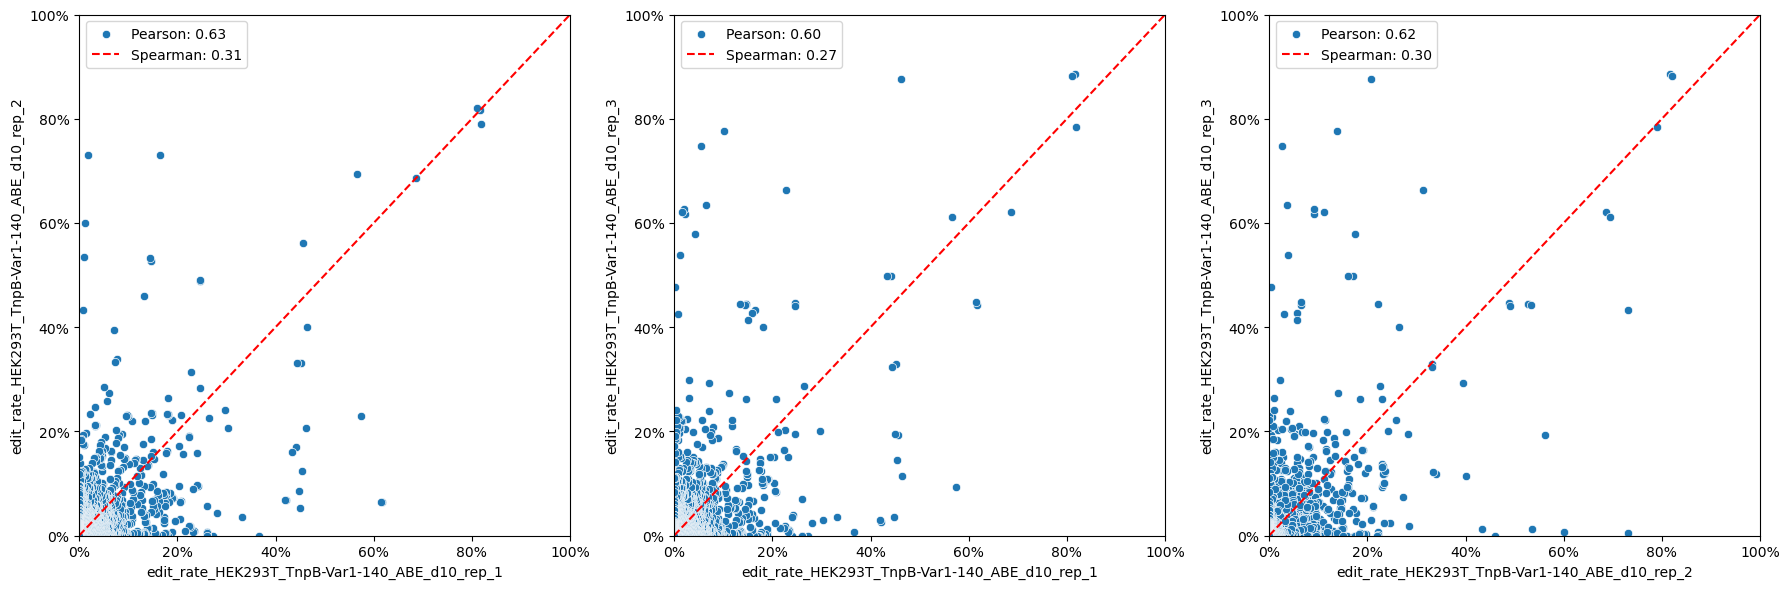

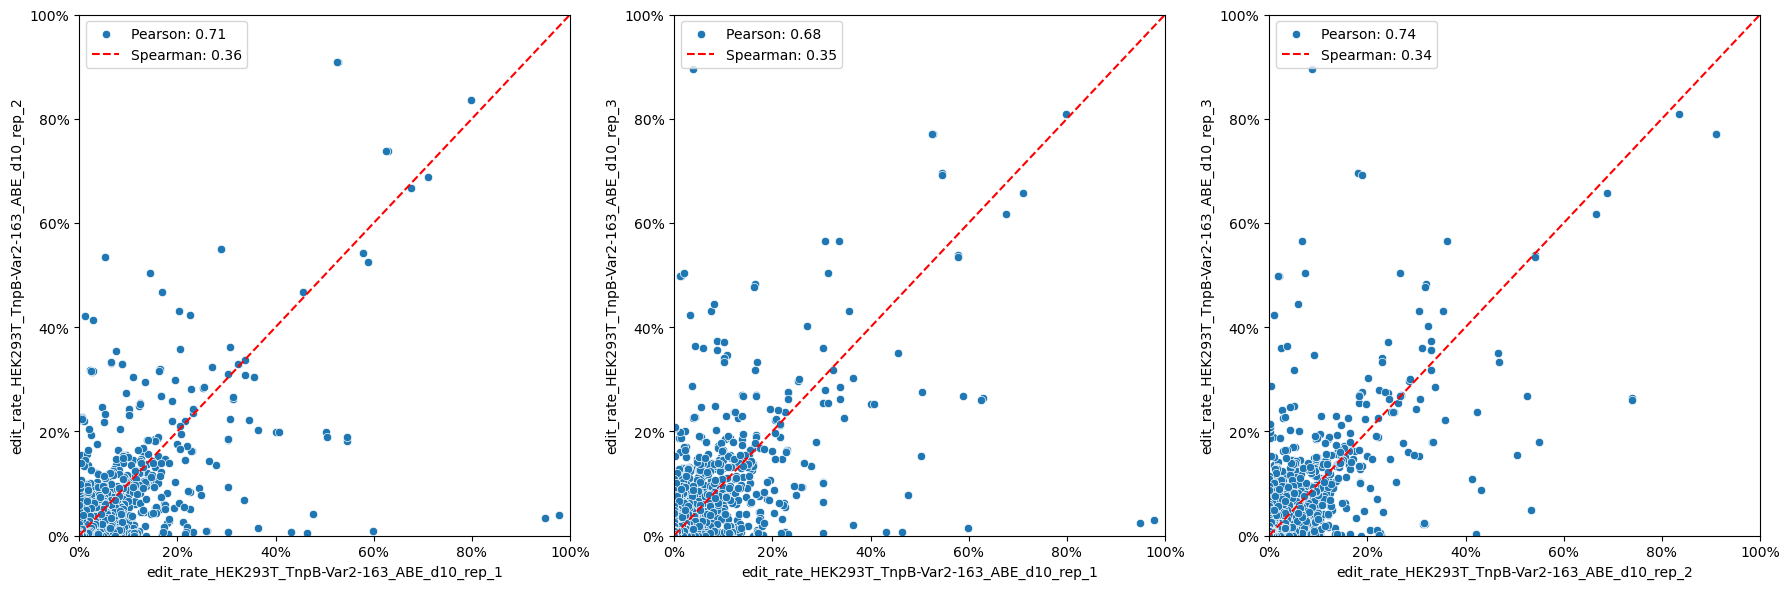

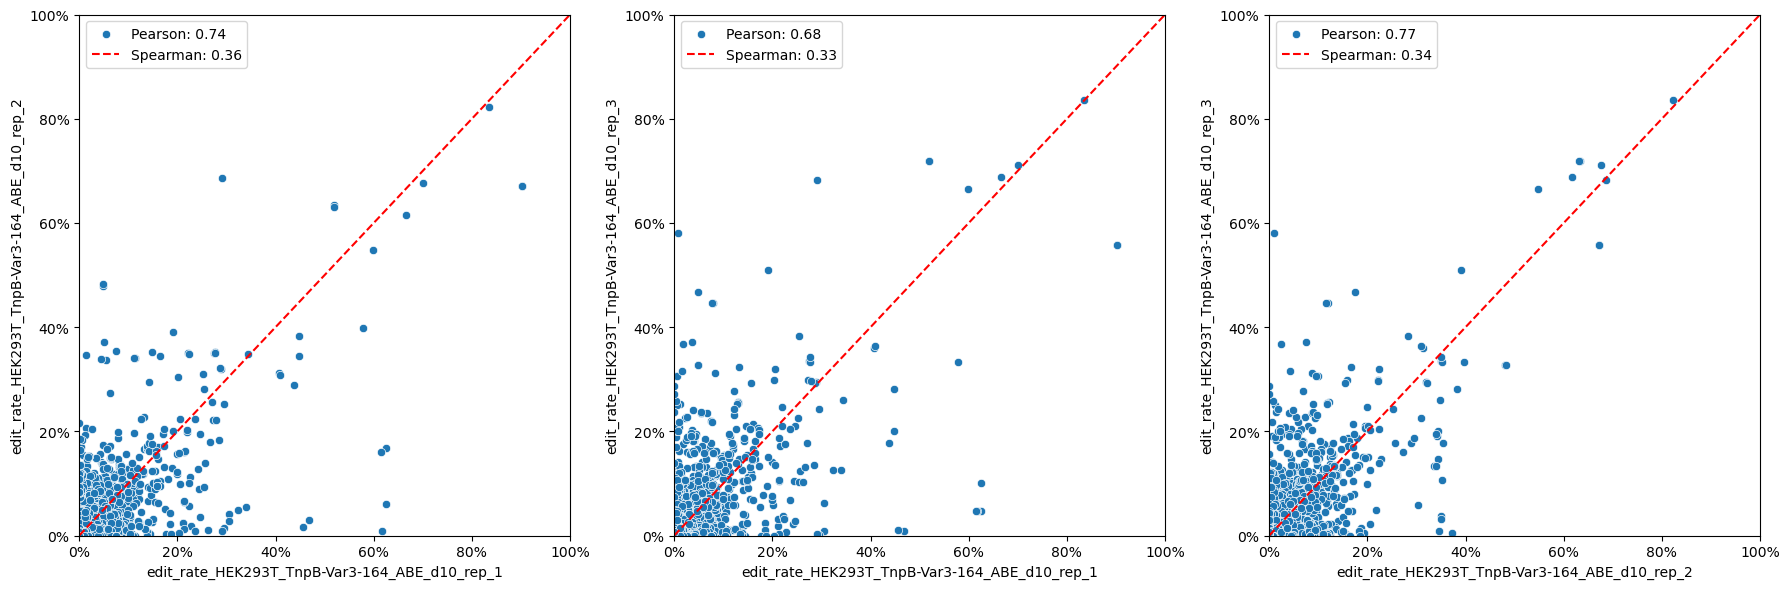

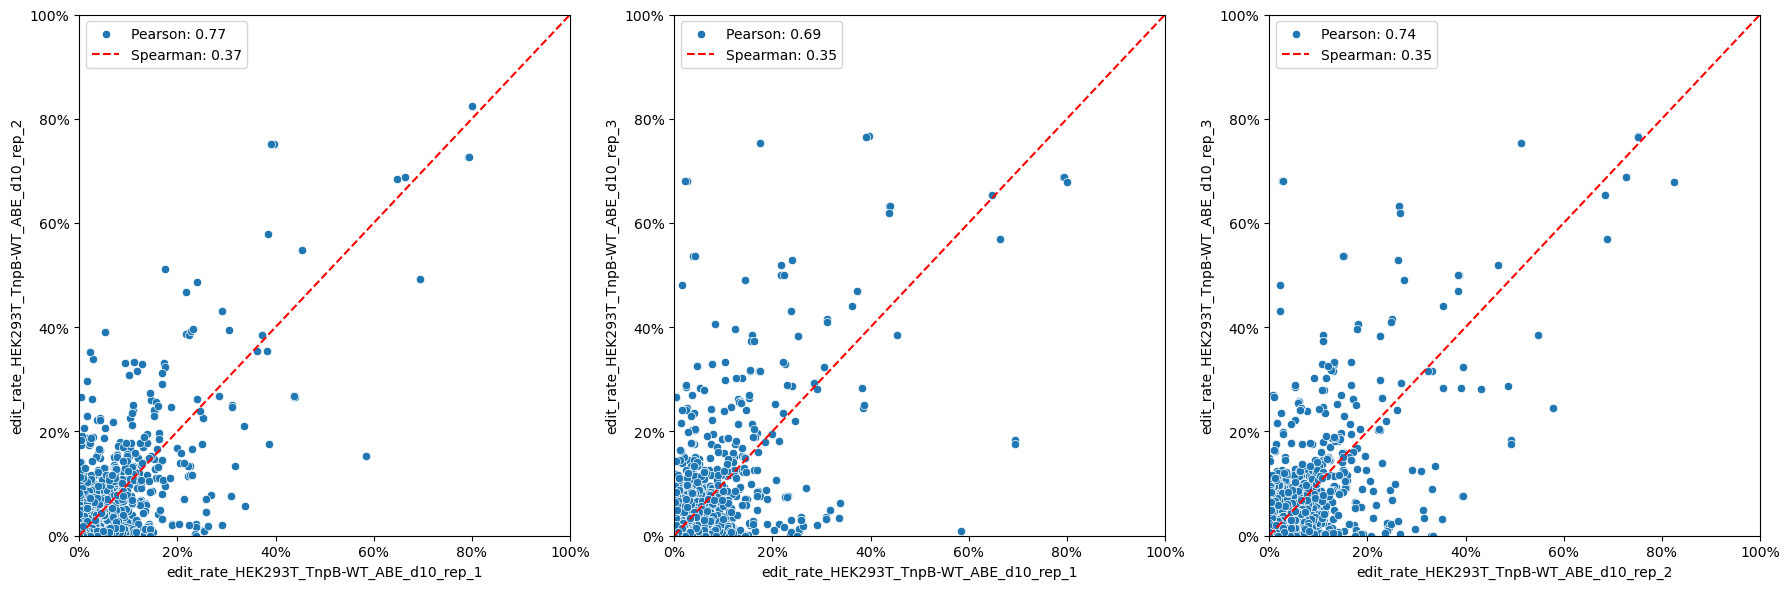

In [13]:
editor_columns=['edit_rate_HEK293T_TnpB-Var1-140_ABE_d10_rep_1',
 'edit_rate_HEK293T_TnpB-Var1-140_ABE_d10_rep_2',
 'edit_rate_HEK293T_TnpB-Var1-140_ABE_d10_rep_3',
 'edit_rate_HEK293T_TnpB-Var2-163_ABE_d10_rep_1',
 'edit_rate_HEK293T_TnpB-Var2-163_ABE_d10_rep_2',
 'edit_rate_HEK293T_TnpB-Var2-163_ABE_d10_rep_3',
 'edit_rate_HEK293T_TnpB-Var3-164_ABE_d10_rep_1',
 'edit_rate_HEK293T_TnpB-Var3-164_ABE_d10_rep_2',
 'edit_rate_HEK293T_TnpB-Var3-164_ABE_d10_rep_3',
 'edit_rate_HEK293T_TnpB-WT_ABE_d10_rep_1',
 'edit_rate_HEK293T_TnpB-WT_ABE_d10_rep_2',
 'edit_rate_HEK293T_TnpB-WT_ABE_d10_rep_3']

results_df_not_normalized_pivot_df_slim=results_df_not_normalized_pivot_df.loc[:,list(editor_columns)]
print(results_df_not_normalized_pivot_df_slim.shape)

# Iterate over every 3 columns
for i in range(0, len(results_df_not_normalized_pivot_df_slim.columns), 3):
    if i + 2 < len(results_df_not_normalized_pivot_df_slim.columns):
        col1 = results_df_not_normalized_pivot_df_slim.columns[i]
        col2 = results_df_not_normalized_pivot_df_slim.columns[i + 1]
        col3 = results_df_not_normalized_pivot_df_slim.columns[i + 2]

        test=results_df_not_normalized_pivot_df_slim[[col1,col2,col3]]
        test = test.dropna()
        plot_correlation(test, col1, col2, col3)

(7761, 12)


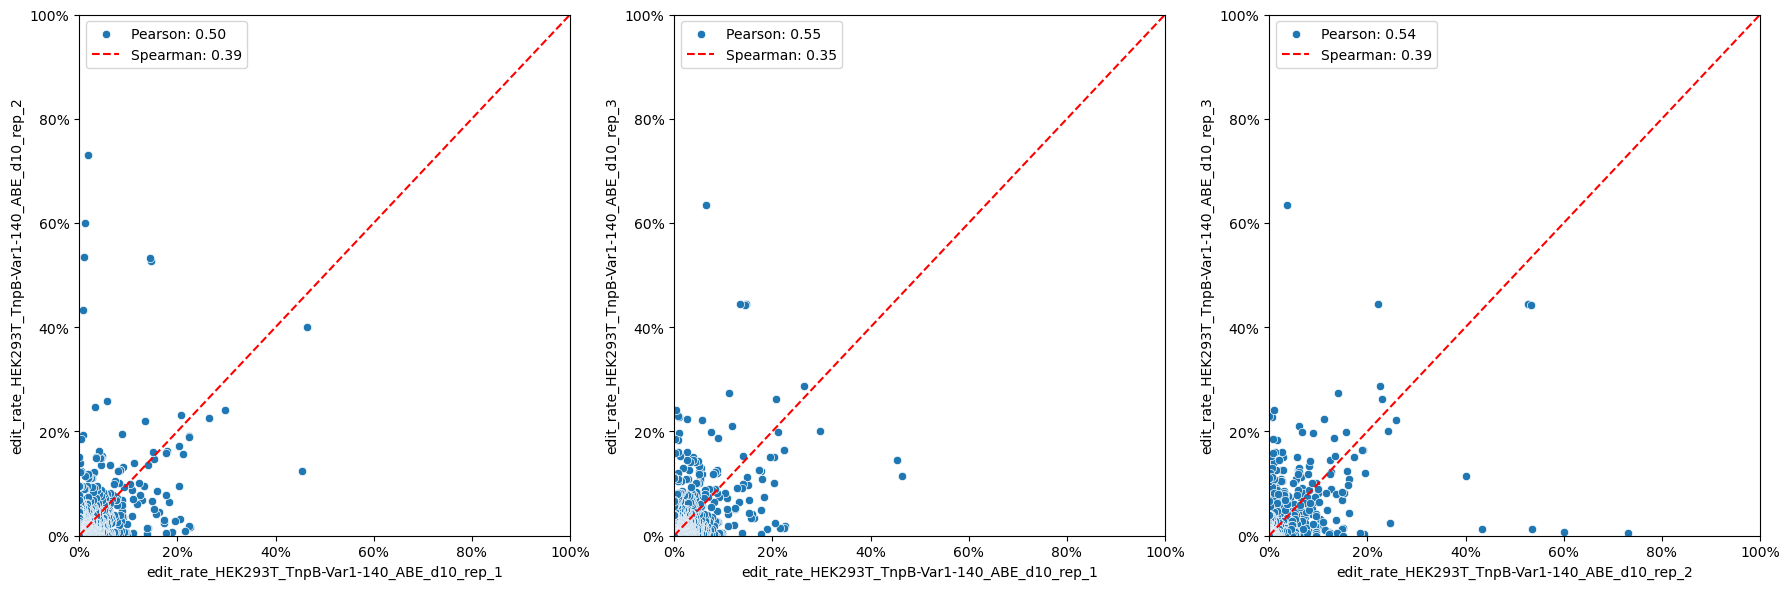

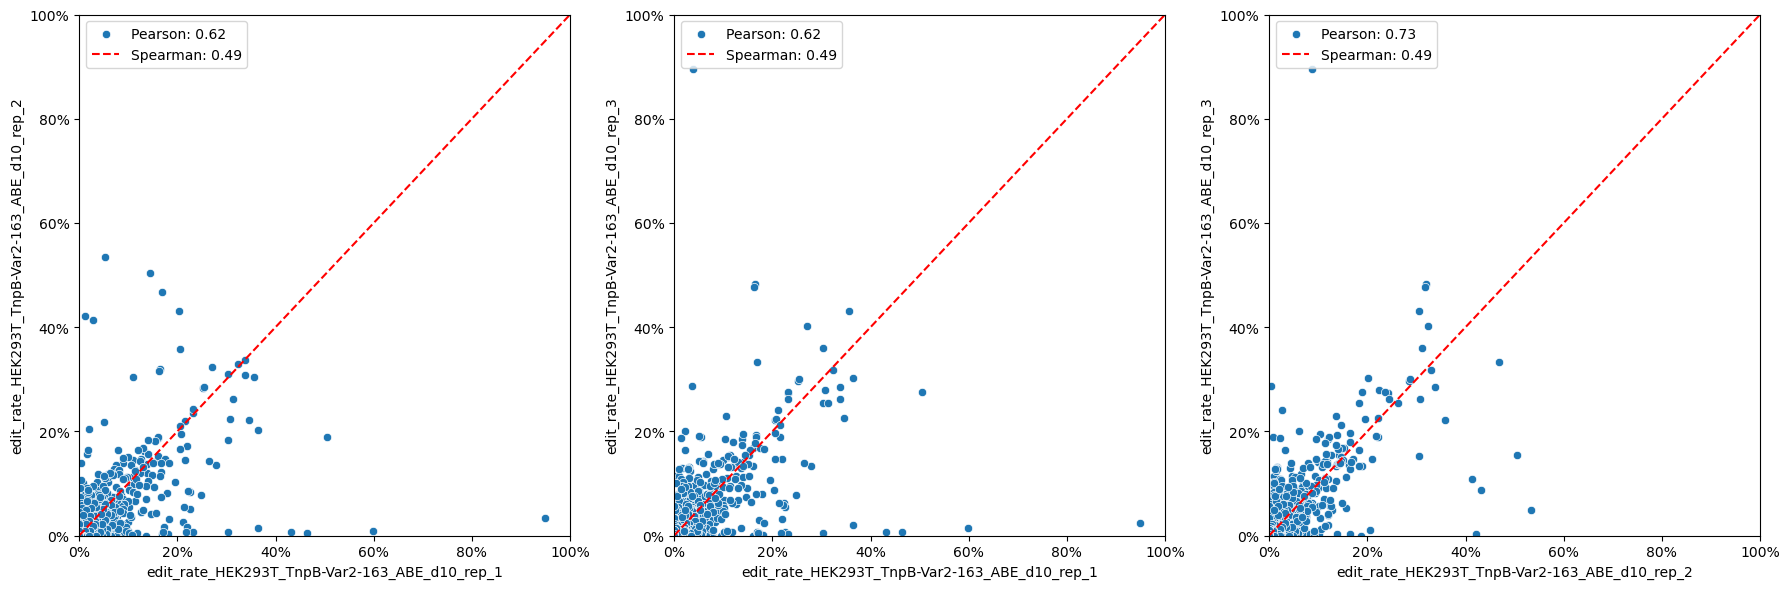

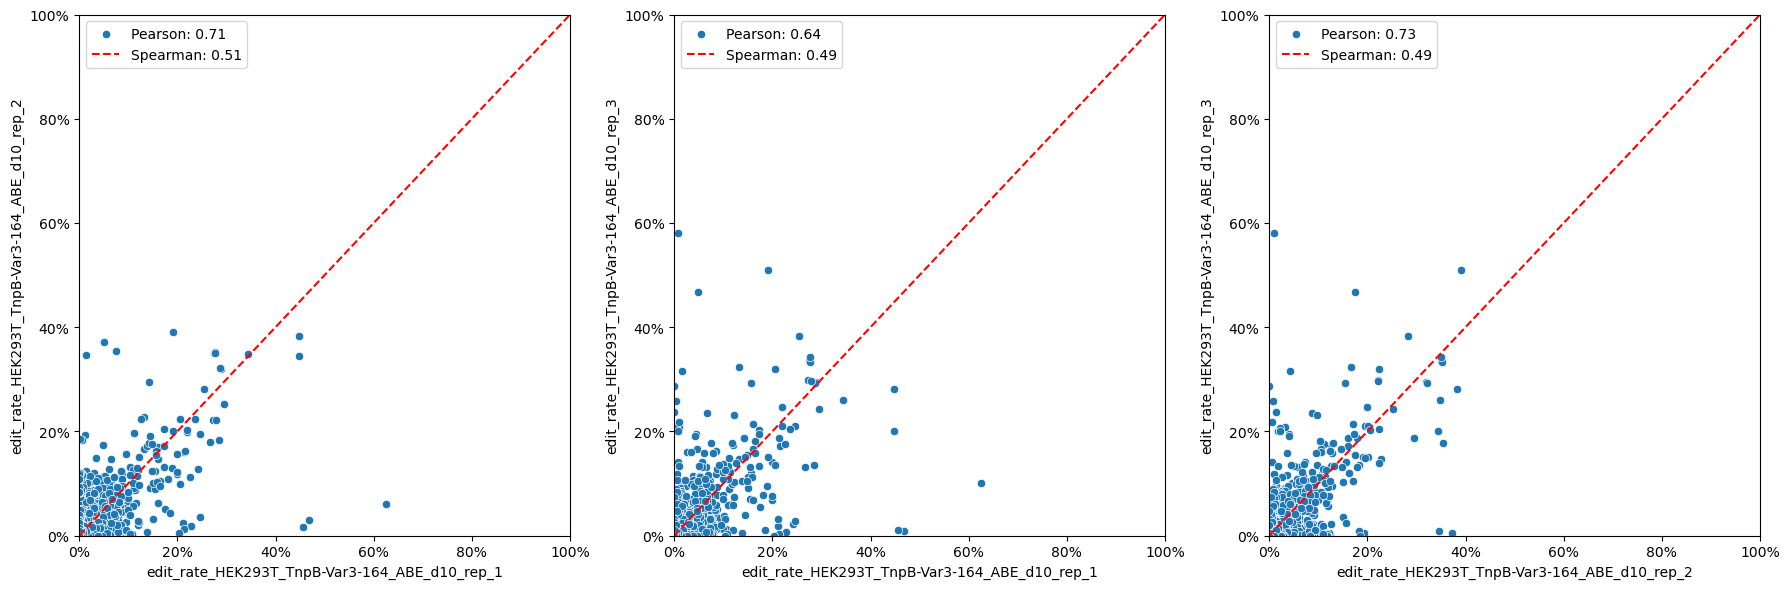

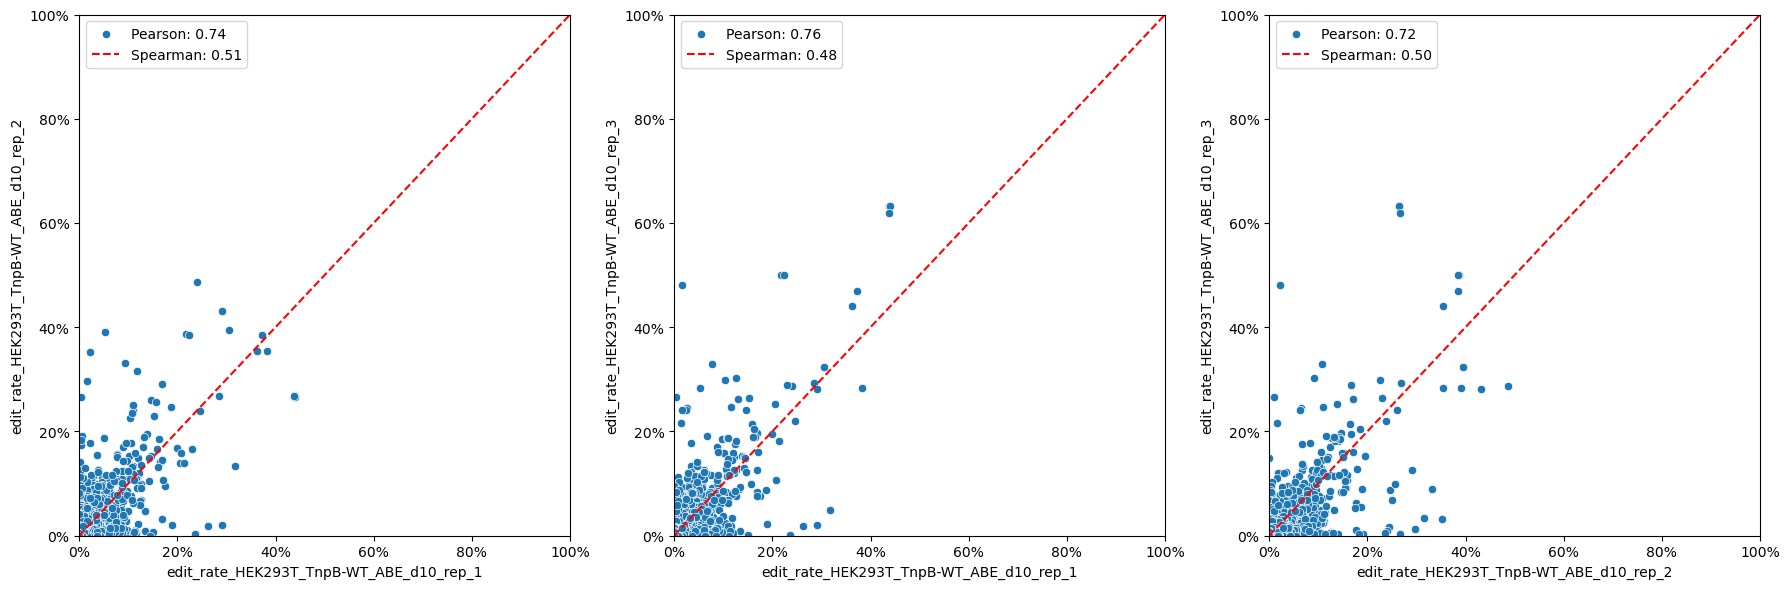

In [14]:
editor_columns=['edit_rate_HEK293T_TnpB-Var1-140_ABE_d10_rep_1',
 'edit_rate_HEK293T_TnpB-Var1-140_ABE_d10_rep_2',
 'edit_rate_HEK293T_TnpB-Var1-140_ABE_d10_rep_3',
 'edit_rate_HEK293T_TnpB-Var2-163_ABE_d10_rep_1',
 'edit_rate_HEK293T_TnpB-Var2-163_ABE_d10_rep_2',
 'edit_rate_HEK293T_TnpB-Var2-163_ABE_d10_rep_3',
 'edit_rate_HEK293T_TnpB-Var3-164_ABE_d10_rep_1',
 'edit_rate_HEK293T_TnpB-Var3-164_ABE_d10_rep_2',
 'edit_rate_HEK293T_TnpB-Var3-164_ABE_d10_rep_3',
 'edit_rate_HEK293T_TnpB-WT_ABE_d10_rep_1',
 'edit_rate_HEK293T_TnpB-WT_ABE_d10_rep_2',
 'edit_rate_HEK293T_TnpB-WT_ABE_d10_rep_3']

results_df_not_normalized_pivot_df_slim=results_df_not_normalized_pivot_df.loc[results_df_not_normalized_pivot_df["TAM_"]=="TTGAT",list(editor_columns)]
print(results_df_not_normalized_pivot_df_slim.shape)

# Iterate over every 3 columns
for i in range(0, len(results_df_not_normalized_pivot_df_slim.columns), 3):
    if i + 2 < len(results_df_not_normalized_pivot_df_slim.columns):
        col1 = results_df_not_normalized_pivot_df_slim.columns[i]
        col2 = results_df_not_normalized_pivot_df_slim.columns[i + 1]
        col3 = results_df_not_normalized_pivot_df_slim.columns[i + 2]

        test=results_df_not_normalized_pivot_df_slim[[col1,col2,col3]]
        test = test.dropna()
        plot_correlation(test, col1, col2, col3)

In [15]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

In [16]:
results_df_normalized,_ = normalize_editing_rate(results_df_not_normalized,
    col_normalize_over=['barcode','TAM','edit_position'],
    col_rate='edit_rate',
    col_control='is_ctrl',
    ignore_control=['barcode', 'TAM'],
    th_ctrl_missing=0.05,
    ctrl_edit_rate_thres=0.05
)

frac_low_num_read_in_control: 0.0. Drop these records
frac_unintendededit_in_control: 0.012427402735277588. Drop these records
305 out of 30479 sites are missing control editing rate. drop these sites


In [17]:

print(results_df_normalized.shape)
results_df_normalized = results_df_normalized[results_df_normalized['num_reads'] >= 100]     # 100,
print(results_df_normalized.shape)
results_df_normalized = results_df_normalized[results_df_normalized['edit_rate'] >= 0.00] # 0.01, if not, will see very noisy data
print(results_df_normalized.shape)
results_df_normalized.head(n=3)

(352070, 18)
(352070, 18)
(352070, 18)


,barcode,TAM,edit_position,num_reads,target_site,spacer,spacer_lib,target_site_lib,most_common_diff_target_site,most_common_diff_target_site_num,edit_rate,editor,sample_name,is_ctrl,replicate,finalname,lib_section,specific_primerpart
0,AAAAAAA,TAGAT,2,1965,AAACATTGTCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,38.0,0.000000,TnpB-WT_ABE_d10,HEK293T_TnpB-WT_ABE_d10_rep_1,False,1,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA
1,AAAAAAA,TAGAT,3,1965,AAACATTGTCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,38.0,0.000000,TnpB-WT_ABE_d10,HEK293T_TnpB-WT_ABE_d10_rep_1,False,1,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA
2,AAAAAAA,TAGAT,5,1965,AAACATTGTCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,38.0,0.001406,TnpB-WT_ABE_d10,HEK293T_TnpB-WT_ABE_d10_rep_1,False,1,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA


In [18]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

results_df_normalized=check_A_to_A_or_C(results_df_normalized)

results_df_normalized = results_df_normalized[[ 'barcode', 'TAM', 'edit_position', 'edit_rate','num_reads',"sample_name","target_site_lib","most_common_diff_target_site","valid_diff_nt"]]
results_df_normalized.head(n=3)

,barcode,TAM,edit_position,edit_rate,num_reads,sample_name,target_site_lib,most_common_diff_target_site,valid_diff_nt
0,AAAAAAA,TAGAT,2,0.000000,1965,HEK293T_TnpB-WT_ABE_d10_rep_1,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,20
1,AAAAAAA,TAGAT,3,0.000000,1965,HEK293T_TnpB-WT_ABE_d10_rep_1,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,20
2,AAAAAAA,TAGAT,5,0.001406,1965,HEK293T_TnpB-WT_ABE_d10_rep_1,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,20


In [19]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

results_df_normalized = results_df_normalized.merge(lib[['barcode', 'finalname', 'lib_section', 'specific_primerpart']], on='barcode', how='left')
# filtered_results_df=filtered_results_df.loc[filtered_results_df['valid_diff_nt'] >=18,:]
print(results_df_normalized.shape)
results_df_normalized.head(n=3)

(352070, 12)


,barcode,TAM,edit_position,edit_rate,num_reads,sample_name,target_site_lib,most_common_diff_target_site,valid_diff_nt,finalname,lib_section,specific_primerpart
0,AAAAAAA,TAGAT,2,0.000000,1965,HEK293T_TnpB-WT_ABE_d10_rep_1,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,20,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA
1,AAAAAAA,TAGAT,3,0.000000,1965,HEK293T_TnpB-WT_ABE_d10_rep_1,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,20,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA
2,AAAAAAA,TAGAT,5,0.001406,1965,HEK293T_TnpB-WT_ABE_d10_rep_1,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,20,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA


In [20]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

results_df_normalized_pivot_df = results_df_normalized.pivot_table(index=['barcode', 'TAM', 'edit_position',"target_site_lib","finalname","lib_section","specific_primerpart"],
                                           columns='sample_name',
                                           values=['edit_rate','num_reads', 'most_common_diff_target_site','valid_diff_nt'],  # values='edit_rate',
                                            aggfunc='first'
                                           ).reset_index()

results_df_normalized_pivot_df.columns = ['_'.join(col).strip() for col in results_df_normalized_pivot_df.columns.values]

print(results_df_normalized_pivot_df.shape)
results_df_normalized_pivot_df.head(n=3)

(30120, 55)


,barcode_,TAM_,edit_position_,target_site_lib_,finalname_,lib_section_,specific_primerpart_,edit_rate_HEK293T_TnpB-Var1-140_ABE_d10_rep_1,edit_rate_HEK293T_TnpB-Var1-140_ABE_d10_rep_2,edit_rate_HEK293T_TnpB-Var1-140_ABE_d10_rep_3,...,valid_diff_nt_HEK293T_TnpB-Var1-140_ABE_d10_rep_3,valid_diff_nt_HEK293T_TnpB-Var2-163_ABE_d10_rep_1,valid_diff_nt_HEK293T_TnpB-Var2-163_ABE_d10_rep_2,valid_diff_nt_HEK293T_TnpB-Var2-163_ABE_d10_rep_3,valid_diff_nt_HEK293T_TnpB-Var3-164_ABE_d10_rep_1,valid_diff_nt_HEK293T_TnpB-Var3-164_ABE_d10_rep_2,valid_diff_nt_HEK293T_TnpB-Var3-164_ABE_d10_rep_3,valid_diff_nt_HEK293T_TnpB-WT_ABE_d10_rep_1,valid_diff_nt_HEK293T_TnpB-WT_ABE_d10_rep_2,valid_diff_nt_HEK293T_TnpB-WT_ABE_d10_rep_3
0,AAAAAAA,TAGAT,2,GAACATTATCGGTATCTTGA,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA,0.000000,0.000865,0.003635,...,20.0,20.0,19.0,20.0,19.0,20.0,19.0,20.0,20.0,20.0
1,AAAAAAA,TAGAT,3,GAACATTATCGGTATCTTGA,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA,0.000036,0.000000,0.000722,...,20.0,20.0,19.0,20.0,19.0,20.0,19.0,20.0,20.0,20.0
2,AAAAAAA,TAGAT,5,GAACATTATCGGTATCTTGA,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA,0.000288,0.000000,0.000000,...,20.0,20.0,19.0,20.0,19.0,20.0,19.0,20.0,20.0,20.0


In [21]:
simple_new_columns=["HEK293T_TnpB-Var1-140_ABE_d10_rep_1","HEK293T_TnpB-Var1-140_ABE_d10_rep_2","HEK293T_TnpB-Var1-140_ABE_d10_rep_3",
             "HEK293T_TnpB-Var2-163_ABE_d10_rep_1","HEK293T_TnpB-Var2-163_ABE_d10_rep_2","HEK293T_TnpB-Var2-163_ABE_d10_rep_3",
             "HEK293T_TnpB-Var3-164_ABE_d10_rep_1","HEK293T_TnpB-Var3-164_ABE_d10_rep_2","HEK293T_TnpB-Var3-164_ABE_d10_rep_3",
             "HEK293T_TnpB-WT_ABE_d10_rep_1","HEK293T_TnpB-WT_ABE_d10_rep_2","HEK293T_TnpB-WT_ABE_d10_rep_3",
             ]
new_columns=[["edit_rate_"+c,"num_reads_"+c] for c in simple_new_columns]
new_columns=[item for sublist in new_columns for item in sublist]

results_df_normalized_pivot_df = results_df_normalized_pivot_df[[col for col in results_df_normalized_pivot_df.columns if col not in new_columns] +new_columns ]
print(results_df_normalized_pivot_df.shape)

sorting_columns=["edit_rate_"+c for c in simple_new_columns]
results_df_normalized_pivot_df = results_df_normalized_pivot_df.sort_values(by=sorting_columns, ascending=[False] * len(sorting_columns), na_position='last')
results_df_normalized_pivot_df.head(n=3)

(30120, 55)


,barcode_,TAM_,edit_position_,target_site_lib_,finalname_,lib_section_,specific_primerpart_,most_common_diff_target_site_HEK293T_TnpB-Var1-140_ABE_d10_rep_1,most_common_diff_target_site_HEK293T_TnpB-Var1-140_ABE_d10_rep_2,most_common_diff_target_site_HEK293T_TnpB-Var1-140_ABE_d10_rep_3,...,edit_rate_HEK293T_TnpB-Var3-164_ABE_d10_rep_2,num_reads_HEK293T_TnpB-Var3-164_ABE_d10_rep_2,edit_rate_HEK293T_TnpB-Var3-164_ABE_d10_rep_3,num_reads_HEK293T_TnpB-Var3-164_ABE_d10_rep_3,edit_rate_HEK293T_TnpB-WT_ABE_d10_rep_1,num_reads_HEK293T_TnpB-WT_ABE_d10_rep_1,edit_rate_HEK293T_TnpB-WT_ABE_d10_rep_2,num_reads_HEK293T_TnpB-WT_ABE_d10_rep_2,edit_rate_HEK293T_TnpB-WT_ABE_d10_rep_3,num_reads_HEK293T_TnpB-WT_ABE_d10_rep_3
6126,ATACCCA,TTAAT,18,TGTCTCATCCTAGACTCAGC,2019_MM_TTAAT_20BP_Chr5_115075108_115075746_Fw...,MM_TTAAT_20BP_,AGAGCCATTTGTCTCGCTGA,TGTCTCATCCCGATAAGGAA,TGTCTCATCCCGATAAGGAA,TGTCTCATCCCGATAAGGAA,...,0.093163,1483.0,0.428615,657.0,0.007342,907.0,0.124902,1558.0,0.521695,1201.0
6124,ATACCCA,TTAAT,12,TGTCTCATCCTAGACTCAGC,2019_MM_TTAAT_20BP_Chr5_115075108_115075746_Fw...,MM_TTAAT_20BP_,AGAGCCATTTGTCTCGCTGA,TGTCTCATCCCGATAAGGAA,TGTCTCATCCCGATAAGGAA,TGTCTCATCCCGATAAGGAA,...,0.090919,1483.0,0.429825,657.0,0.013982,907.0,0.124773,1558.0,0.522708,1201.0
22239,GTTGCCT,TTGAC,13,AATGGTTCCTGTAGCCCTAC,5883_TAM_PERMUT_TTGAC_100MEMBER_spacer_83,TAM_PERMUT_TTGAC_,AGAGCCATTTGTCTCGCTGA,AATGGTTATAAGGAAGAAAA,AATGGTTATAAGGAAGAAAA,AATGGTTATAAGGAAGAAAA,...,0.000000,1492.0,0.051959,756.0,0.000000,1172.0,0.033604,1362.0,0.000000,1082.0


In [22]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

# pivot_df.to_excel(config.result_dir / 'all-abe-samples-normalized_picked.xlsx')
# print(config.result_dir / 'all-abe-samples-normalized_picked.xlsx')

(30120, 12)


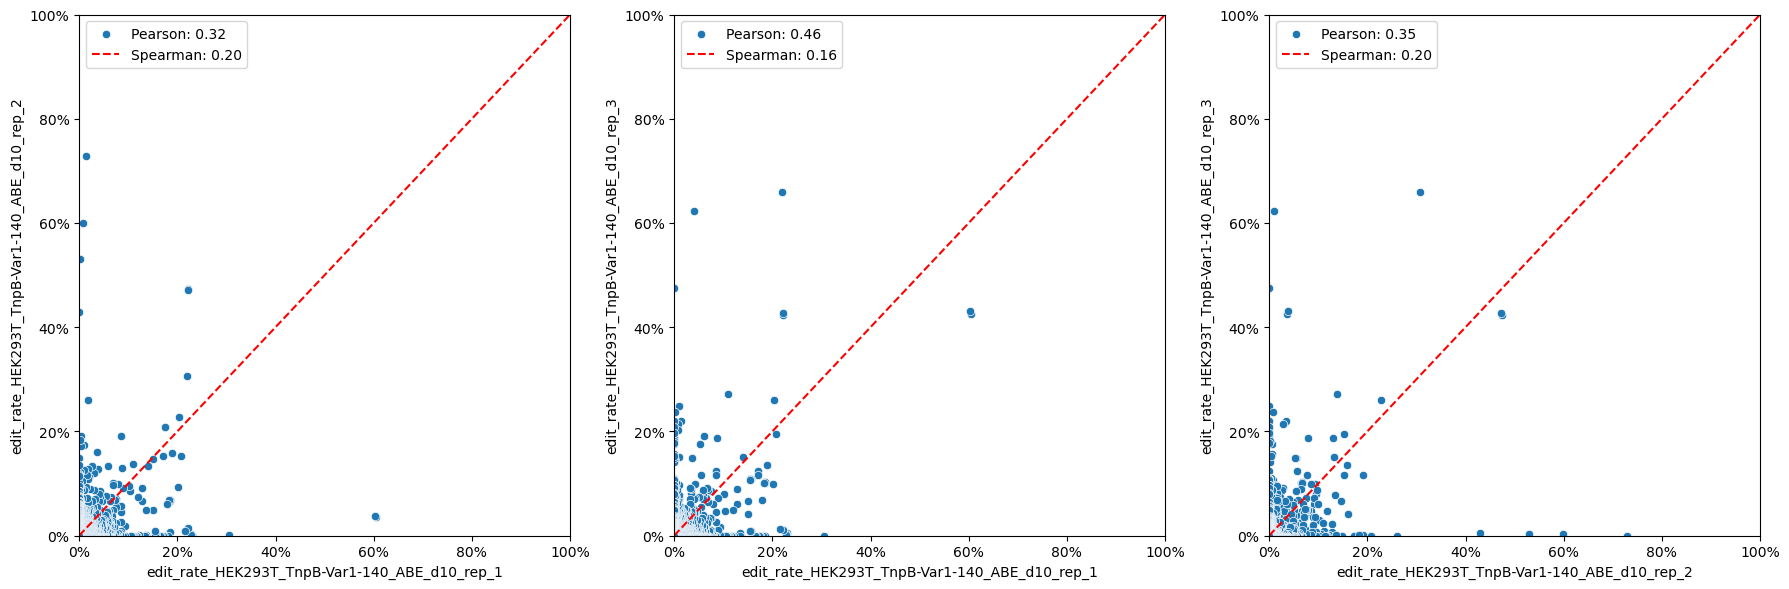

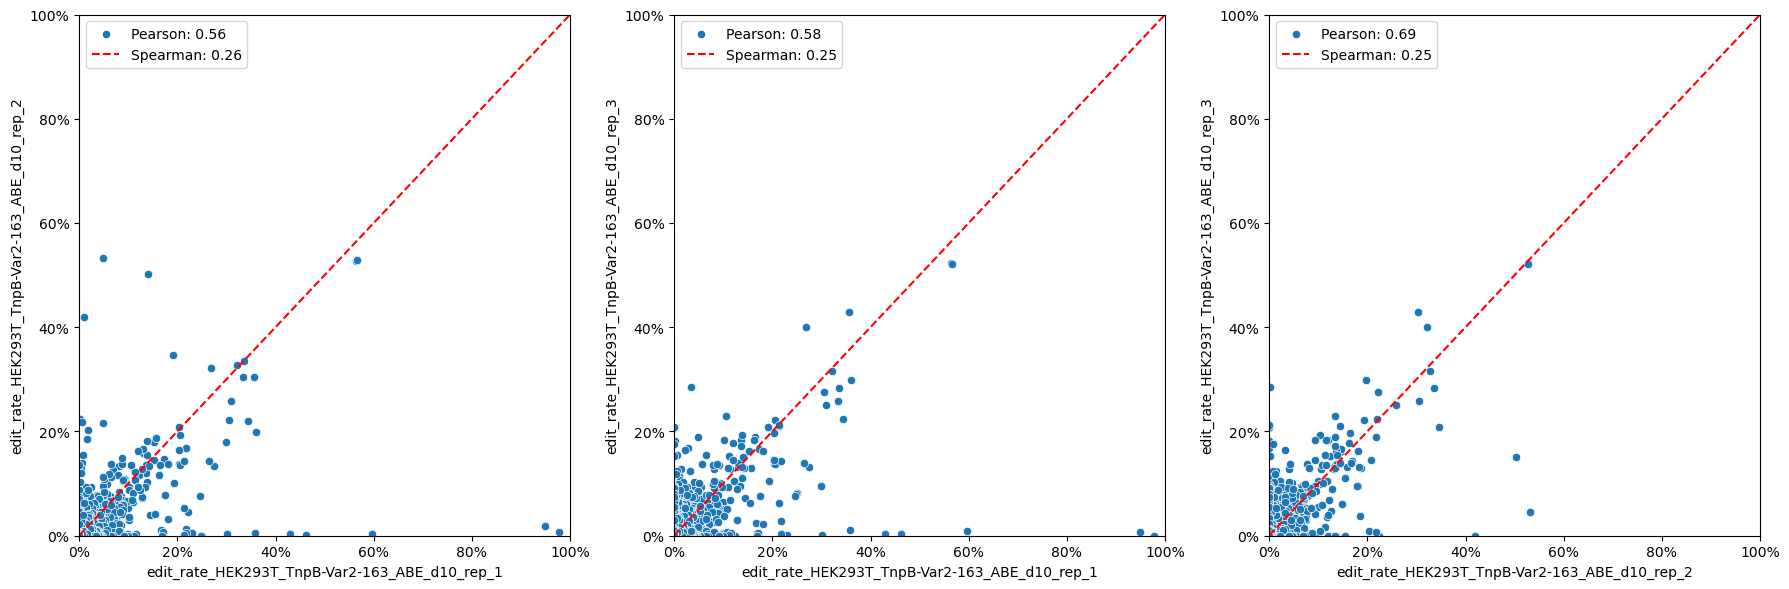

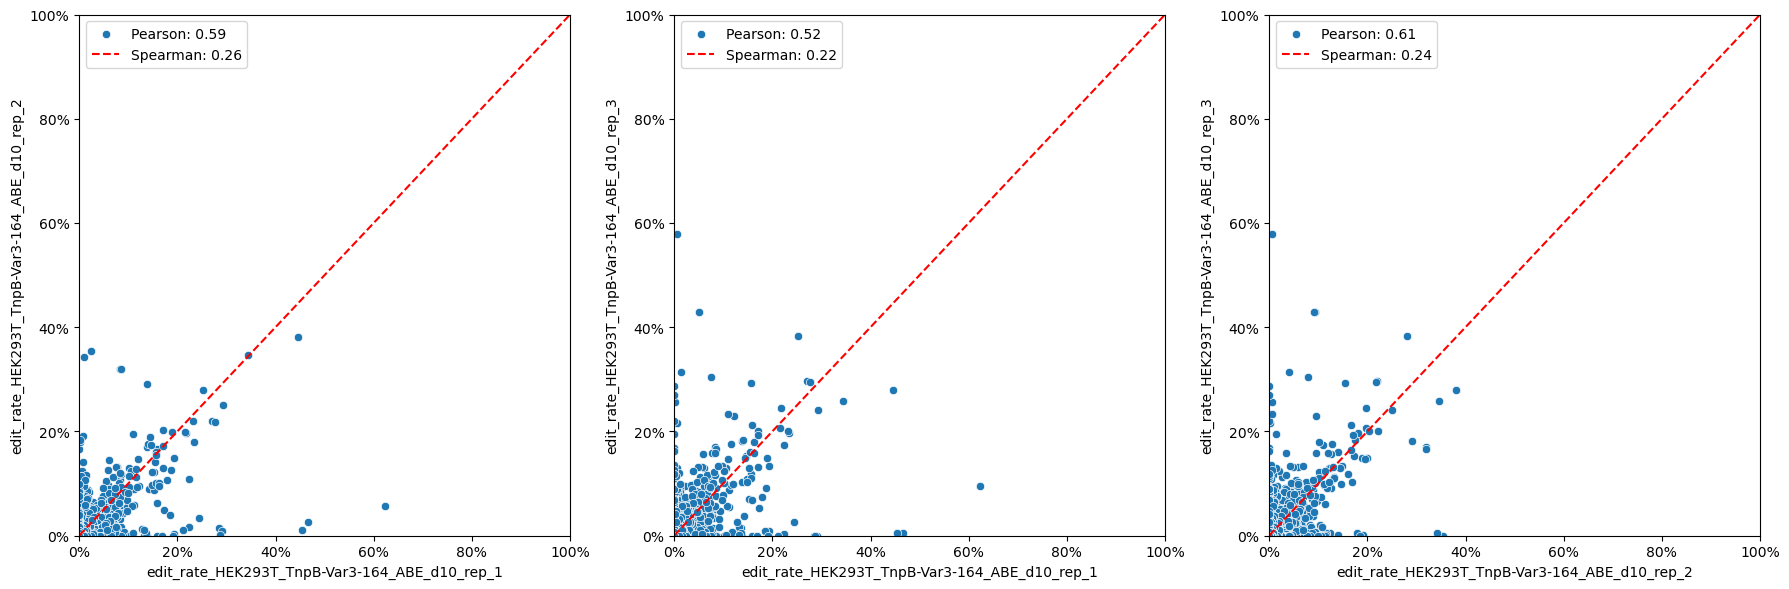

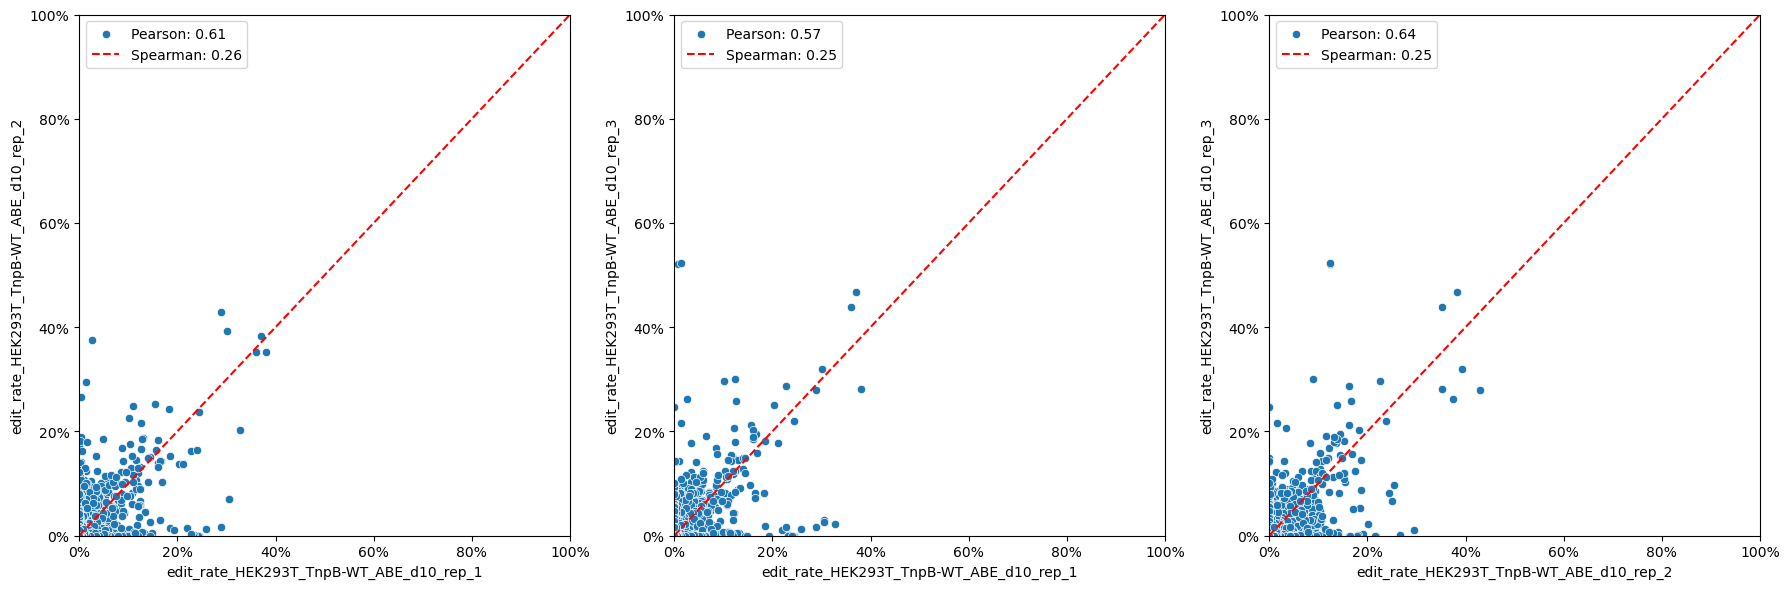

In [23]:
editor_columns=['edit_rate_HEK293T_TnpB-Var1-140_ABE_d10_rep_1',
 'edit_rate_HEK293T_TnpB-Var1-140_ABE_d10_rep_2',
 'edit_rate_HEK293T_TnpB-Var1-140_ABE_d10_rep_3',
 'edit_rate_HEK293T_TnpB-Var2-163_ABE_d10_rep_1',
 'edit_rate_HEK293T_TnpB-Var2-163_ABE_d10_rep_2',
 'edit_rate_HEK293T_TnpB-Var2-163_ABE_d10_rep_3',
 'edit_rate_HEK293T_TnpB-Var3-164_ABE_d10_rep_1',
 'edit_rate_HEK293T_TnpB-Var3-164_ABE_d10_rep_2',
 'edit_rate_HEK293T_TnpB-Var3-164_ABE_d10_rep_3',
 'edit_rate_HEK293T_TnpB-WT_ABE_d10_rep_1',
 'edit_rate_HEK293T_TnpB-WT_ABE_d10_rep_2',
 'edit_rate_HEK293T_TnpB-WT_ABE_d10_rep_3']

results_df_normalized_pivot_df_slim=results_df_normalized_pivot_df.loc[:,list(editor_columns)]
print(results_df_normalized_pivot_df_slim.shape)

# Iterate over every 3 columns
for i in range(0, len(results_df_normalized_pivot_df_slim.columns), 3):
    if i + 2 < len(results_df_normalized_pivot_df_slim.columns):
        col1 = results_df_normalized_pivot_df_slim.columns[i]
        col2 = results_df_normalized_pivot_df_slim.columns[i + 1]
        col3 = results_df_normalized_pivot_df_slim.columns[i + 2]

        test=results_df_normalized_pivot_df_slim[[col1,col2,col3]]
        test = test.dropna()
        plot_correlation(test, col1, col2, col3)

(7205, 12)


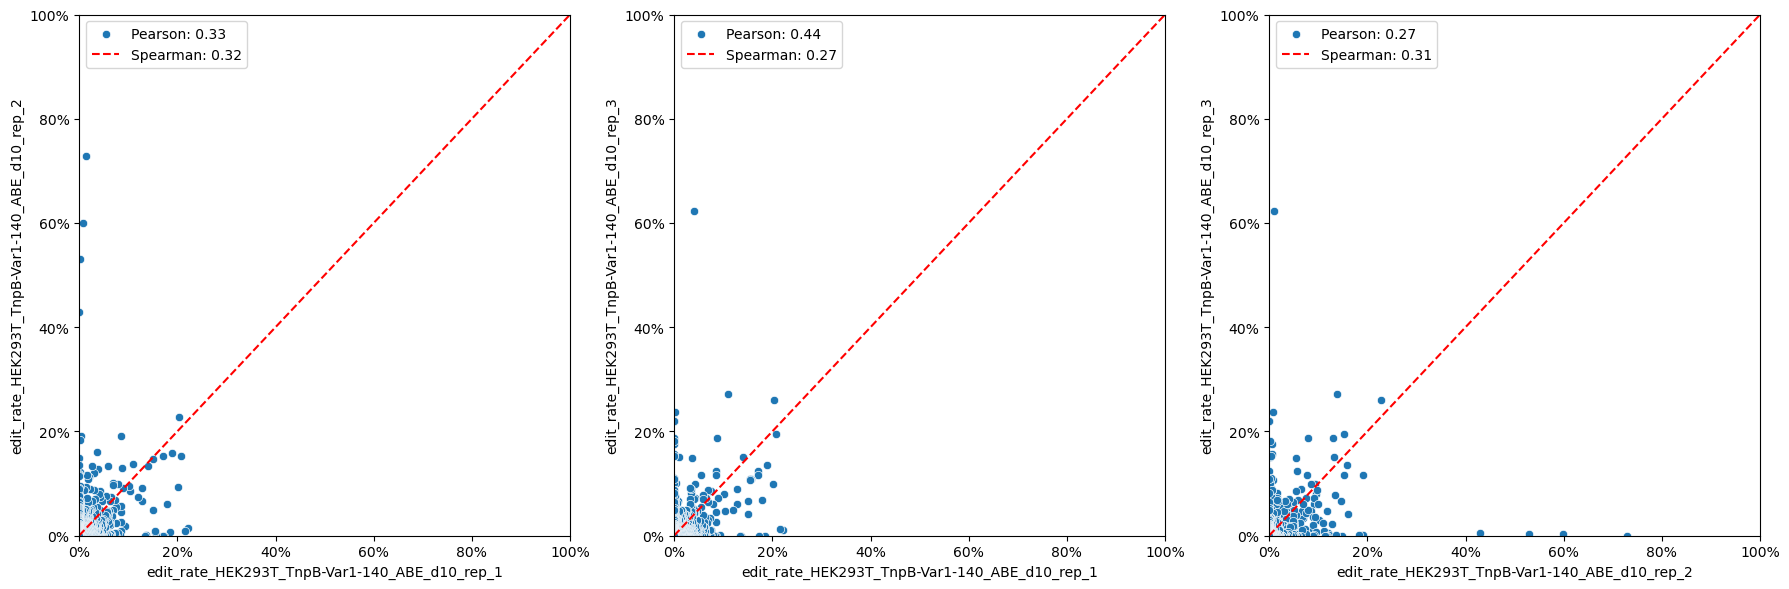

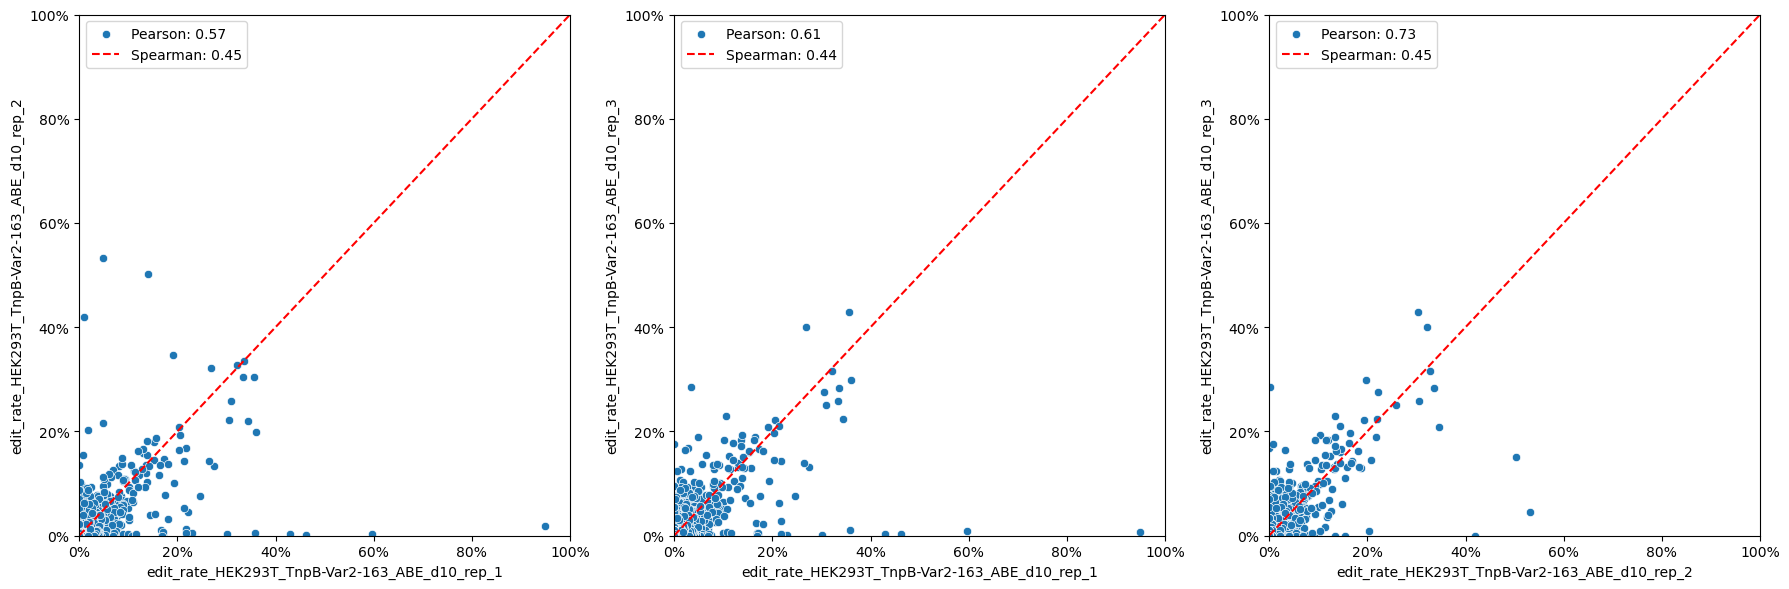

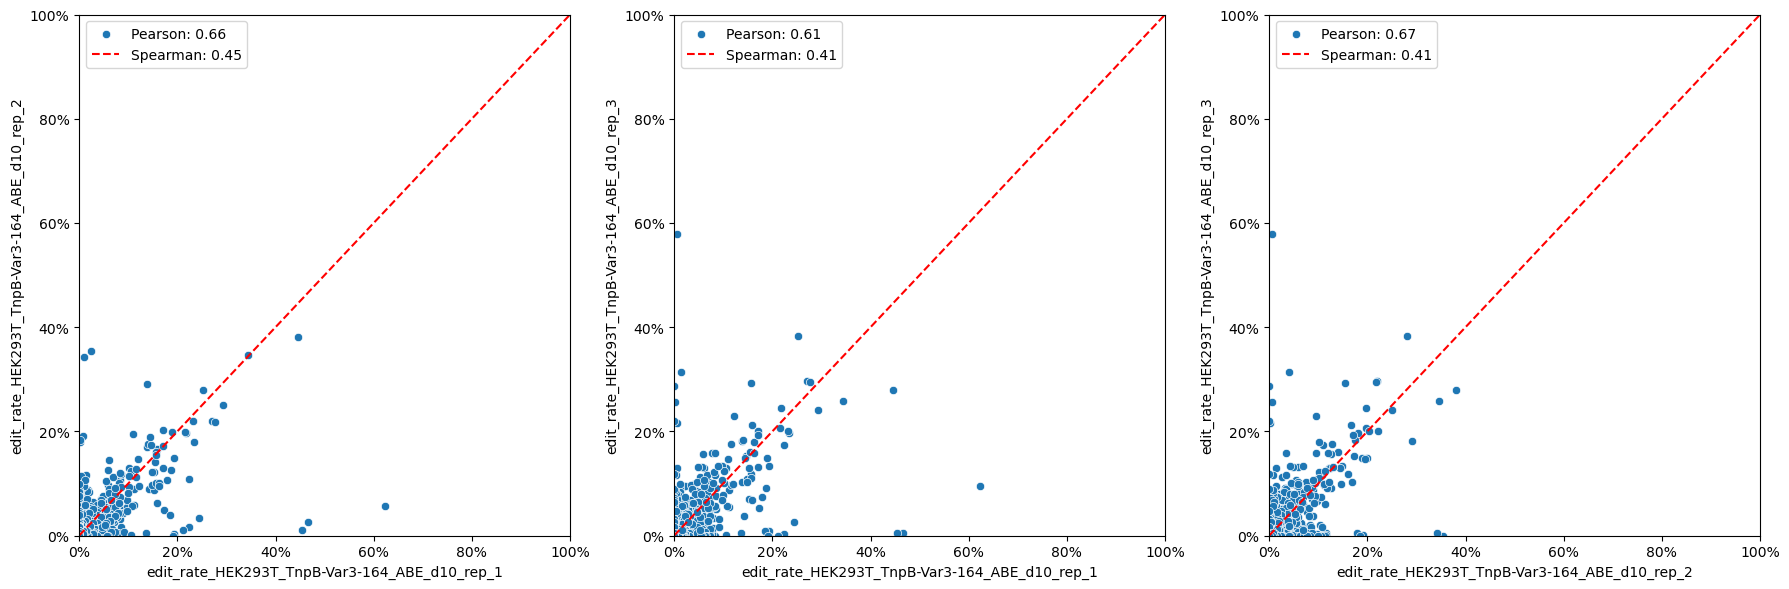

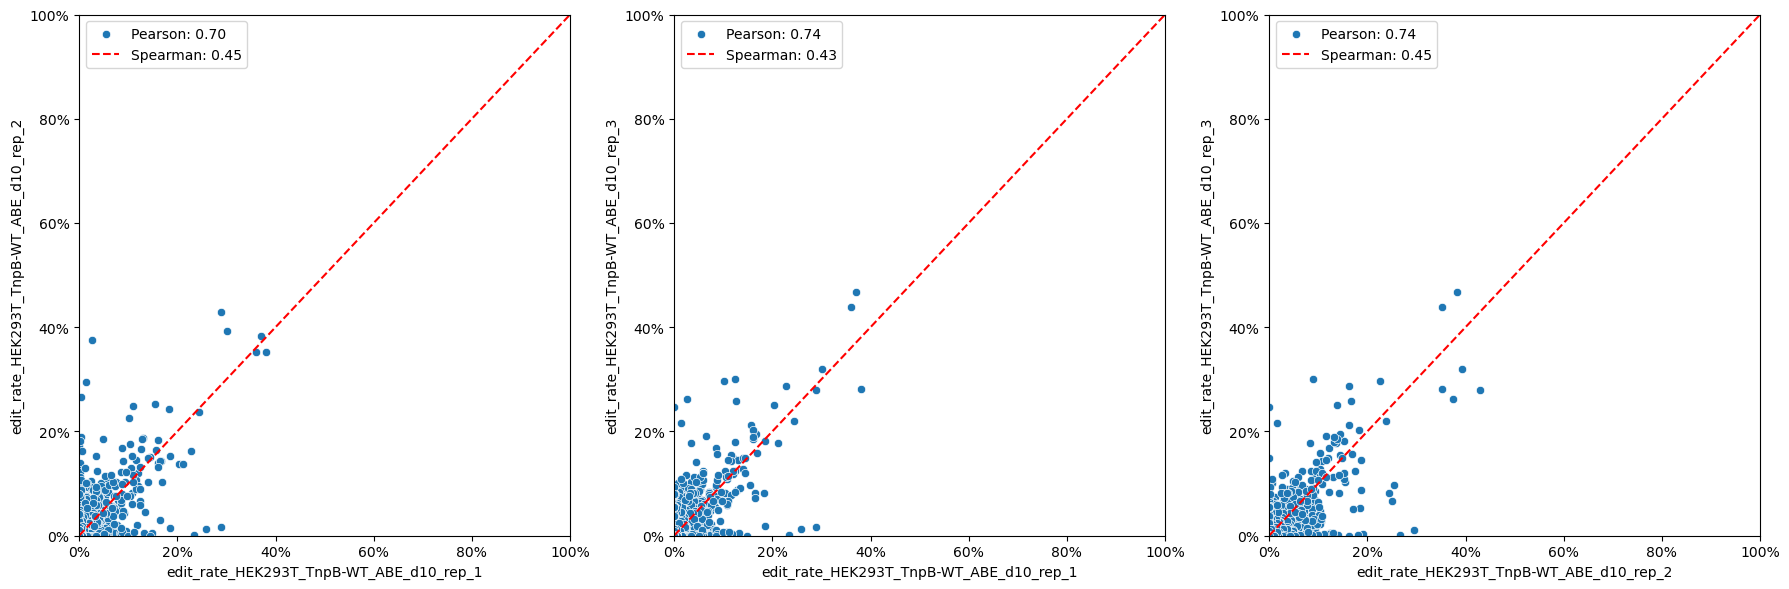

In [24]:
results_df_normalized_pivot_df_slim=results_df_normalized_pivot_df.loc[results_df_normalized_pivot_df["TAM_"]=="TTGAT",list(editor_columns)]
print(results_df_normalized_pivot_df_slim.shape)

# Iterate over every 3 columns
for i in range(0, len(results_df_normalized_pivot_df_slim.columns), 3):
    if i + 2 < len(results_df_normalized_pivot_df_slim.columns):
        col1 = results_df_normalized_pivot_df_slim.columns[i]
        col2 = results_df_normalized_pivot_df_slim.columns[i + 1]
        col3 = results_df_normalized_pivot_df_slim.columns[i + 2]

        test=results_df_normalized_pivot_df_slim[[col1,col2,col3]]
        test = test.dropna()
        plot_correlation(test, col1, col2, col3)

## check reads level quality

In [25]:
def get_abe_samples(config,sample_name_column='sample_name',editor_column='editor'):
    samples = config.get_samples()
    return samples.loc[samples[editor_column].str.contains('ABE'),:]

def collect_abe_read_edit_rates(config,sample_name_column='sample_name',editor_column='editor',control_column='control_yes_no'):
    """ Collect edit rates for all samples"""
    print('Collecting ABE edit rates for all samples')
    samples = get_abe_samples(config,sample_name_column,editor_column)
    all_sample_rates = pd.concat(
        [
            pd.read_csv(config.edit_rate(f'{sample[sample_name_column]}-reads-editedrates-unfiltered'), index_col=0).assign(
                editor=sample[editor_column],
                sample_name=sample[sample_name_column],
                is_ctrl=sample[control_column],
                replicate=sample["replicate"],
            )
            for _,sample in samples.iterrows()
        ]
    ).reset_index(drop=True)
    all_sample_rates.loc[:, 'is_ctrl'] = all_sample_rates.is_ctrl == 'yes'
    return all_sample_rates
    #all_sample_rates.to_csv(config.edit_rate('all-abe-samples-reads-editedrates-unfiltered-not-normalized'))
    

In [26]:
all_abe_samples_reads_editedrates_unfiltered_not_normalized=collect_abe_read_edit_rates(config,sample_name_column='long_name',editor_column='editor')
print(all_abe_samples_reads_editedrates_unfiltered_not_normalized.shape)

all_abe_samples_reads_editedrates_unfiltered_not_normalized.head(n=3)

(89042, 13)


,barcode,TAM,frac_reads_edited,num_reads,target_site,spacer,spacer_lib,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate
0,AAAAAAA,TAGAT,0.030534,1965,AAACATTGTCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,"[2, 3, 5, 8, 14, 20]",TnpB-WT_ABE_d10,HEK293T_TnpB-WT_ABE_d10_rep_1,False,1
1,AAAAACC,TTTAT,0.009259,324,AAGATTGGTCTTGATTTGGT,AGGATTGGTCTTGATTTGGT,AGGATTGGTCTTGATTTGGT,AGGATTGGTCTTGATTTGGT,"[1, 4, 14]",TnpB-WT_ABE_d10,HEK293T_TnpB-WT_ABE_d10_rep_1,False,1
2,AAAAATA,TTTAT,0.010676,281,TCCGGGATACATCGCAACCT,TTCGGGATACATCGCCACCT,TTCGGGATACATCGCCACCT,TTCGGGATACATCGCCACCT,"[7, 9, 11, 17]",TnpB-WT_ABE_d10,HEK293T_TnpB-WT_ABE_d10_rep_1,False,1


9036854 1319.0
8841687 1230.0
5932641 824.0


<Figure size 1200x600 with 0 Axes>

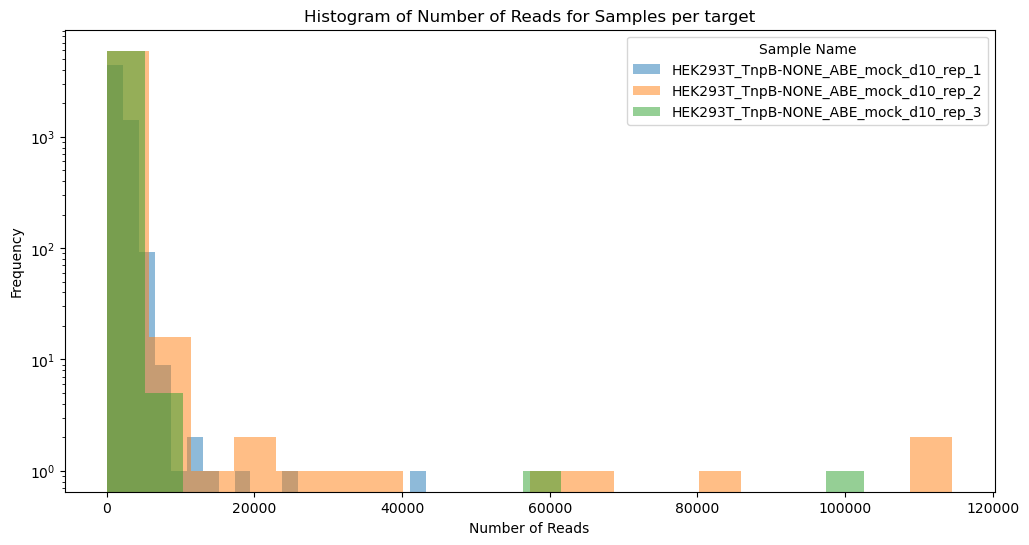

8390777 987.0
7964452 996.0
5897784 701.5


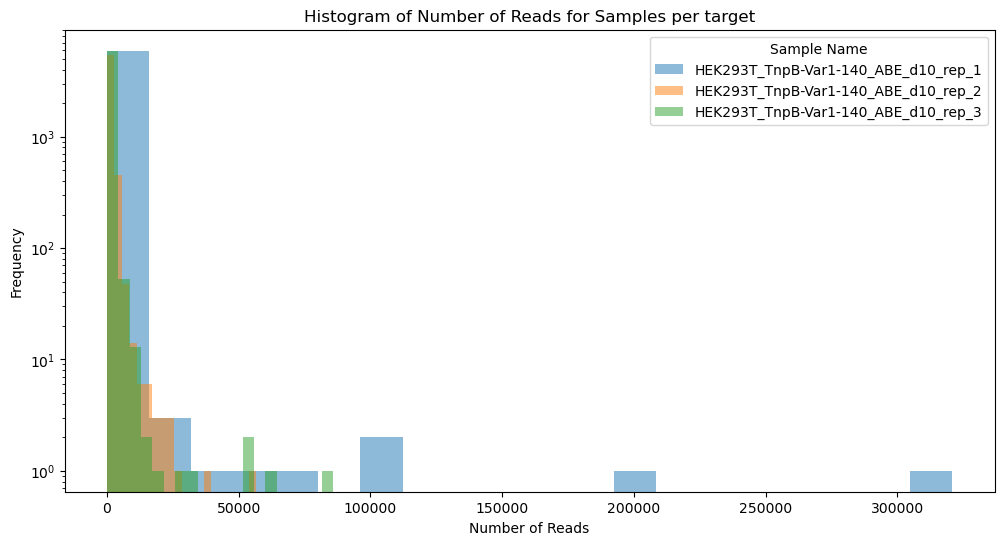

7639370 939.0
7046291 868.5
6543411 796.5


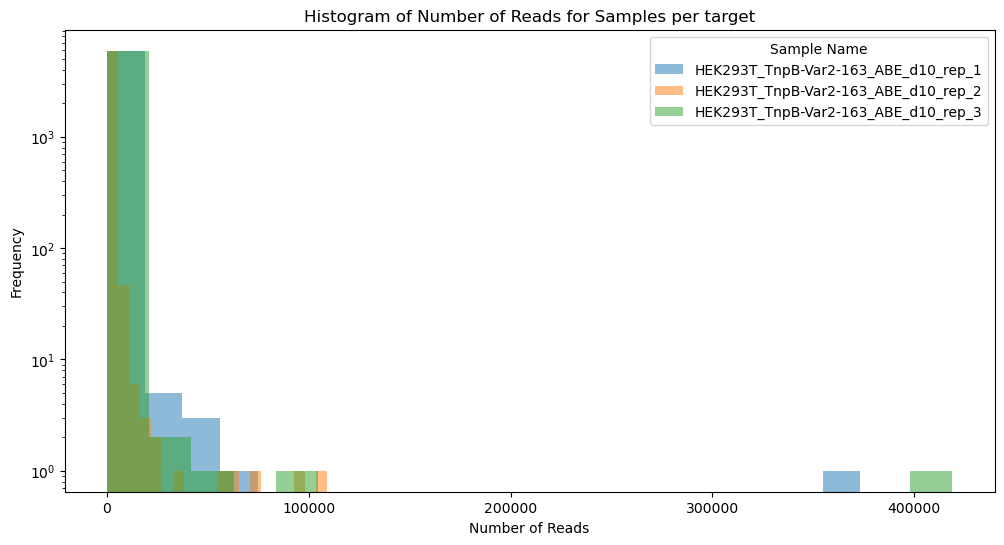

6083243 778.0
8481331 1072.0
5871113 730.0


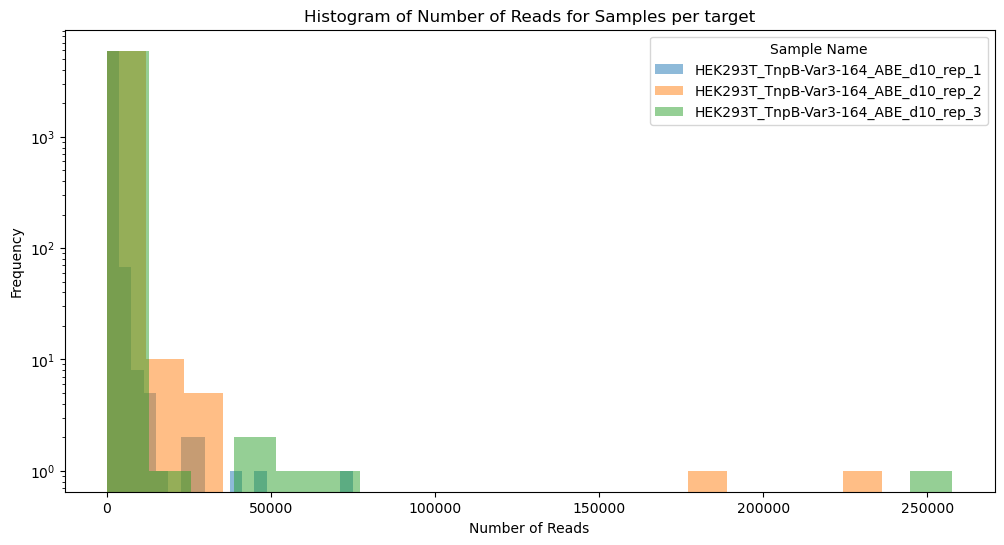

8248128 986.0
7497717 966.0
6465871 790.0


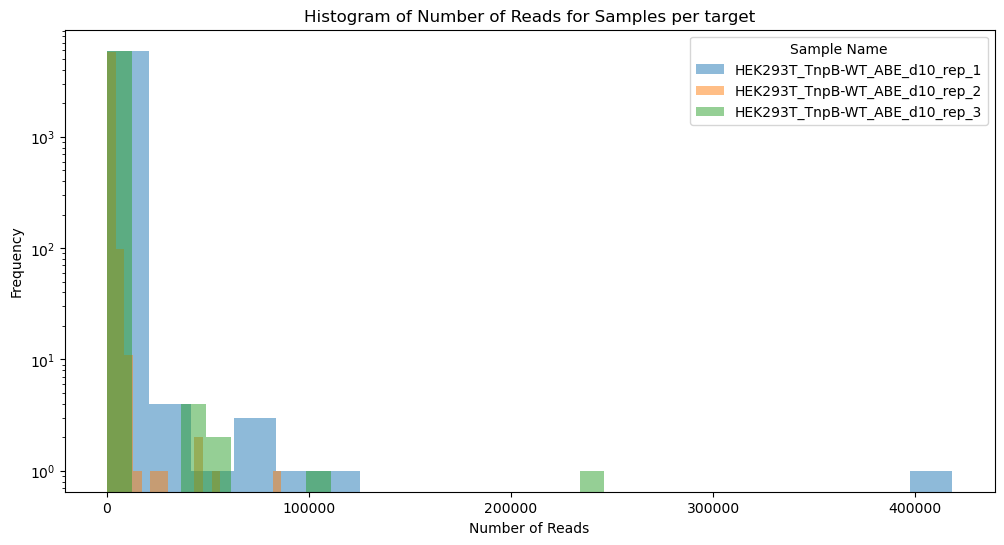

In [27]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import matplotlib.pyplot as plt

# Group by 'sample_name' and get the 'num_reads' column
grouped_data = all_abe_samples_reads_editedrates_unfiltered_not_normalized.groupby('sample_name')['num_reads']

sample_names = sorted(all_abe_samples_reads_editedrates_unfiltered_not_normalized['sample_name'].unique().tolist())

# Plot histogram for every three samples
plt.figure(figsize=(12, 6))
for i in range(0, len(sample_names), 3):
    plt.figure(figsize=(12, 6))
    for sample_name in sample_names[i:i+3]:
        num_reads = grouped_data.get_group(sample_name)
        print(num_reads.sum(),num_reads.median())
        plt.hist(num_reads, bins=20, alpha=0.5, label=sample_name)
    plt.yscale('log')
    plt.xlabel('Number of Reads')
    plt.ylabel('Frequency')
    plt.title(f'Histogram of Number of Reads for Samples per target')
    plt.legend(title='Sample Name')
    plt.show()

In [28]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_not_normalized=all_abe_samples_reads_editedrates_unfiltered_not_normalized.\
        loc[(all_abe_samples_reads_editedrates_unfiltered_not_normalized['num_reads'] >= 200) ]
print(all_abe_samples_reads_editedrates_not_normalized.shape)

# &
#         (all_abe_samples_reads_editedrates_unfiltered_not_normalized['valid_diff_nt'] >=0)

(76116, 13)


In [29]:
all_abe_samples_reads_editedrates_not_normalized_pivot_df = all_abe_samples_reads_editedrates_not_normalized.pivot_table(index=['barcode', 'TAM', "target_site_lib"],
                                           columns='sample_name',
                                           values=['frac_reads_edited','num_reads'],  # values='edit_rate',
                                            aggfunc='first'
                                           ).reset_index()

all_abe_samples_reads_editedrates_not_normalized_pivot_df.columns = ['_'.join(col).strip() for col in all_abe_samples_reads_editedrates_not_normalized_pivot_df.columns.values]

print(all_abe_samples_reads_editedrates_not_normalized_pivot_df.shape)
all_abe_samples_reads_editedrates_not_normalized_pivot_df

(5539, 33)


,barcode_,TAM_,target_site_lib_,frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_1,frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_2,frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_3,frac_reads_edited_HEK293T_TnpB-Var1-140_ABE_d10_rep_1,frac_reads_edited_HEK293T_TnpB-Var1-140_ABE_d10_rep_2,frac_reads_edited_HEK293T_TnpB-Var1-140_ABE_d10_rep_3,frac_reads_edited_HEK293T_TnpB-Var2-163_ABE_d10_rep_1,...,num_reads_HEK293T_TnpB-Var1-140_ABE_d10_rep_3,num_reads_HEK293T_TnpB-Var2-163_ABE_d10_rep_1,num_reads_HEK293T_TnpB-Var2-163_ABE_d10_rep_2,num_reads_HEK293T_TnpB-Var2-163_ABE_d10_rep_3,num_reads_HEK293T_TnpB-Var3-164_ABE_d10_rep_1,num_reads_HEK293T_TnpB-Var3-164_ABE_d10_rep_2,num_reads_HEK293T_TnpB-Var3-164_ABE_d10_rep_3,num_reads_HEK293T_TnpB-WT_ABE_d10_rep_1,num_reads_HEK293T_TnpB-WT_ABE_d10_rep_2,num_reads_HEK293T_TnpB-WT_ABE_d10_rep_3
0,AAAAAAA,TAGAT,GAACATTATCGGTATCTTGA,0.018647,0.011130,0.012163,0.014044,0.017984,0.018839,0.015426,...,1964.0,1880.0,2071.0,1828.0,1646.0,2574.0,2054.0,1965.0,1910.0,2400.0
1,AAAAACC,TTTAT,AGGATTGGTCTTGATTTGGT,0.002288,0.000000,0.018405,0.012136,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,203.0,324.0,225.0,344.0
2,AAAAATA,TTTAT,TTCGGGATACATCGCCACCT,0.002217,0.007160,0.010000,NaN,NaN,NaN,0.012500,...,NaN,240.0,NaN,282.0,NaN,283.0,NaN,281.0,NaN,NaN
3,AAAAATG,TTCAT,GGTGAAGTTGGTTTCAAACG,0.015066,0.013208,0.014463,0.012903,0.026201,0.015060,0.010417,...,332.0,288.0,218.0,433.0,238.0,346.0,265.0,312.0,280.0,313.0
4,AAAACAA,TTGAT,GGAGTACACCTCACGAAGGG,0.020390,0.035320,0.031484,0.103911,0.034549,0.049180,0.175234,...,549.0,856.0,749.0,1122.0,687.0,958.0,518.0,992.0,799.0,688.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5534,TTTTTAG,ATGAT,GTAAGTAAGGCATAGCGTGT,0.013580,0.010657,0.014218,0.032290,0.010204,0.007987,0.008092,...,626.0,865.0,986.0,690.0,815.0,1208.0,785.0,1053.0,1178.0,1054.0
5535,TTTTTCA,TTAAT,CCTGTCTAAGCAGGGAAGCC,0.017258,0.012762,0.014344,0.013099,0.010948,0.013362,0.004561,...,1871.0,2631.0,4118.0,1554.0,1758.0,1779.0,1268.0,3819.0,3047.0,749.0
5536,TTTTTCG,TTTAT,GCATTCAAGCAAATCCCTAA,0.020972,0.019588,0.016393,0.012161,0.008945,0.012069,0.004454,...,580.0,1347.0,740.0,753.0,878.0,1090.0,911.0,1053.0,966.0,681.0
5537,TTTTTGT,TTAAT,GTAGCGTGTAATAATTTCGG,0.006595,0.008547,0.011199,0.009353,0.012614,0.017296,0.016455,...,1272.0,1337.0,1538.0,1294.0,2062.0,1669.0,1432.0,1813.0,2465.0,1641.0


In [30]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df=all_abe_samples_reads_editedrates_not_normalized_pivot_df.copy()
# all_abe_samples_reads_editedrates_not_normalized_pivot_df[['barcode_','TAM_','target_site_lib_','frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_1',
#                 'frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_2',
#                 'frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_3',]]

mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df = mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df[
    (
        (mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df['frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_1'] > 0.1).astype(int) +
        (mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df['frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_2'] > 0.1).astype(int) +
        (mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df['frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_3'] > 0.1).astype(int)
    ) >= 2
]

mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df = mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df.merge(lib, left_on='barcode_', right_on='barcode', how='left', suffixes=('', '_lib'))

mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df

,barcode_,TAM_,target_site_lib_,frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_1,frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_2,frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_3,frac_reads_edited_HEK293T_TnpB-Var1-140_ABE_d10_rep_1,frac_reads_edited_HEK293T_TnpB-Var1-140_ABE_d10_rep_2,frac_reads_edited_HEK293T_TnpB-Var1-140_ABE_d10_rep_3,frac_reads_edited_HEK293T_TnpB-Var2-163_ABE_d10_rep_1,...,lib_section,specific_primerpart,barcode,spacer,oligofinal,length,target_site_rc,target_site,TAM_rc,TAM
0,AAAATCT,TTGAT,GACCTGGAGATGAAAAGGGA,0.107034,0.099875,0.156291,0.074018,0.087838,0.138340,0.255624,...,MM_TTGAT_20BP_,AGAGCCATTTGTCTCGCTGA,AAAATCT,GACCTGGAGATGAAAAGGGA,GACTTTAGTCGTGTGAGGTTCAAGACCTGGAGATGAAAAGGGAGGC...,200,TCCCTTTTCATCTCCAGGTC,GACCTGGAGATGAAAAGGGA,ATCAA,TTGAT
1,AACGCAT,TTTAT,GTGATTCTTATGCCGGAAGT,0.166038,0.188136,0.171429,0.036269,0.032500,0.008333,0.029730,...,MM_ENDO_TTTAT_20BP_,AGAGCCATTTGTCTCGCTGA,AACGCAT,GTGATTCTTATGCCGGAAGT,GACTTTAGTCGTGTGAGGTTCAAGTGATTCTTATGCCGGAAGTGGC...,200,ACTTCCGGCATAAGAATCAC,GTGATTCTTATGCCGGAAGT,ATAAA,TTTAT
2,AACGTCG,TTAAT,AAATTGGACCAAATAGACAA,0.114577,0.097616,0.126119,0.256954,0.116822,0.065543,0.136331,...,MM_TTAAT_20BP_,AGAGCCATTTGTCTCGCTGA,AACGTCG,AAATTGGACCAAATAGACAA,GACTTTAGTCGTGTGAGGTTCAAAAATTGGACCAAATAGACAAGGC...,200,TTGTCTATTTGGTCCAATTT,AAATTGGACCAAATAGACAA,ATTAA,TTAAT
3,AACTGAA,TTGAC,TGAAGATCATTAGTGAGCGA,0.285071,0.161455,0.396825,0.082414,0.214208,0.141783,0.114483,...,TAM_PERMUT_TTGAC_,AGAGCCATTTGTCTCGCTGA,AACTGAA,TGAAGATCATTAGTGAGCGA,GACTTTAGTCGTGTGAGGTTCAATGAAGATCATTAGTGAGCGAGGC...,200,TCGCTCACTAATGATCTTCA,TGAAGATCATTAGTGAGCGA,GTCAA,TTGAC
4,AAGGAAC,TTCAT,TAAAAGTCCATCATTTGCAA,0.198985,0.180809,0.208775,0.083916,0.088089,0.216710,0.092760,...,MM_TTCAT_20BP_,AGAGCCATTTGTCTCGCTGA,AAGGAAC,TAAAAGTCCATCATTTGCAA,GACTTTAGTCGTGTGAGGTTCAATAAAAGTCCATCATTTGCAAGGC...,200,TTGCAAATGATGGACTTTTA,TAAAAGTCCATCATTTGCAA,ATGAA,TTCAT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101,TGGCTGT,TTGAT,GCATGATACCTTCTACTCAG,0.103107,0.094760,0.115854,0.046326,0.075305,0.043084,0.069100,...,MM_TTGAT_20BP_,AGAGCCATTTGTCTCGCTGA,TGGCTGT,GCATGATACCTTCTACTCAG,GACTTTAGTCGTGTGAGGTTCAAGCATGATACCTTCTACTCAGGGC...,200,CTGAGTAGAAGGTATCATGC,GCATGATACCTTCTACTCAG,ATCAA,TTGAT
102,TGTGGCA,TTCAT,TGAGGGCTCAGCCCTCGGAA,0.271429,0.279778,0.100295,NaN,NaN,NaN,0.313084,...,MM_TTCAT_20BP_,AGAGCCATTTGTCTCGCTGA,TGTGGCA,TGAGGGCTCAGCCCTCGGAA,GACTTTAGTCGTGTGAGGTTCAATGAGGGCTCAGCCCTCGGAAGGC...,200,TTCCGAGGGCTGAGCCCTCA,TGAGGGCTCAGCCCTCGGAA,ATGAA,TTCAT
103,TGTGGTG,TTCAT,AGATCTGTGTCCCACATGCT,0.160321,0.134680,NaN,0.101010,NaN,0.013072,0.086957,...,MM_TTCAT_20BP_,AGAGCCATTTGTCTCGCTGA,TGTGGTG,AGATCTGTGTCCCACATGCT,GACTTTAGTCGTGTGAGGTTCAAAGATCTGTGTCCCACATGCTGGC...,200,AGCATGTGGGACACAGATCT,AGATCTGTGTCCCACATGCT,ATGAA,TTCAT
104,TTAAGCT,TTGAT,GGGTAGAAAATTGAGTTGAA,0.121413,0.144469,0.105630,0.052200,0.164186,0.098381,0.137798,...,MM_TTGAT_20BP_,AGAGCCATTTGTCTCGCTGA,TTAAGCT,GGGTAGAAAATTGAGTTGAA,GACTTTAGTCGTGTGAGGTTCAAGGGTAGAAAATTGAGTTGAAGGC...,200,TTCAACTCAATTTTCTACCC,GGGTAGAAAATTGAGTTGAA,ATCAA,TTGAT


In [31]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df=all_abe_samples_reads_editedrates_not_normalized_pivot_df.copy()

mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df = mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df[
    (
        (mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df['frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_1'] > 0.05).astype(int) +
        (mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df['frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_2'] > 0.05).astype(int) +
        (mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df['frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_3'] > 0.05).astype(int)
    ) >= 2
]

mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df = mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df.merge(lib, left_on='barcode_', right_on='barcode', how='left', suffixes=('', '_lib'))

mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df

,barcode_,TAM_,target_site_lib_,frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_1,frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_2,frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_3,frac_reads_edited_HEK293T_TnpB-Var1-140_ABE_d10_rep_1,frac_reads_edited_HEK293T_TnpB-Var1-140_ABE_d10_rep_2,frac_reads_edited_HEK293T_TnpB-Var1-140_ABE_d10_rep_3,frac_reads_edited_HEK293T_TnpB-Var2-163_ABE_d10_rep_1,...,lib_section,specific_primerpart,barcode,spacer,oligofinal,length,target_site_rc,target_site,TAM_rc,TAM
0,AAAATCT,TTGAT,GACCTGGAGATGAAAAGGGA,0.107034,0.099875,0.156291,0.074018,0.087838,0.138340,0.255624,...,MM_TTGAT_20BP_,AGAGCCATTTGTCTCGCTGA,AAAATCT,GACCTGGAGATGAAAAGGGA,GACTTTAGTCGTGTGAGGTTCAAGACCTGGAGATGAAAAGGGAGGC...,200,TCCCTTTTCATCTCCAGGTC,GACCTGGAGATGAAAAGGGA,ATCAA,TTGAT
1,AAACTAC,TTCAT,TTCTACCATACTGGGTAGGG,0.096539,0.099254,0.103701,0.018729,0.033138,0.071512,0.054647,...,TAM_PERMUT_TTCAT_,AGAGCCATTTGTCTCGCTGA,AAACTAC,TTCTACCATACTGGGTAGGG,GACTTTAGTCGTGTGAGGTTCAATTCTACCATACTGGGTAGGGGGC...,200,CCCTACCCAGTATGGTAGAA,TTCTACCATACTGGGTAGGG,ATGAA,TTCAT
2,AAACTTA,TTGAT,AAAATGTCTTCTTGAGTGTT,0.052983,0.074809,0.100427,0.013542,0.067197,0.031279,0.026689,...,MM_TTGAT_20BP_,AGAGCCATTTGTCTCGCTGA,AAACTTA,AAAATGTCTTCTTGAGTGTT,GACTTTAGTCGTGTGAGGTTCAAAAAATGTCTTCTTGAGTGTTGGC...,200,AACACTCAAGAAGACATTTT,AAAATGTCTTCTTGAGTGTT,ATCAA,TTGAT
3,AAAGCTC,TTGAT,CATGGACAGAGAGTCAGGAA,0.052328,0.064402,0.067612,0.041685,0.067541,0.047049,0.058920,...,MM_TTGAT_20BP_,AGAGCCATTTGTCTCGCTGA,AAAGCTC,CATGGACAGAGAGTCAGGAA,GACTTTAGTCGTGTGAGGTTCAACATGGACAGAGAGTCAGGAAGGC...,200,TTCCTGACTCTCTGTCCATG,CATGGACAGAGAGTCAGGAA,ATCAA,TTGAT
4,AAATACC,TTTAT,GCCTACATGAAAGTAAGTGC,0.095794,0.131113,0.020501,0.127753,0.142544,0.021186,0.157119,...,MM_ENDO_TTTAT_20BP_,AGAGCCATTTGTCTCGCTGA,AAATACC,GCCTACATGAAAGTAAGTGC,GACTTTAGTCGTGTGAGGTTCAAGCCTACATGAAAGTAAGTGCGGC...,200,GCACTTACTTTCATGTAGGC,GCCTACATGAAAGTAAGTGC,ATAAA,TTTAT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,TTCTATA,TTGTT,TCAGGTGGCGCGCTCCTATA,0.061275,0.040877,0.073650,0.050095,0.032151,0.026022,0.044604,...,TAM_PERMUT_TTGTT_,AGAGCCATTTGTCTCGCTGA,TTCTATA,TCAGGTGGCGCGCTCCTATA,GACTTTAGTCGTGTGAGGTTCAATCAGGTGGCGCGCTCCTATAGGC...,200,TATAGGAGCGCGCCACCTGA,TCAGGTGGCGCGCTCCTATA,AACAA,TTGTT
299,TTCTGCA,TTGAT,AGGCAATGGATTTAGGACAG,0.068579,0.037267,0.102199,0.037804,0.073696,0.020193,0.060241,...,MM_TTGAT_20BP_,AGAGCCATTTGTCTCGCTGA,TTCTGCA,AGGCAATGGATTTAGGACAG,GACTTTAGTCGTGTGAGGTTCAAAGGCAATGGATTTAGGACAGGGC...,200,CTGTCCTAAATCCATTGCCT,AGGCAATGGATTTAGGACAG,ATCAA,TTGAT
300,TTCTTAA,TTGAG,TCAGGTGGCGCGCTCCTATA,0.075388,0.052732,0.068477,0.070549,0.054363,0.071902,0.060052,...,TAM_PERMUT_TTGAG_,AGAGCCATTTGTCTCGCTGA,TTCTTAA,TCAGGTGGCGCGCTCCTATA,GACTTTAGTCGTGTGAGGTTCAATCAGGTGGCGCGCTCCTATAGGC...,200,TATAGGAGCGCGCCACCTGA,TCAGGTGGCGCGCTCCTATA,CTCAA,TTGAG
301,TTTATAA,TTTAT,GAGTTGCCAAGGTCATGATG,0.090708,0.191860,NaN,0.021858,0.048780,NaN,0.195212,...,MM_ENDO_TTTAT_20BP_,AGAGCCATTTGTCTCGCTGA,TTTATAA,GAGTTGCCAAGGTCATGATG,GACTTTAGTCGTGTGAGGTTCAAGAGTTGCCAAGGTCATGATGGGC...,200,CATCATGACCTTGGCAACTC,GAGTTGCCAAGGTCATGATG,ATAAA,TTTAT


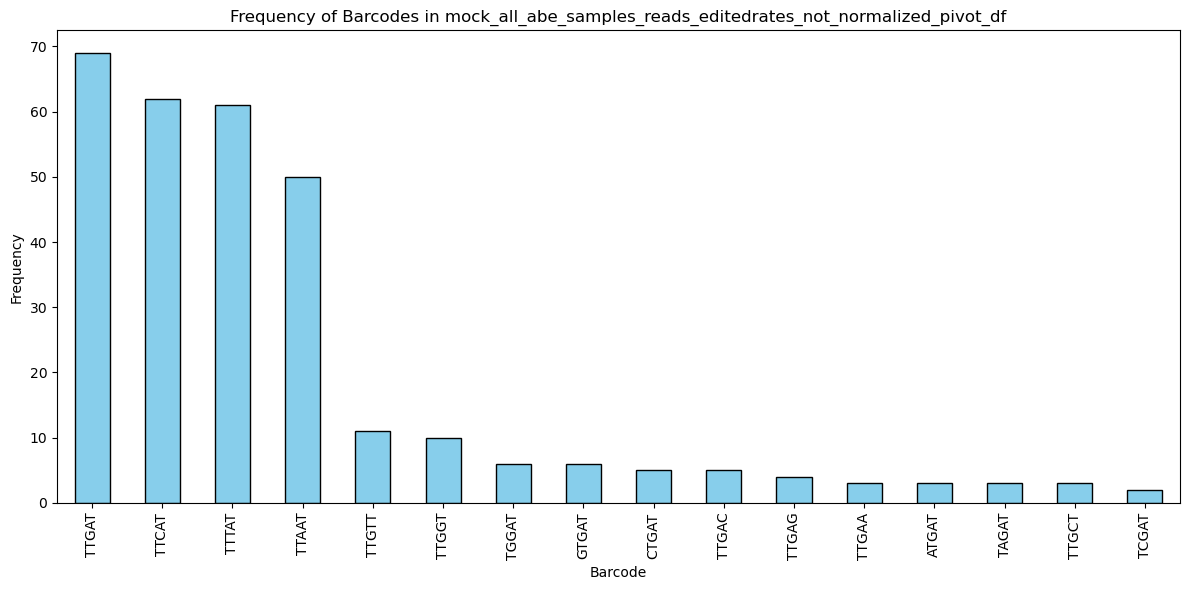

In [32]:
import matplotlib.pyplot as plt

# Count the frequency of each barcode
barcode_counts = mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df['TAM_'].value_counts()

# Plot the frequency
plt.figure(figsize=(12, 6))
barcode_counts.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Frequency of Barcodes in mock_all_abe_samples_reads_editedrates_not_normalized_pivot_df')
plt.xlabel('Barcode')
plt.ylabel('Frequency')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [33]:
o = pd.read_csv(config.outcomes("HEK293T_TnpB-NONE_ABE_mock_d10_rep_1"), index_col=0)
edited_spacer="target_site"
col_ref_spacer='target_site_lib'
cols_groupby=['barcode',"TAM"]
col_edit_rate = 'frac_reads_edited'
o

,barcode,target_site,TAM,spacer,spacer_lib,target_site_lib,num_reads
0,AAAAAAA,AAACATTATCGGTATCTTGA,TAGAT,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,5
1,AAAAAAA,GAACACTATCGGTATCTTGA,TAGAT,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,6
2,AAAAAAA,GAACACTATCGGTATCTTGG,TAGAT,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,1
3,AAAAAAA,GAACACTCTCGGTATCTTGA,TAGAT,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,1
4,AAAAAAA,GAACATCATCGGTATCTTGA,TAGAT,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,5
...,...,...,...,...,...,...,...
205236,TTTTTTT,TAGGGTTGGTGTGTGAAGAA,TTTAT,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,3
205237,TTTTTTT,TCAGGTTGGTGTGAGAAGAA,TTTAT,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,1
205238,TTTTTTT,TCAGGTTGGTGTGTGAAGAA,TTTAT,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,1
205239,TTTTTTT,TCAGGTTGGTGTGTGAAGAG,TTTAT,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,1


In [34]:
df=o.copy()
def read_level_check_A_to_A_or_C(df):
    df['valid_diff_nt'] = df.apply(lambda row: sum(tsl == ts or (tsl == 'A' and ts in ['C', 'G']) for tsl, ts in zip(row['target_site_lib'], row['target_site'])), axis=1)
    return df
df=read_level_check_A_to_A_or_C(df)
df['edit_positions'] = df[col_ref_spacer].apply(lambda s: [i+1 for i, b in enumerate(s) if b == "A"])
df['read_edited'] = df.apply(lambda row: any(row[edited_spacer][i-1] == "G" for i in row['edit_positions']), axis=1)
df

,barcode,target_site,TAM,spacer,spacer_lib,target_site_lib,num_reads,valid_diff_nt,edit_positions,read_edited
0,AAAAAAA,AAACATTATCGGTATCTTGA,TAGAT,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,5,19,"[2, 3, 5, 8, 14, 20]",False
1,AAAAAAA,GAACACTATCGGTATCTTGA,TAGAT,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,6,19,"[2, 3, 5, 8, 14, 20]",False
2,AAAAAAA,GAACACTATCGGTATCTTGG,TAGAT,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,1,19,"[2, 3, 5, 8, 14, 20]",True
3,AAAAAAA,GAACACTCTCGGTATCTTGA,TAGAT,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,1,19,"[2, 3, 5, 8, 14, 20]",False
4,AAAAAAA,GAACATCATCGGTATCTTGA,TAGAT,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,5,19,"[2, 3, 5, 8, 14, 20]",False
...,...,...,...,...,...,...,...,...,...,...
205236,TTTTTTT,TAGGGTTGGTGTGTGAAGAA,TTTAT,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,3,20,"[2, 3, 16, 17, 19, 20]",True
205237,TTTTTTT,TCAGGTTGGTGTGAGAAGAA,TTTAT,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,1,19,"[2, 3, 16, 17, 19, 20]",False
205238,TTTTTTT,TCAGGTTGGTGTGTGAAGAA,TTTAT,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,1,20,"[2, 3, 16, 17, 19, 20]",False
205239,TTTTTTT,TCAGGTTGGTGTGTGAAGAG,TTTAT,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,1,20,"[2, 3, 16, 17, 19, 20]",True


(5539, 3)
(4555, 3)


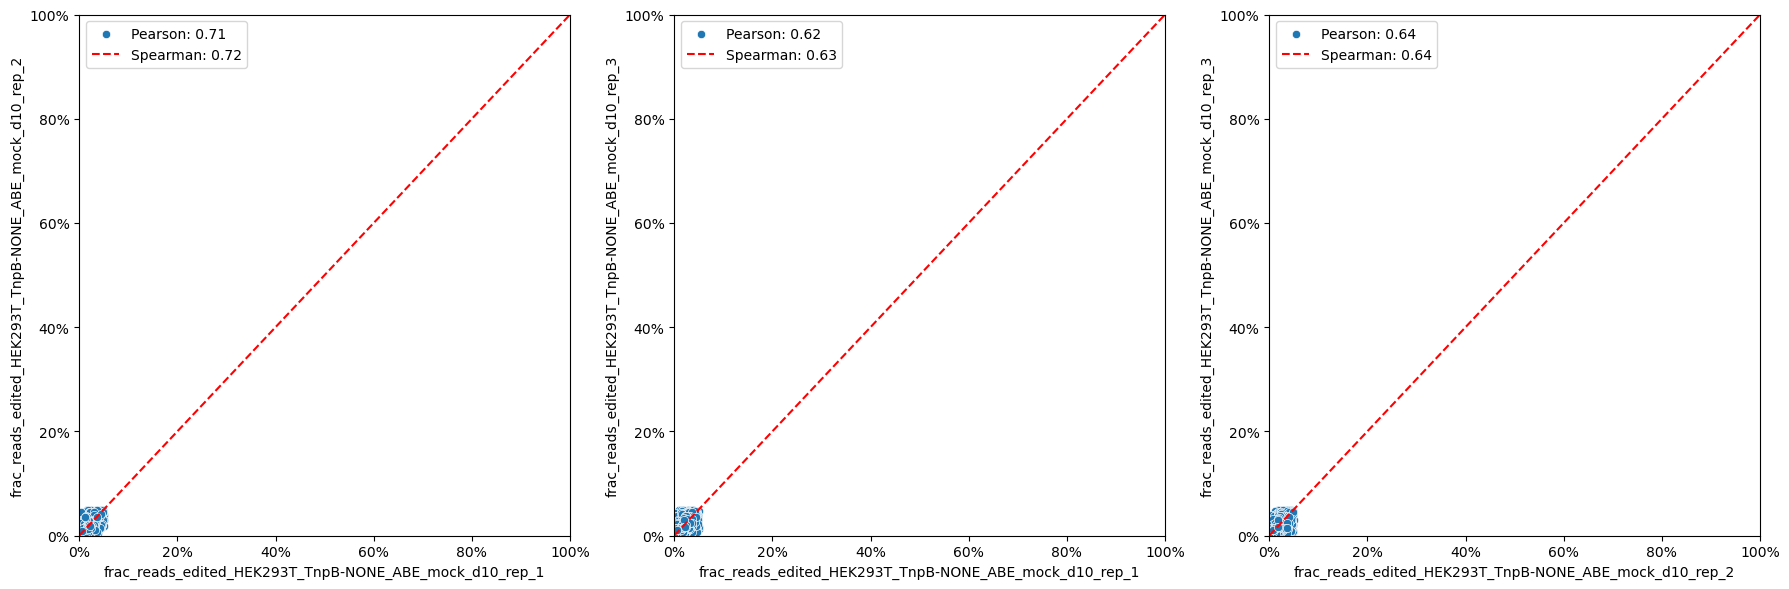

(4840, 3)


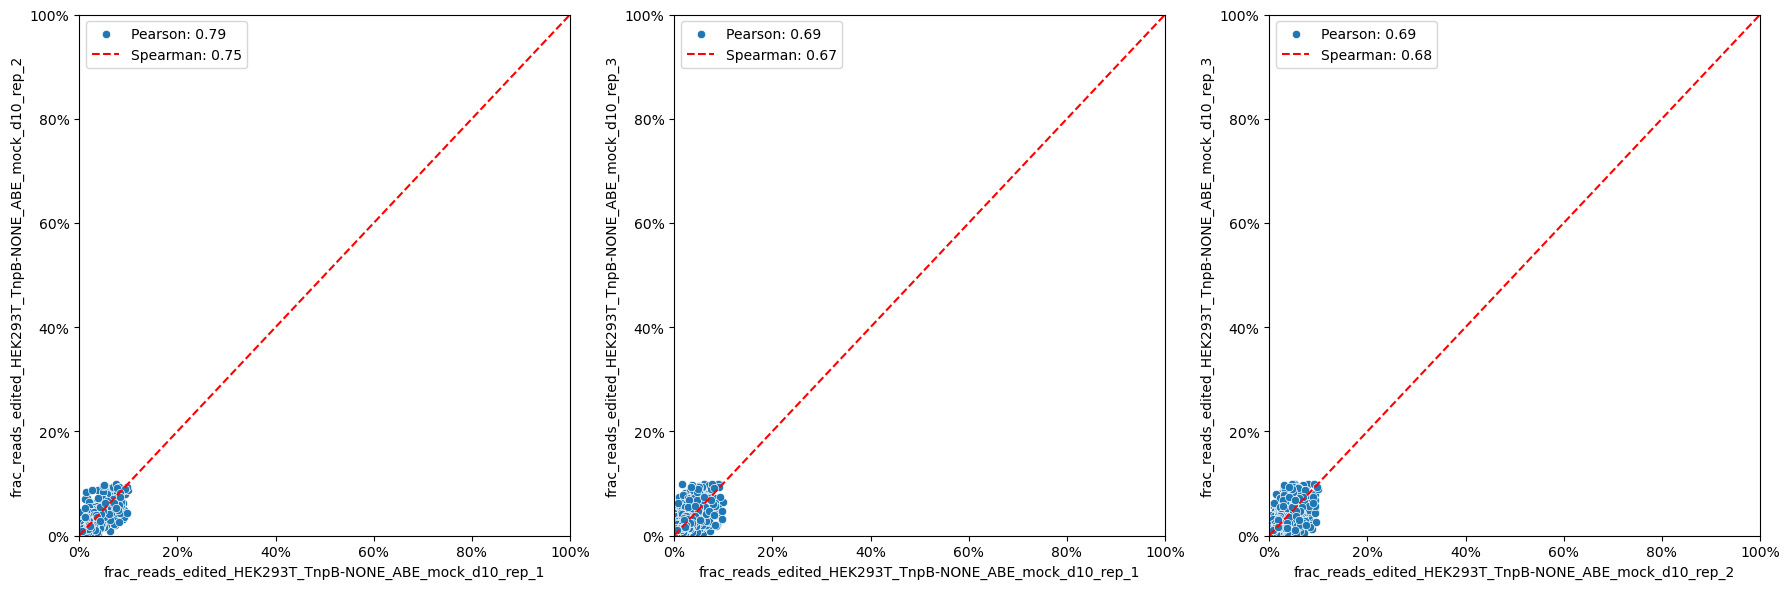

(458, 3)


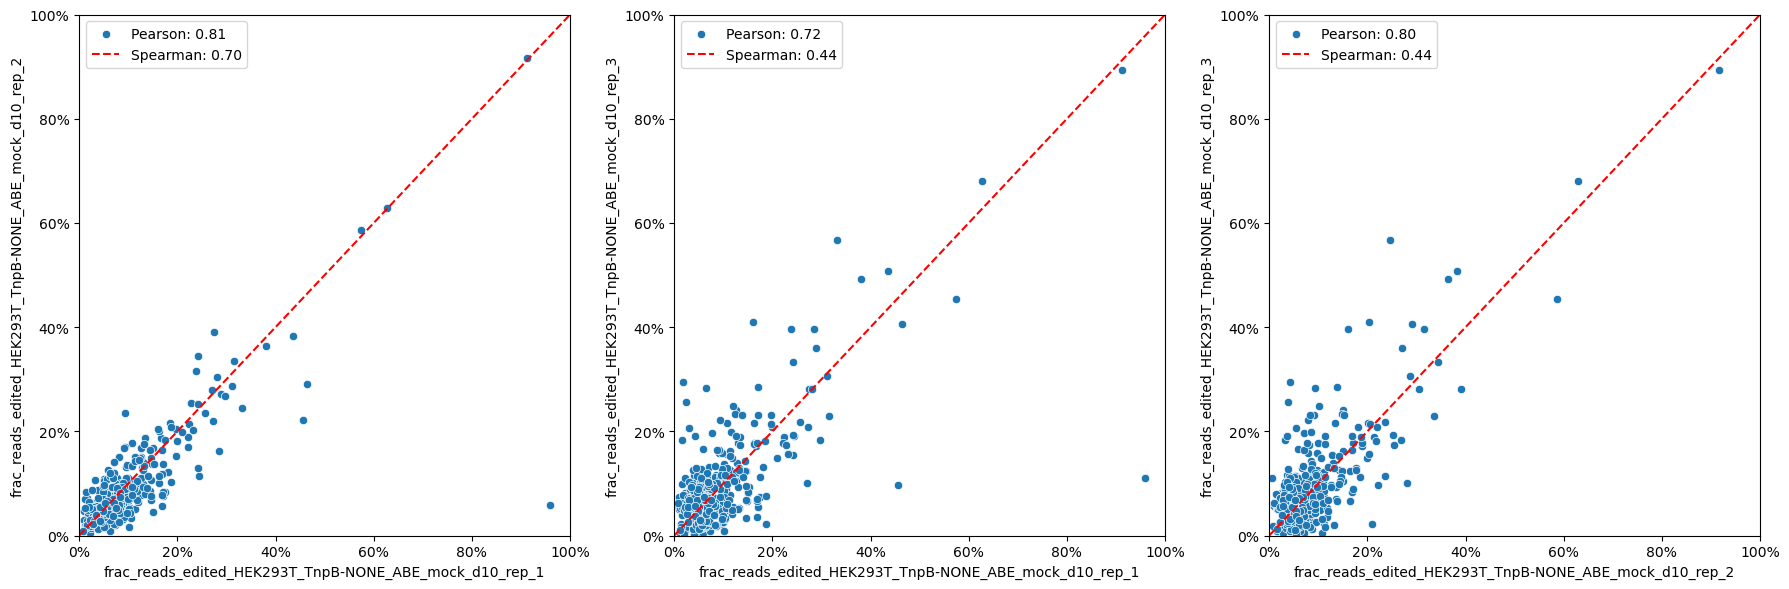

(173, 3)


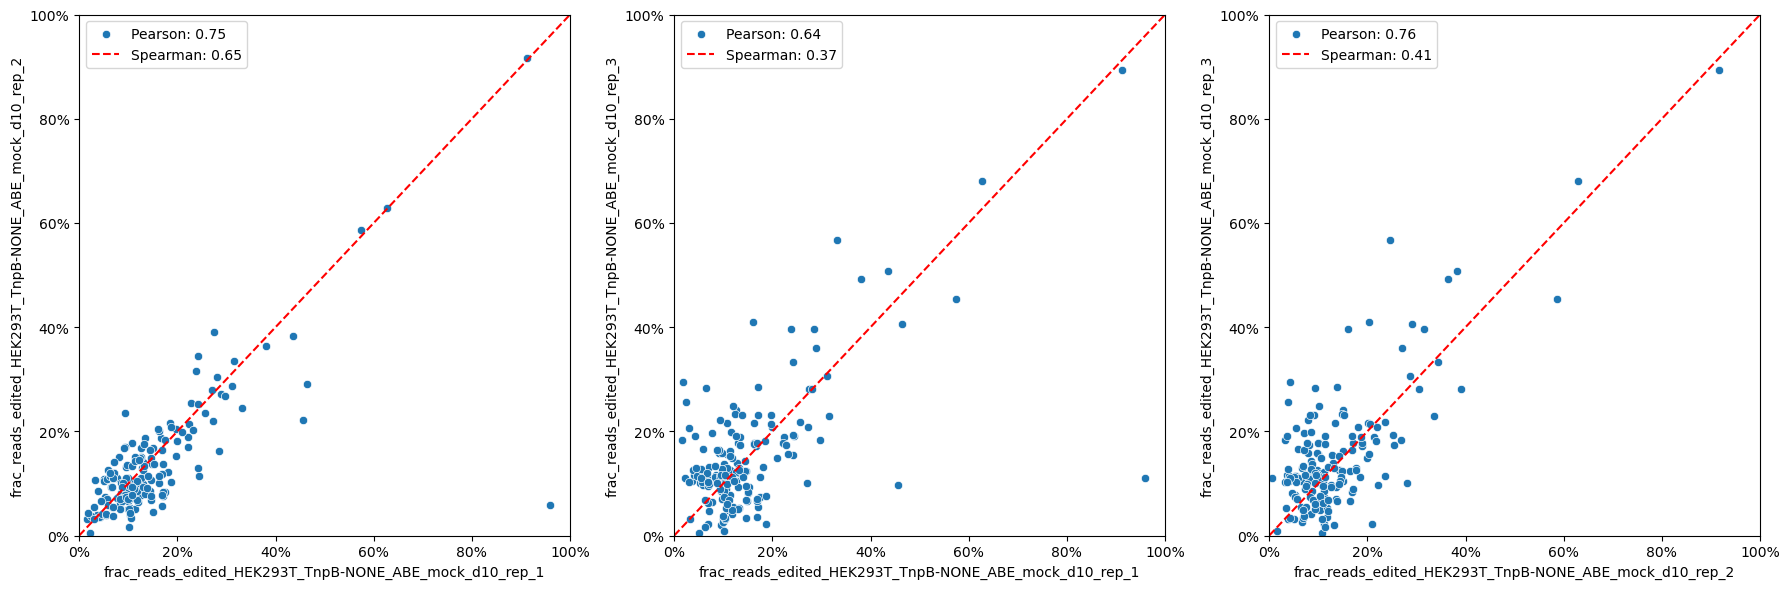

In [35]:
editor_columns=['frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_1',
                'frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_2',
                'frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_3',]

all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim=all_abe_samples_reads_editedrates_not_normalized_pivot_df.loc[:,list(editor_columns)]
print(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.shape)
all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim

# Iterate over every 3 columns
for i in range(0, len(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns), 3):
    if i + 2 < len(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns):
        col1 = all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i]
        col2 = all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i + 1]
        col3 = all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i + 2]

        test=all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim[[col1,col2,col3]]
        test = test.dropna()
        test = test[test.max(axis=1) < 0.05]
        print(test.shape)
        plot_correlation(test, col1, col2, col3)

# Iterate over every 3 columns
for i in range(0, len(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns), 3):
    if i + 2 < len(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns):
        col1 = all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i]
        col2 = all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i + 1]
        col3 = all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i + 2]

        test=all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim[[col1,col2,col3]]
        test = test.dropna()
        test = test[test.max(axis=1) < 0.1]
        print(test.shape)
        plot_correlation(test, col1, col2, col3)

# Iterate over every 3 columns
for i in range(0, len(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns), 3):
    if i + 2 < len(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns):
        col1 = all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i]
        col2 = all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i + 1]
        col3 = all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i + 2]

        test=all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim[[col1,col2,col3]]
        test = test.dropna()
        test = test[test.max(axis=1) >= 0.05]
        print(test.shape)
        plot_correlation(test, col1, col2, col3)

# Iterate over every 3 columns
for i in range(0, len(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns), 3):
    if i + 2 < len(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns):
        col1 = all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i]
        col2 = all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i + 1]
        col3 = all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i + 2]

        test=all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim[[col1,col2,col3]]
        test = test.dropna()
        test = test[test.max(axis=1) >= 0.1]
        print(test.shape)
        plot_correlation(test, col1, col2, col3)

(5539, 15)
(5013, 3)


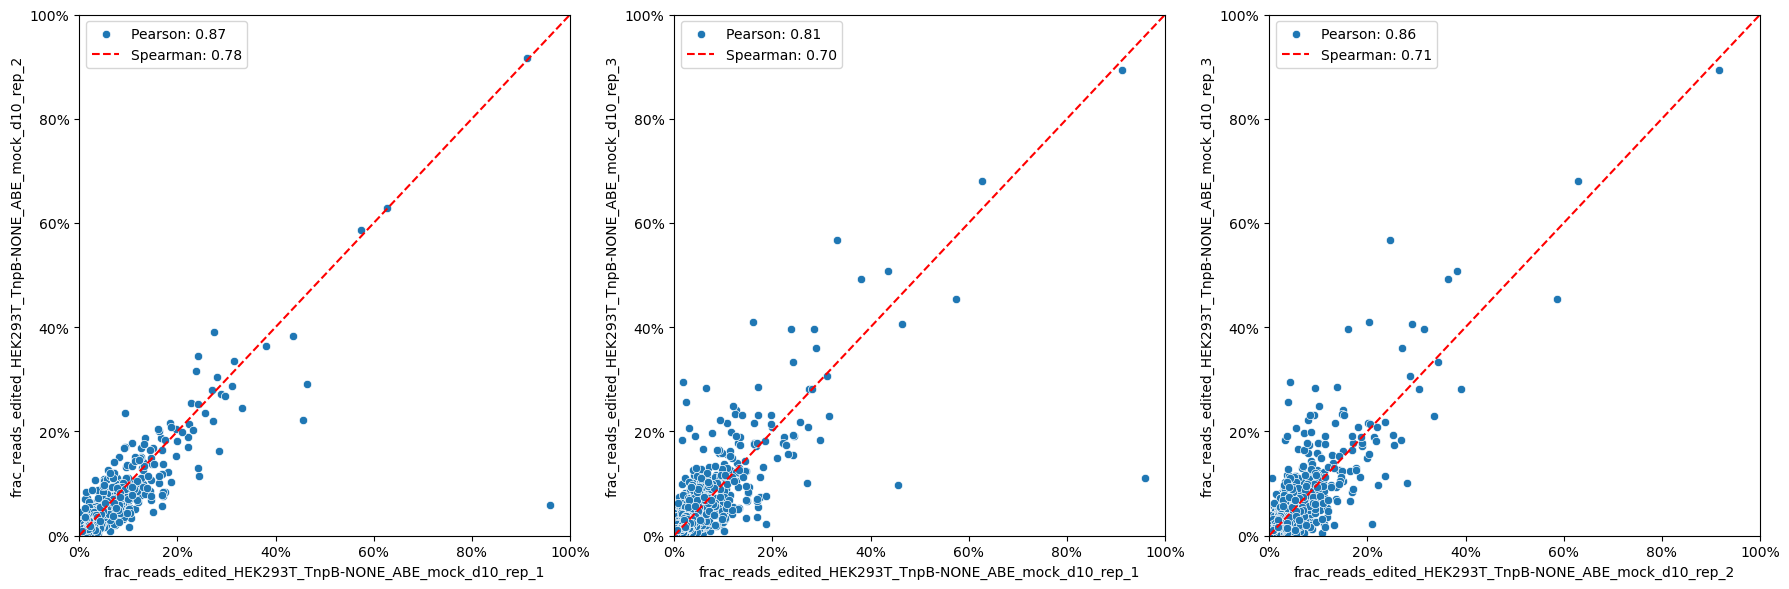

(4679, 3)


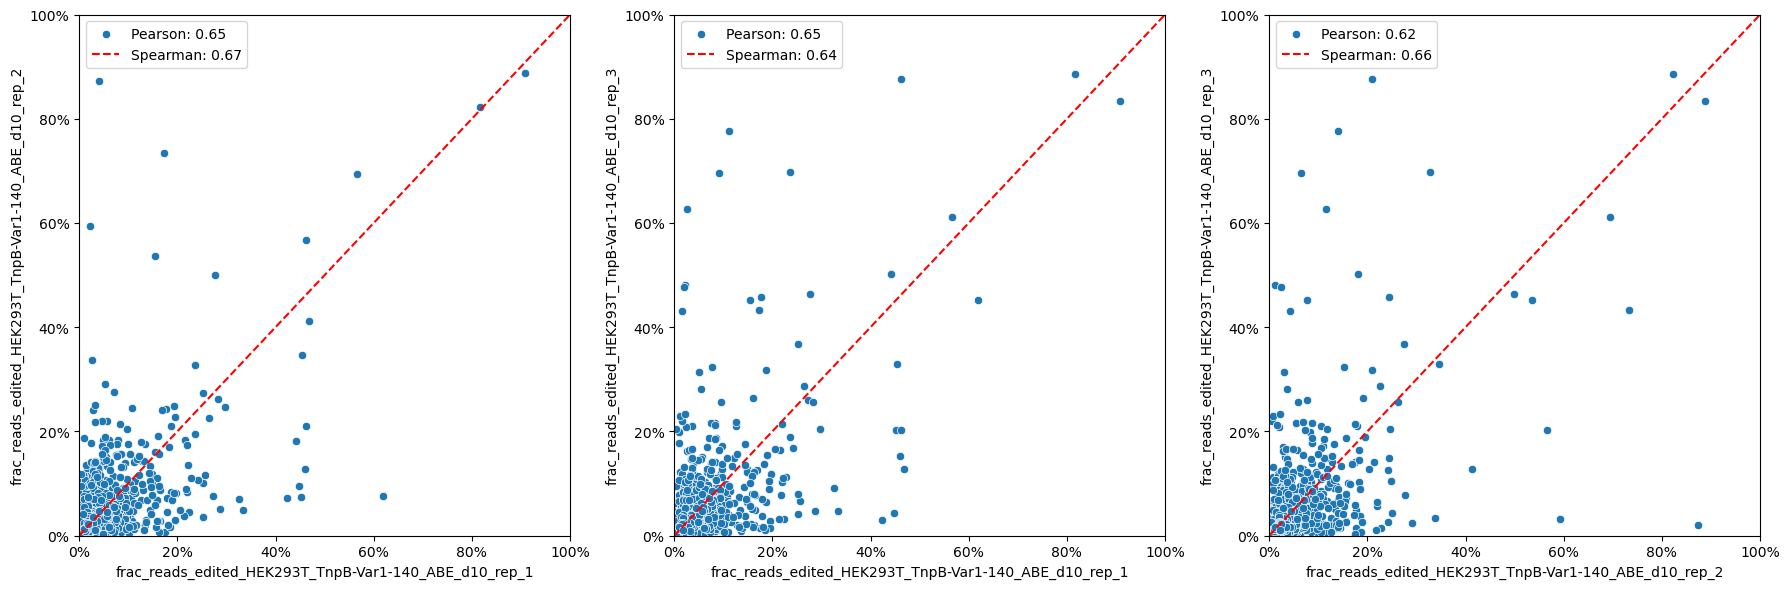

(4810, 3)


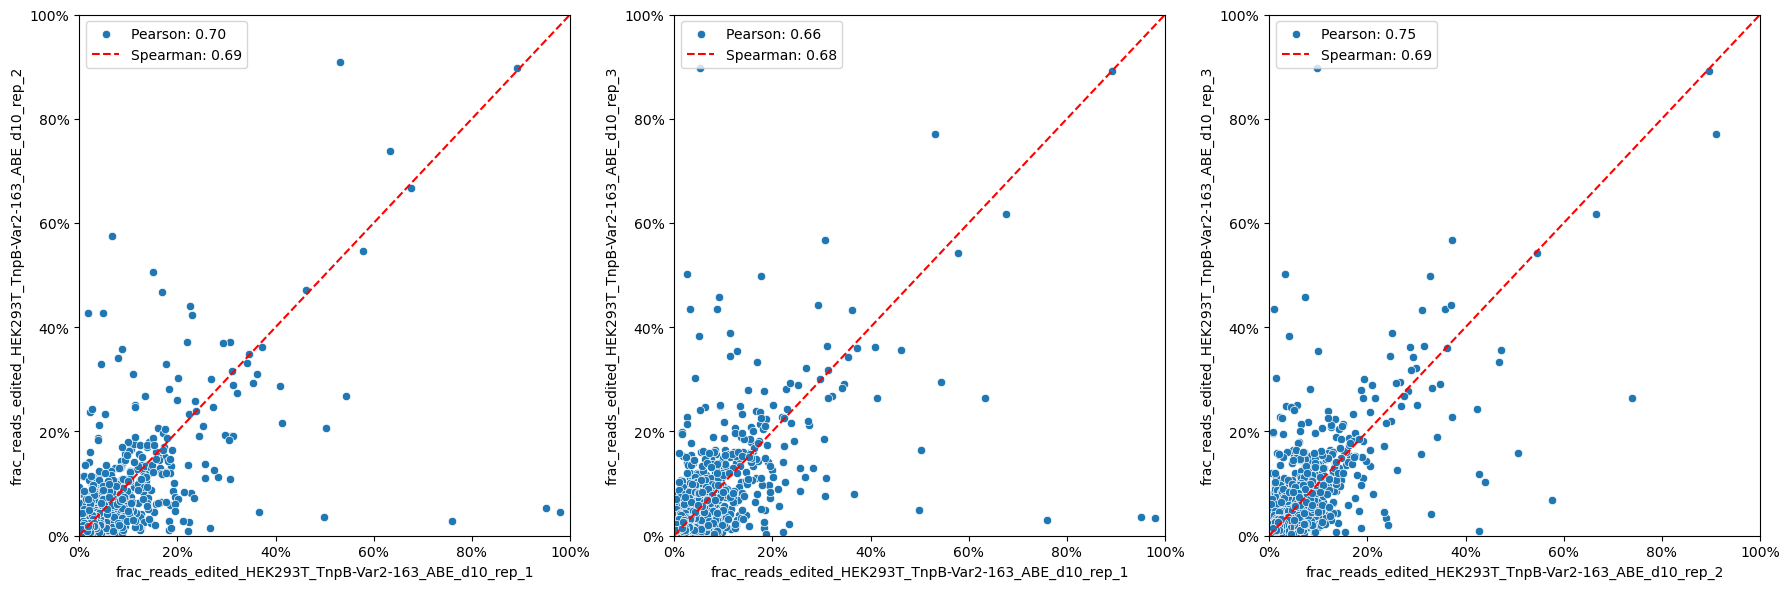

(4726, 3)


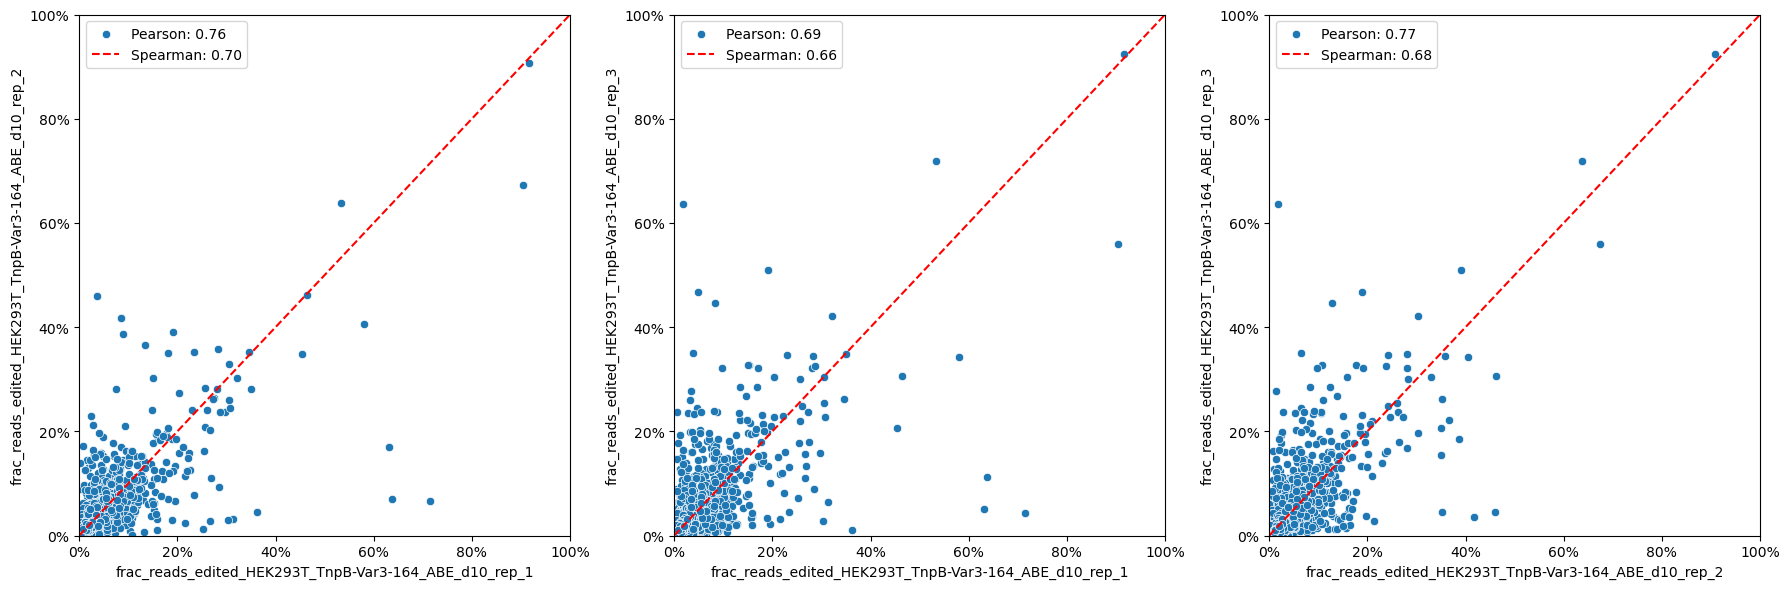

(4822, 3)


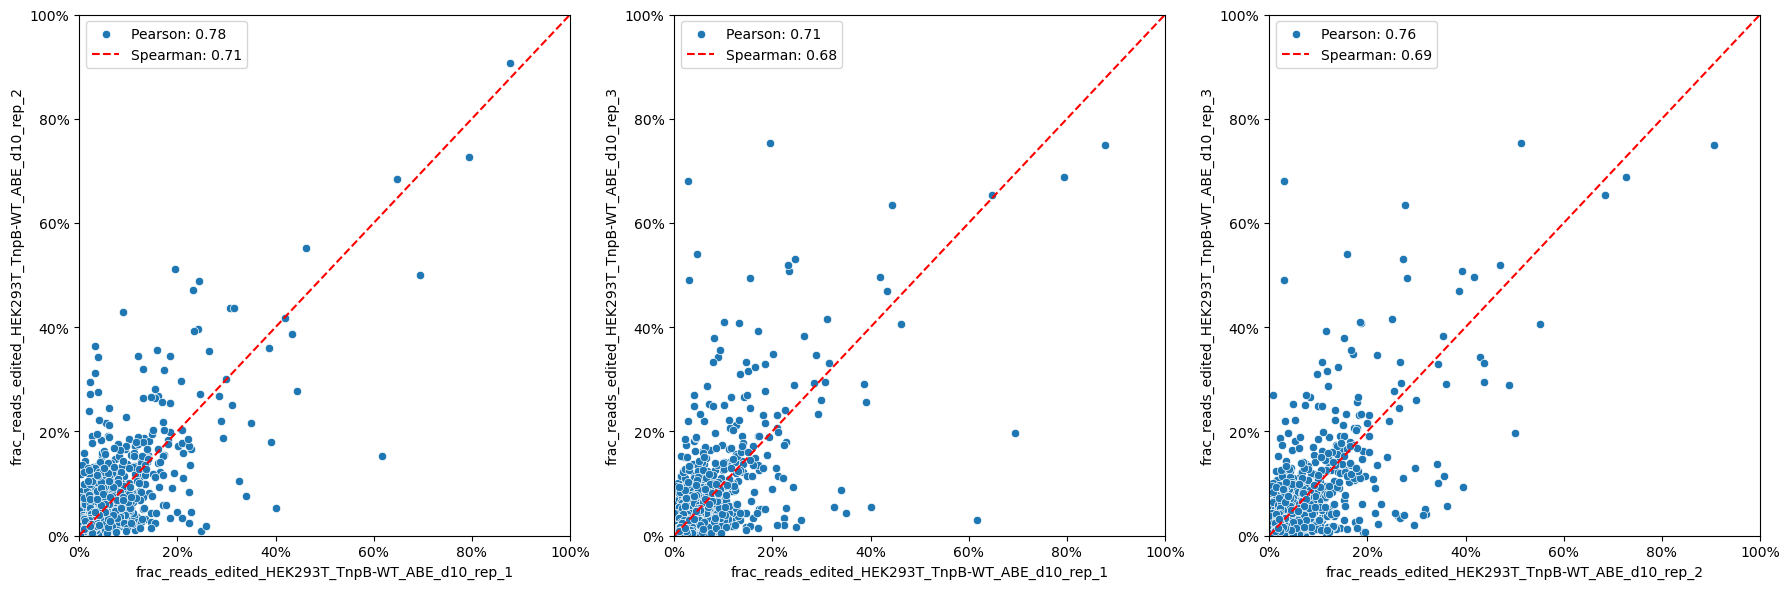

In [36]:


editor_columns=['frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_1',
                'frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_2',
                'frac_reads_edited_HEK293T_TnpB-NONE_ABE_mock_d10_rep_3',
    'frac_reads_edited_HEK293T_TnpB-Var1-140_ABE_d10_rep_1',
 'frac_reads_edited_HEK293T_TnpB-Var1-140_ABE_d10_rep_2',
 'frac_reads_edited_HEK293T_TnpB-Var1-140_ABE_d10_rep_3',
 'frac_reads_edited_HEK293T_TnpB-Var2-163_ABE_d10_rep_1',
 'frac_reads_edited_HEK293T_TnpB-Var2-163_ABE_d10_rep_2',
 'frac_reads_edited_HEK293T_TnpB-Var2-163_ABE_d10_rep_3',
 'frac_reads_edited_HEK293T_TnpB-Var3-164_ABE_d10_rep_1',
 'frac_reads_edited_HEK293T_TnpB-Var3-164_ABE_d10_rep_2',
 'frac_reads_edited_HEK293T_TnpB-Var3-164_ABE_d10_rep_3',
 'frac_reads_edited_HEK293T_TnpB-WT_ABE_d10_rep_1',
 'frac_reads_edited_HEK293T_TnpB-WT_ABE_d10_rep_2',
 'frac_reads_edited_HEK293T_TnpB-WT_ABE_d10_rep_3']

all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim=all_abe_samples_reads_editedrates_not_normalized_pivot_df.loc[:,list(editor_columns)]
print(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.shape)
all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim

# Iterate over every 3 columns
for i in range(0, len(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns), 3):
    if i + 2 < len(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns):
        col1 = all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i]
        col2 = all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i + 1]
        col3 = all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i + 2]

        test=all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim[[col1,col2,col3]]
        test = test.dropna()
        print(test.shape)

        sample_name=all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i].split("_rep")[0].split("edited_")[-1]
        plot_correlation(test, col1, col2, col3,save_figure=True, figure_folder=NAS_folder,
                         figure_name=f"Read_level_correlation_beforeNormalisation_{sample_name}")

        

(1312, 15)
(1220, 3)


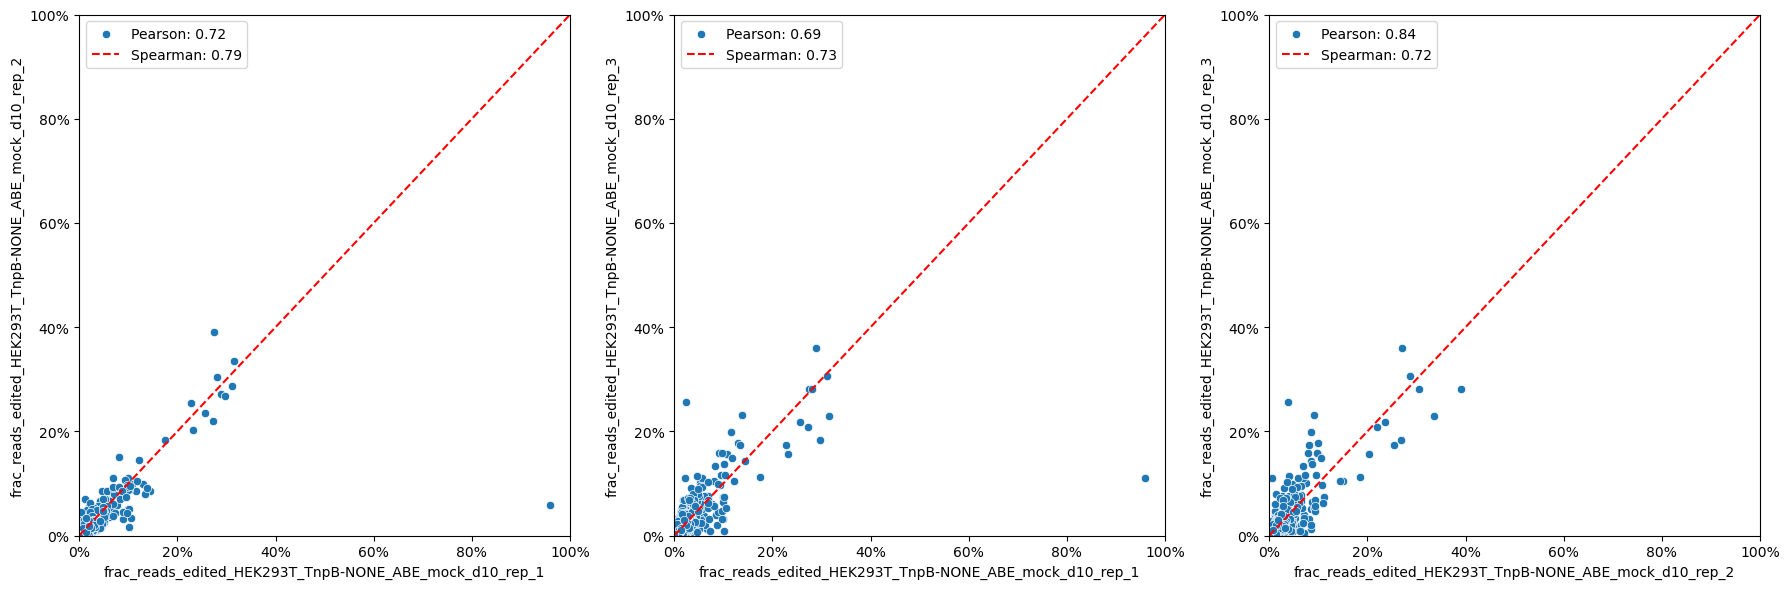

(1160, 3)


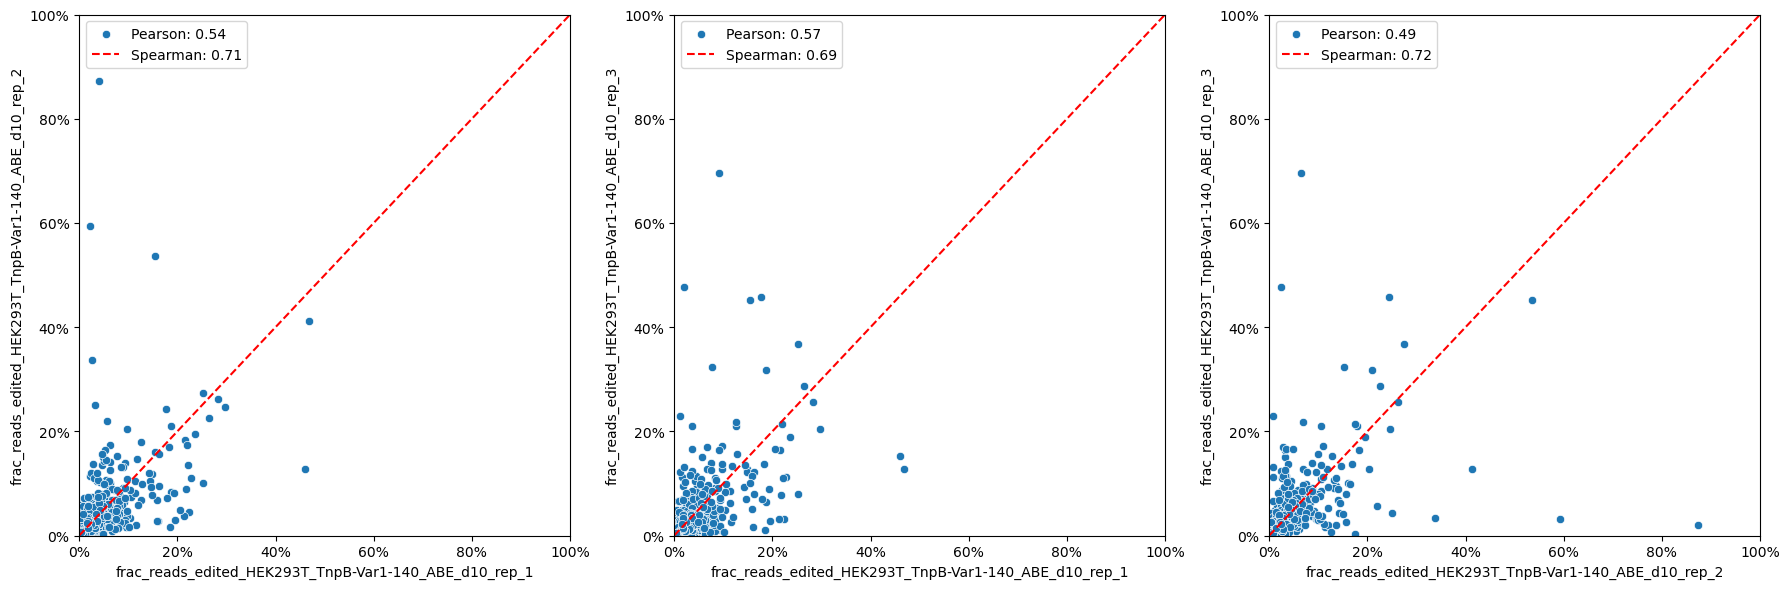

(1181, 3)


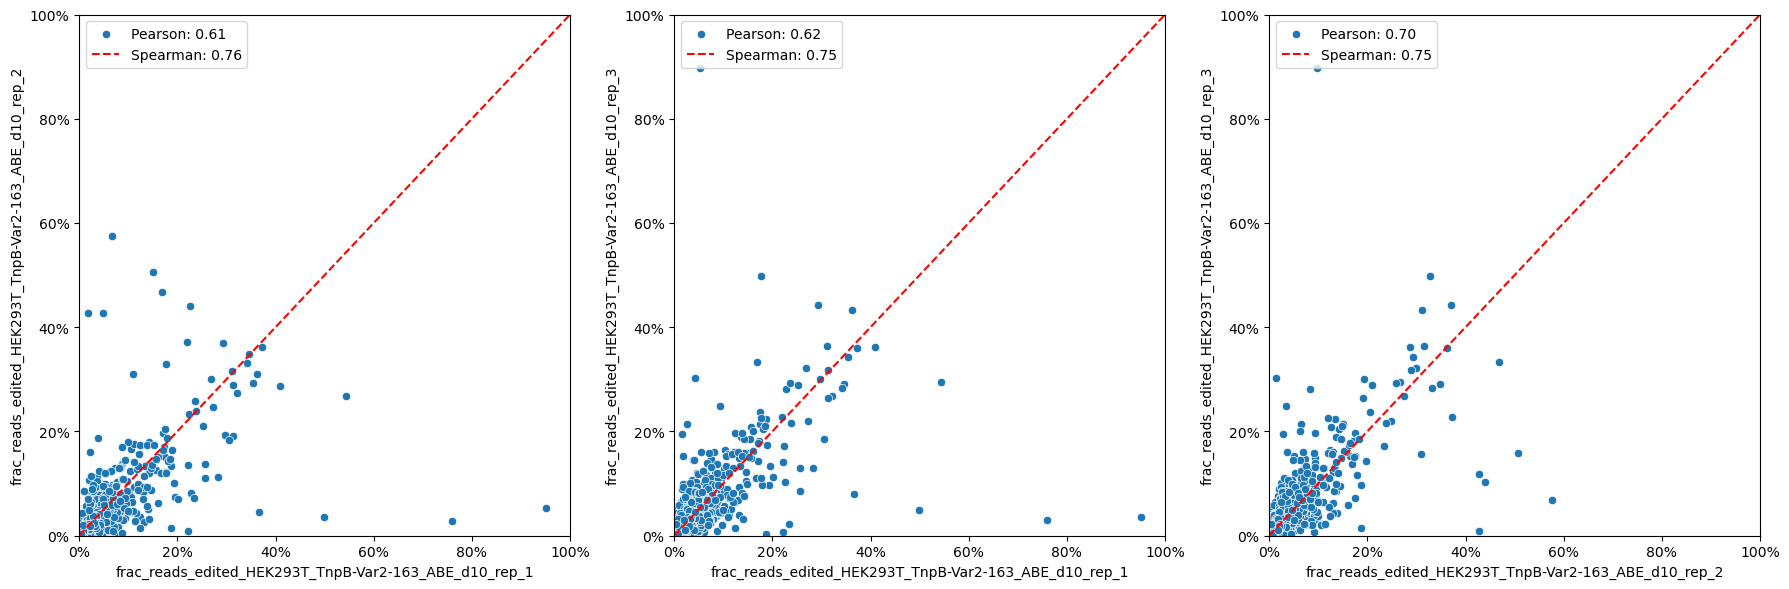

(1161, 3)


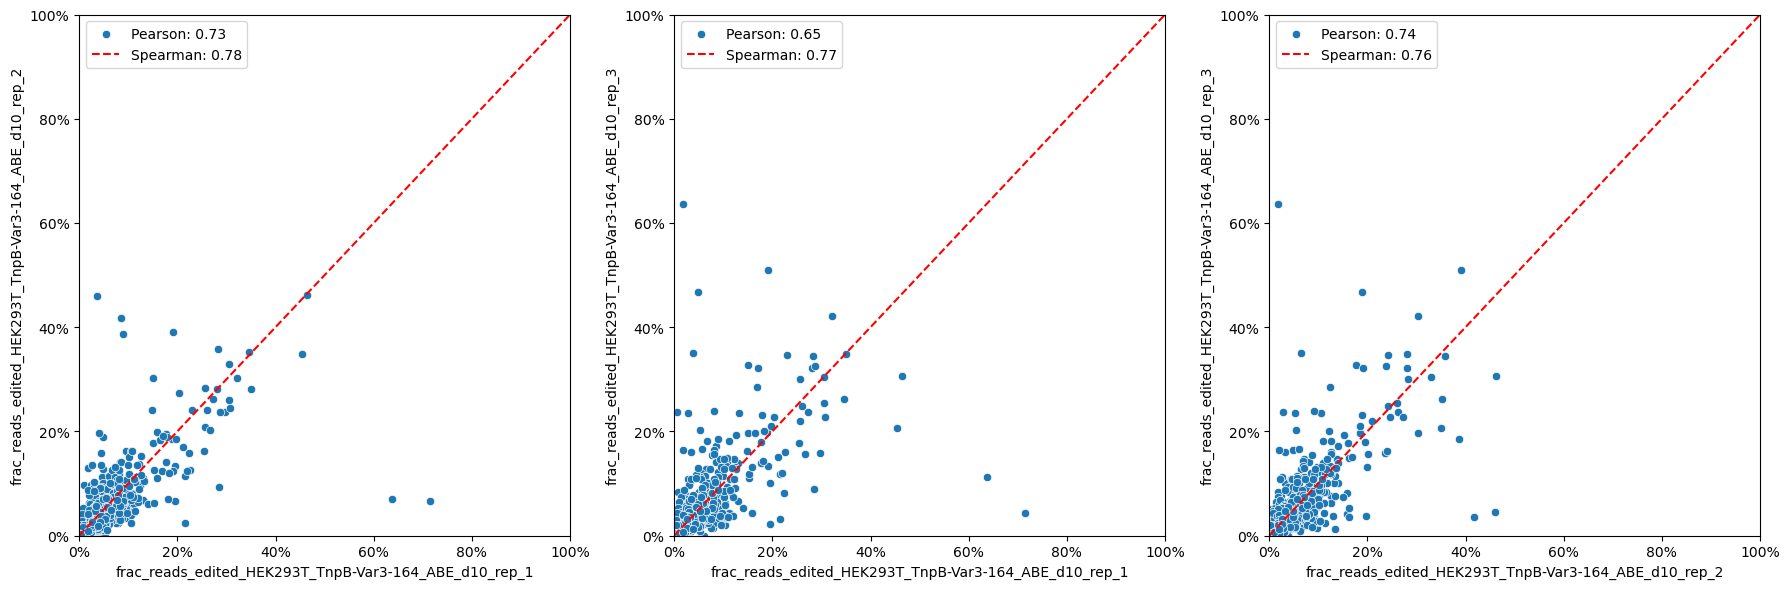

(1189, 3)


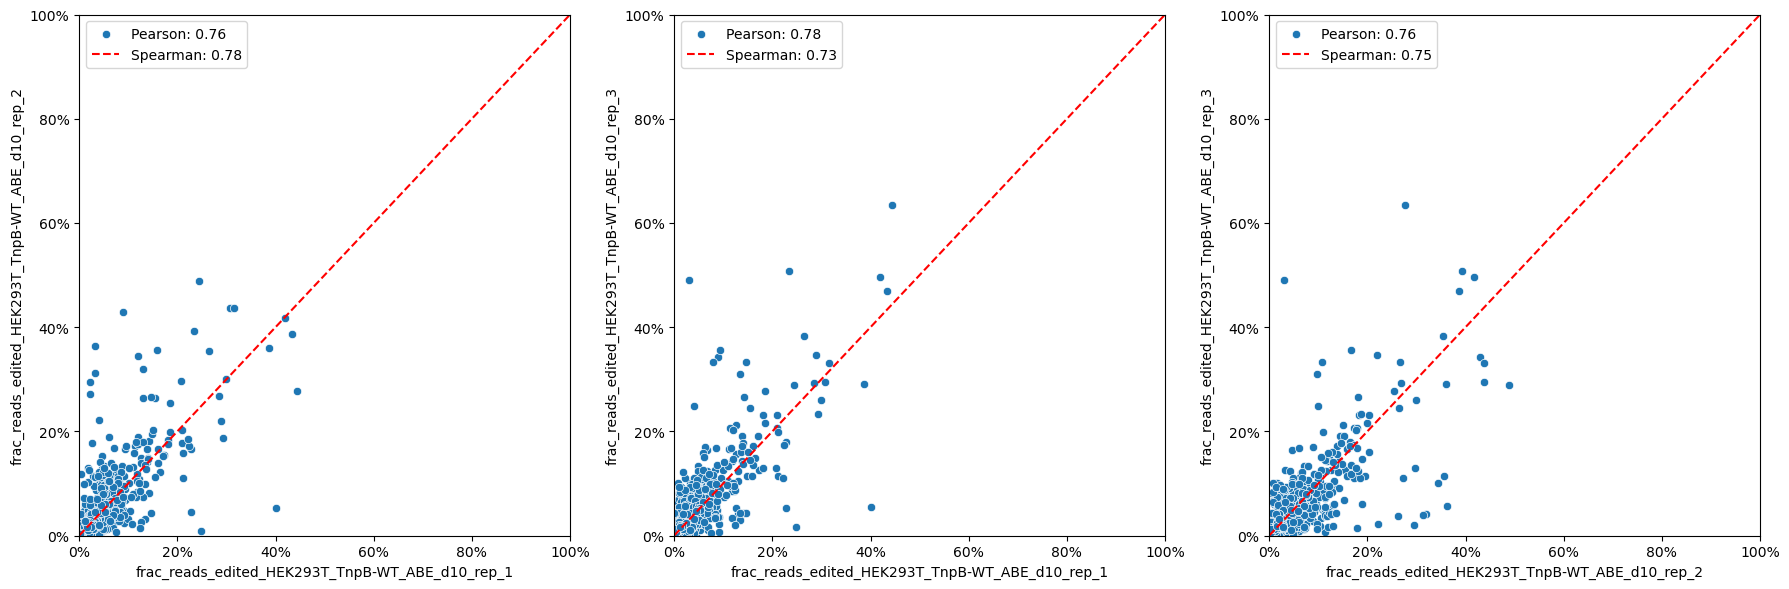

In [37]:

all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim=all_abe_samples_reads_editedrates_not_normalized_pivot_df.loc[all_abe_samples_reads_editedrates_not_normalized_pivot_df["TAM_"]=="TTGAT",list(editor_columns)]
print(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.shape)
all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim

# Iterate over every 3 columns
for i in range(0, len(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns), 3):
    if i + 2 < len(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns):
        col1 = all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i]
        col2 = all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i + 1]
        col3 = all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.columns[i + 2]

        test=all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim[[col1,col2,col3]]
        test = test.dropna()
        print(test.shape)
        plot_correlation(test, col1, col2, col3)

        

In [38]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

In [39]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates,_=normalize_editing_rate_reads(all_abe_samples_reads_editedrates_not_normalized,
        col_normalize_over=['barcode','TAM',],
        col_rate='frac_reads_edited',
        col_control='is_ctrl',
        th_ctrl_missing=0.05,  # 0.05
        ctrl_edit_rate_thres=0.1 # 0.1, 0.05,0.01
    )

frac_low_num_read_in_control: 0.0. Drop these records
frac_unintendededit_in_control: 0.023414137558058153. Drop these records
130 out of 5337 sites are missing control editing rate. drop these sites


In [40]:
all_abe_samples_reads_editedrates.to_csv(f"{NAS_folder}/all_abe_samples_reads_editedrates.csv")
print(f"{NAS_folder}/all_abe_samples_reads_editedrates.csv")

/mnt/G_Pharma/Users/tfang/Cell_Screen/Priscilla_A13_Screen/all_abe_samples_reads_editedrates.csv


In [41]:
# Figure 1f: A-to-G editing by TAM, one point per library member per editor.
import matplotlib.pyplot as plt

data = pd.read_csv(f"{NAS_folder}/all_abe_samples_reads_editedrates.csv")

# The table holds one row per replicate; average them so each point is the mean
# of the three independent replicates. Drop this line to plot replicates separately.
data = data.groupby(['editor', 'TAM', 'barcode'], as_index=False)['frac_reads_edited'].mean()

tam_order = ['TTGAT', 'CTGAT', 'ATGAT', 'GTGAT', 'TAGAT', 'TGGAT', 'TCGAT', 'TTAAT',
             'TTTAT', 'TTCAT', 'TTGTT', 'TTGGT', 'TTGCT', 'TTGAG', 'TTGAC', 'TTGAA']
color_map = {
    'TnpB-WT_ABE_d10': 'grey',
    'TnpB-Var1-140_ABE_d10': 'gold',
    'TnpB-Var2-163_ABE_d10': 'pink',
    'TnpB-Var3-164_ABE_d10': 'skyblue',
}

editors = data['editor'].unique()
offset_map = {editor: i * 0.15 for i, editor in enumerate(editors)}
data['TAM_numeric'] = pd.Categorical(data['TAM'], categories=tam_order, ordered=True).codes

fig = px.box(data, x='TAM', y='frac_reads_edited', color='editor') #added line at beginning
fig, ax = plt.subplots(figsize=(15, 6))
for editor in editors:
    editor_data = data[data['editor'] == editor]
    ax.scatter(editor_data['TAM_numeric'] + offset_map[editor],
               editor_data['frac_reads_edited'],
               label=editor, alpha=0.6, s=10, color=color_map[editor])

    # black bar at the mean across library members for this editor and TAM
    mean_data = editor_data.groupby('TAM_numeric')['frac_reads_edited'].mean()
    x_positions = mean_data.index + offset_map[editor]
    ax.hlines(mean_data.values, x_positions - 0.05, x_positions + 0.05,
              color='black', linewidth=2)

ax.set_xlabel('TAM')
ax.set_ylabel('Fraction of Reads Edited')
ax.set_xticks(range(len(tam_order)))
ax.set_xticklabels(tam_order)
ax.legend(frameon=False, fontsize=8)
fig.savefig(f"{NAS_folder}/figure_1f_editing_by_TAM.pdf", bbox_inches='tight')
plt.show()

NameError: name 'px' is not defined

In [ ]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_pivot_df = all_abe_samples_reads_editedrates.pivot_table(index=['barcode', 'TAM', "target_site_lib"],
                                           columns='sample_name',
                                           values=['frac_reads_edited','num_reads'],  # values='edit_rate',
                                            aggfunc='first'
                                           ).reset_index()

all_abe_samples_reads_editedrates_pivot_df.columns = ['_'.join(col).strip() for col in all_abe_samples_reads_editedrates_pivot_df.columns.values]

print(all_abe_samples_reads_editedrates_pivot_df.shape)
all_abe_samples_reads_editedrates_pivot_df

(5175, 27)


,barcode_,TAM_,target_site_lib_,frac_reads_edited_HEK293T_TnpB-Var1-140_ABE_d10_rep_1,frac_reads_edited_HEK293T_TnpB-Var1-140_ABE_d10_rep_2,frac_reads_edited_HEK293T_TnpB-Var1-140_ABE_d10_rep_3,frac_reads_edited_HEK293T_TnpB-Var2-163_ABE_d10_rep_1,frac_reads_edited_HEK293T_TnpB-Var2-163_ABE_d10_rep_2,frac_reads_edited_HEK293T_TnpB-Var2-163_ABE_d10_rep_3,frac_reads_edited_HEK293T_TnpB-Var3-164_ABE_d10_rep_1,...,num_reads_HEK293T_TnpB-Var1-140_ABE_d10_rep_3,num_reads_HEK293T_TnpB-Var2-163_ABE_d10_rep_1,num_reads_HEK293T_TnpB-Var2-163_ABE_d10_rep_2,num_reads_HEK293T_TnpB-Var2-163_ABE_d10_rep_3,num_reads_HEK293T_TnpB-Var3-164_ABE_d10_rep_1,num_reads_HEK293T_TnpB-Var3-164_ABE_d10_rep_2,num_reads_HEK293T_TnpB-Var3-164_ABE_d10_rep_3,num_reads_HEK293T_TnpB-WT_ABE_d10_rep_1,num_reads_HEK293T_TnpB-WT_ABE_d10_rep_2,num_reads_HEK293T_TnpB-WT_ABE_d10_rep_3
0,AAAAAAA,TAGAT,GAACATTATCGGTATCTTGA,0.000064,0.004061,0.004928,0.001466,0.000513,0.000000,0.000000,...,1964.0,1880.0,2071.0,1828.0,1646.0,2574.0,2054.0,1965.0,1910.0,2400.0
1,AAAAACC,TTTAT,AGGATTGGTCTTGATTTGGT,0.005275,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,203.0,324.0,225.0,344.0
2,AAAAATA,TTTAT,TTCGGGATACATCGCCACCT,NaN,NaN,NaN,0.006080,NaN,0.022052,NaN,...,NaN,240.0,NaN,282.0,NaN,283.0,NaN,281.0,NaN,NaN
3,AAAAATG,TTCAT,GGTGAAGTTGGTTTCAAACG,0.000000,0.012128,0.000827,0.000000,0.000000,0.008977,0.006861,...,332.0,288.0,218.0,433.0,238.0,346.0,265.0,312.0,280.0,313.0
4,AAAACAA,TTGAT,GGAGTACACCTCACGAAGGG,0.077086,0.005648,0.020718,0.150544,0.125449,0.190372,0.103492,...,549.0,856.0,749.0,1122.0,687.0,958.0,518.0,992.0,799.0,688.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5170,TTTTTAG,ATGAT,GTAAGTAAGGCATAGCGTGT,0.019724,0.000000,0.000000,0.000000,0.007562,0.000000,0.005659,...,626.0,865.0,986.0,690.0,815.0,1208.0,785.0,1053.0,1178.0,1054.0
5171,TTTTTCA,TTAAT,CCTGTCTAAGCAGGGAAGCC,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1871.0,2631.0,4118.0,1554.0,1758.0,1779.0,1268.0,3819.0,3047.0,749.0
5172,TTTTTCG,TTTAT,GCATTCAAGCAAATCCCTAA,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,580.0,1347.0,740.0,753.0,878.0,1090.0,911.0,1053.0,966.0,681.0
5173,TTTTTGT,TTAAT,GTAGCGTGTAATAATTTCGG,0.000577,0.003867,0.008591,0.007742,0.000000,0.005955,0.000000,...,1272.0,1337.0,1538.0,1294.0,2062.0,1669.0,1432.0,1813.0,2465.0,1641.0


In [ ]:
editor_columns=[
    'frac_reads_edited_HEK293T_TnpB-Var1-140_ABE_d10_rep_1',
 'frac_reads_edited_HEK293T_TnpB-Var1-140_ABE_d10_rep_2',
 'frac_reads_edited_HEK293T_TnpB-Var1-140_ABE_d10_rep_3',
 'frac_reads_edited_HEK293T_TnpB-Var2-163_ABE_d10_rep_1',
 'frac_reads_edited_HEK293T_TnpB-Var2-163_ABE_d10_rep_2',
 'frac_reads_edited_HEK293T_TnpB-Var2-163_ABE_d10_rep_3',
 'frac_reads_edited_HEK293T_TnpB-Var3-164_ABE_d10_rep_1',
 'frac_reads_edited_HEK293T_TnpB-Var3-164_ABE_d10_rep_2',
 'frac_reads_edited_HEK293T_TnpB-Var3-164_ABE_d10_rep_3',
 'frac_reads_edited_HEK293T_TnpB-WT_ABE_d10_rep_1',
 'frac_reads_edited_HEK293T_TnpB-WT_ABE_d10_rep_2',
 'frac_reads_edited_HEK293T_TnpB-WT_ABE_d10_rep_3']

(5175, 12)


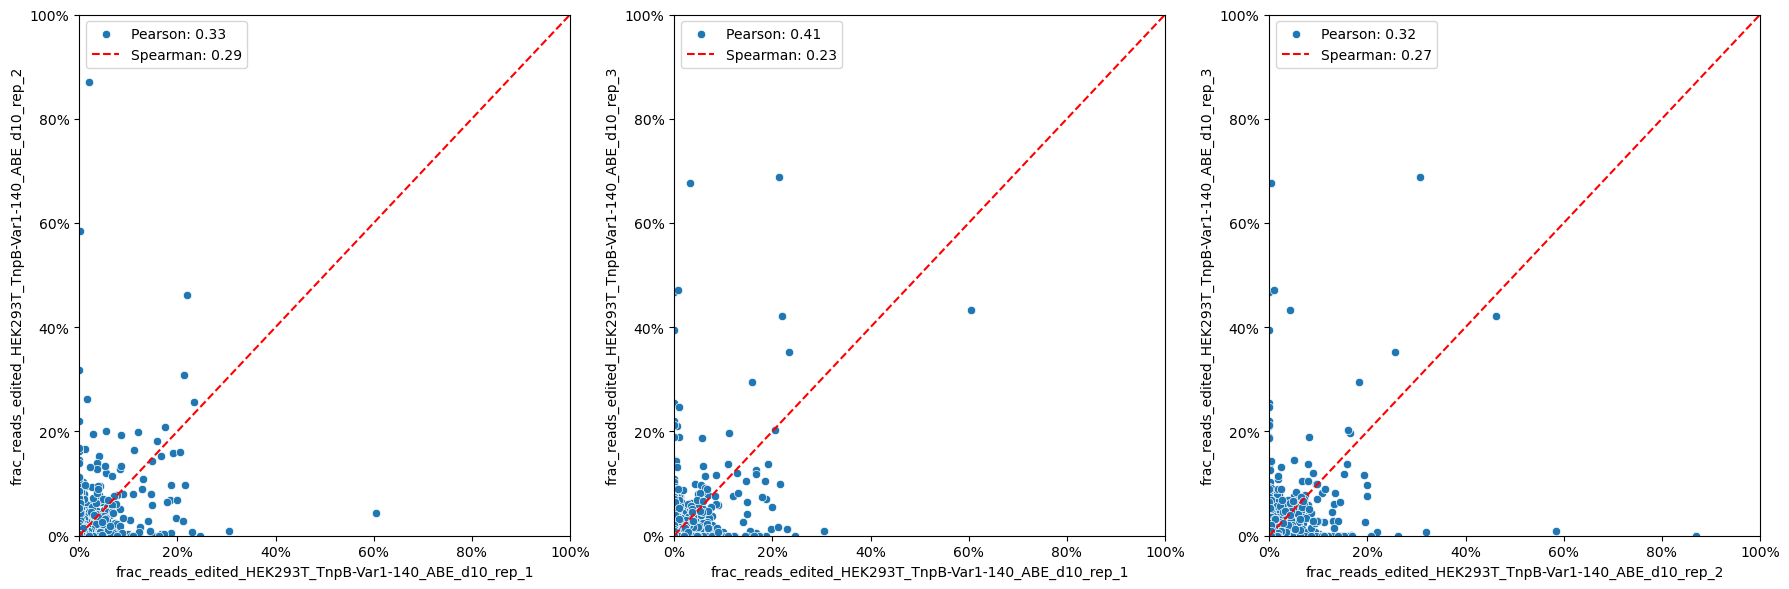

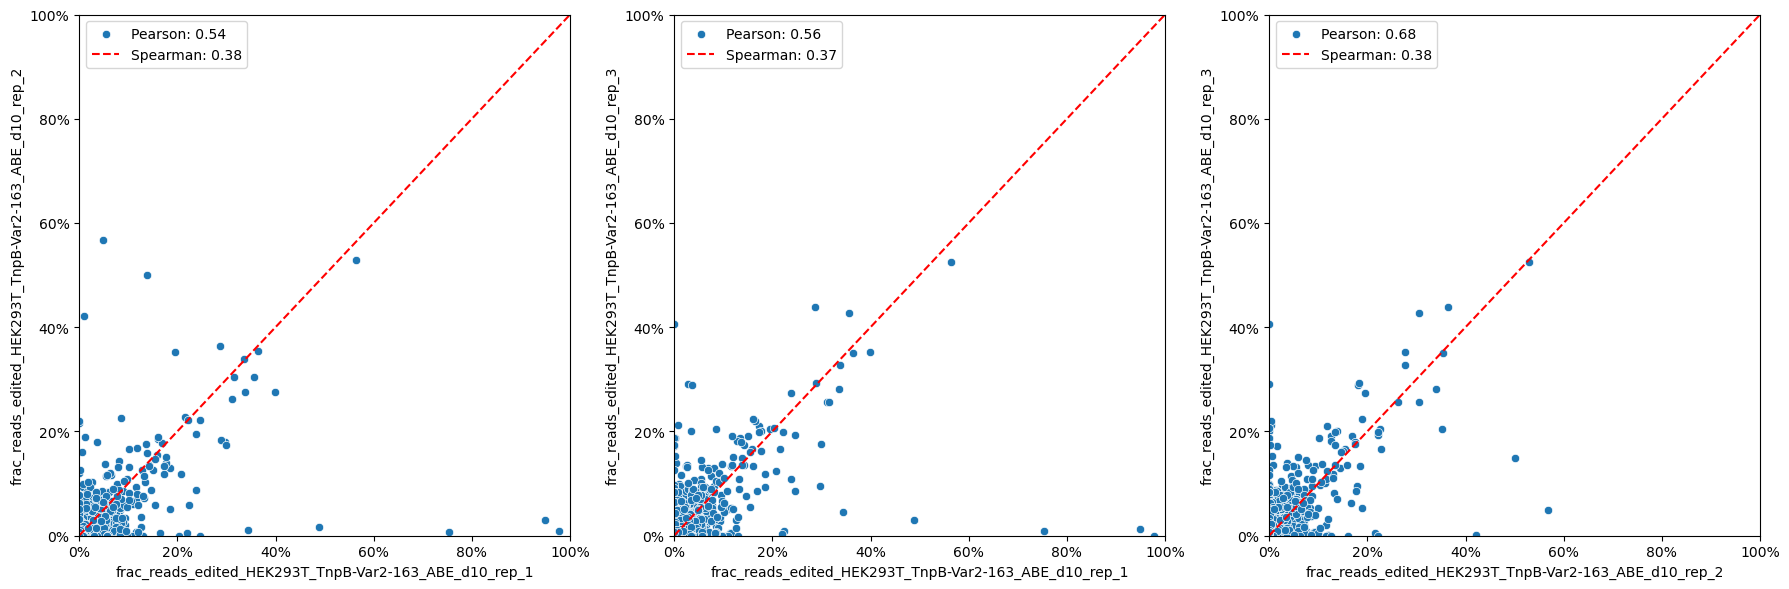

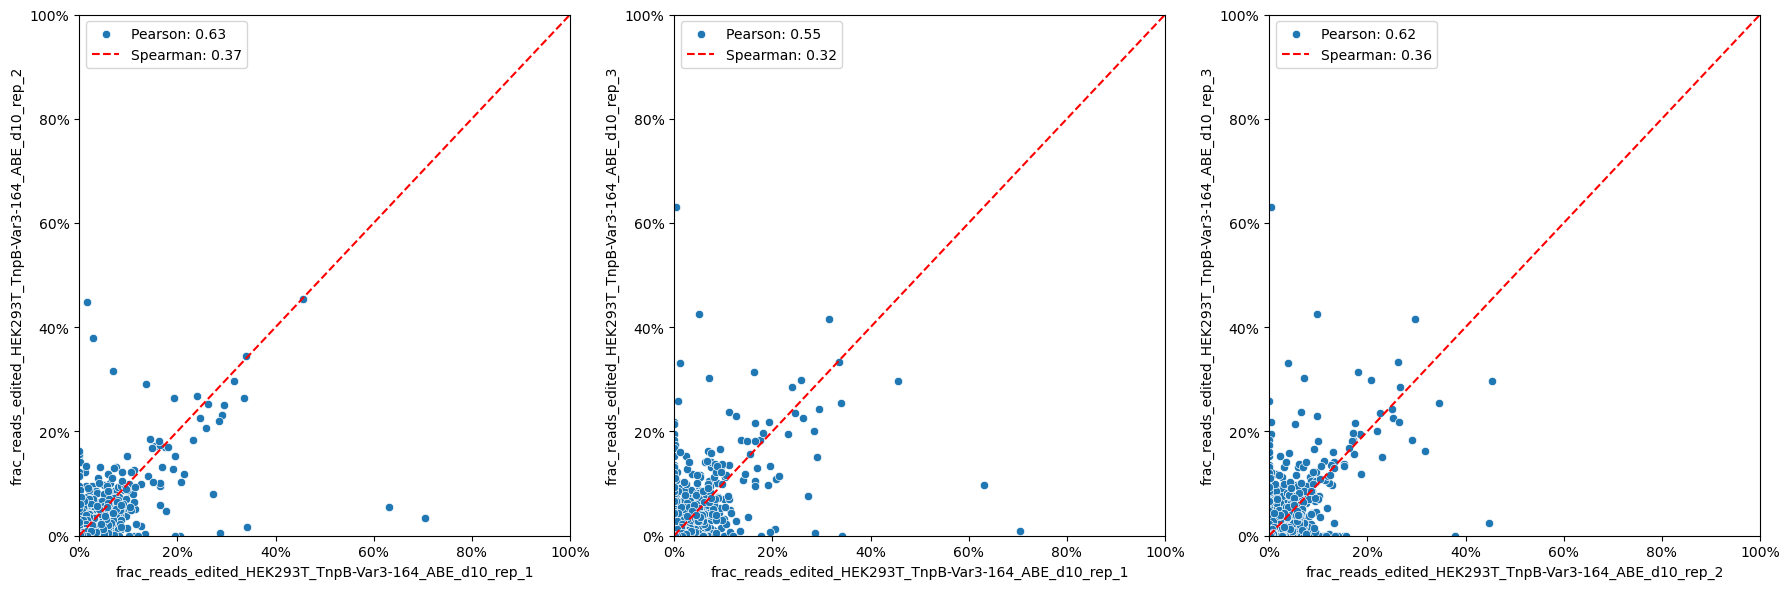

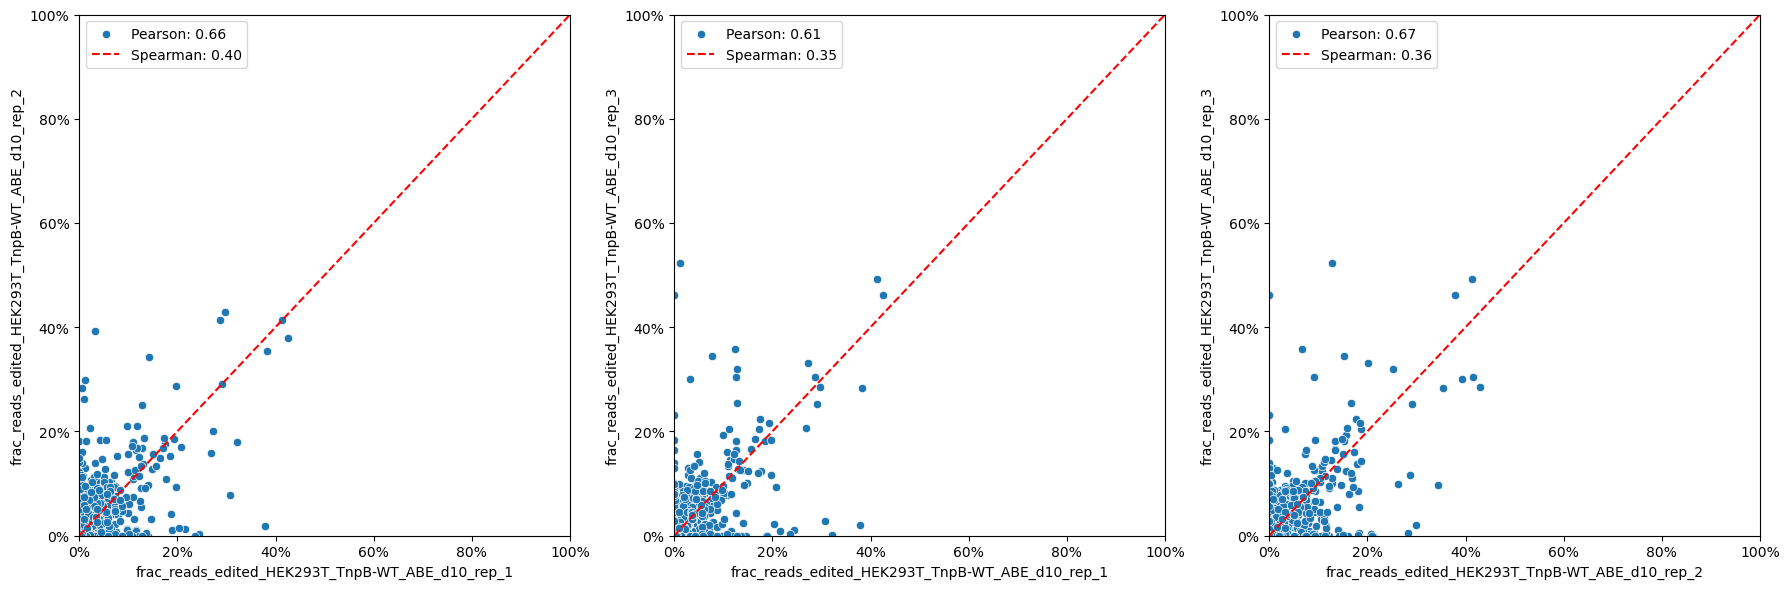

In [ ]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_pivot_df_slim=all_abe_samples_reads_editedrates_pivot_df.loc[:,list(editor_columns)]
print(all_abe_samples_reads_editedrates_pivot_df_slim.shape)
all_abe_samples_reads_editedrates_pivot_df_slim
# Iterate over every 3 columns
for i in range(0, len(all_abe_samples_reads_editedrates_pivot_df_slim.columns), 3):
    if i + 2 < len(all_abe_samples_reads_editedrates_pivot_df_slim.columns):
        col1 = all_abe_samples_reads_editedrates_pivot_df_slim.columns[i]
        col2 = all_abe_samples_reads_editedrates_pivot_df_slim.columns[i + 1]
        col3 = all_abe_samples_reads_editedrates_pivot_df_slim.columns[i + 2]

        test=all_abe_samples_reads_editedrates_pivot_df_slim[[col1,col2,col3]]
        test = test.dropna()

        sample_name=all_abe_samples_reads_editedrates_pivot_df_slim.columns[i].split("_rep")[0].split("edited_")[-1]
        plot_correlation(test, col1, col2, col3,save_figure=True, figure_folder=NAS_folder,
                         figure_name=f"Read_level_correlation_afterNormalisation_{sample_name}")

(1240, 12)
(1120, 3)


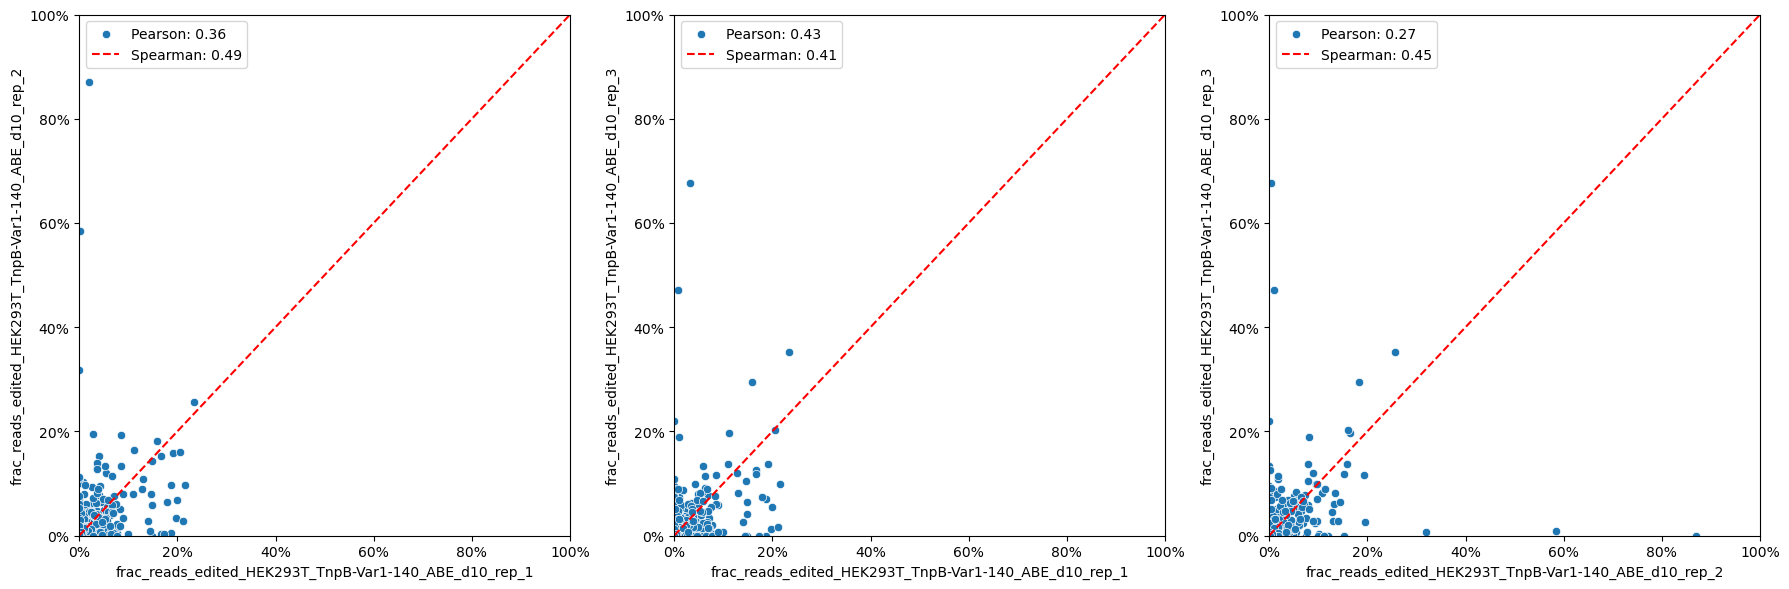

(1138, 3)


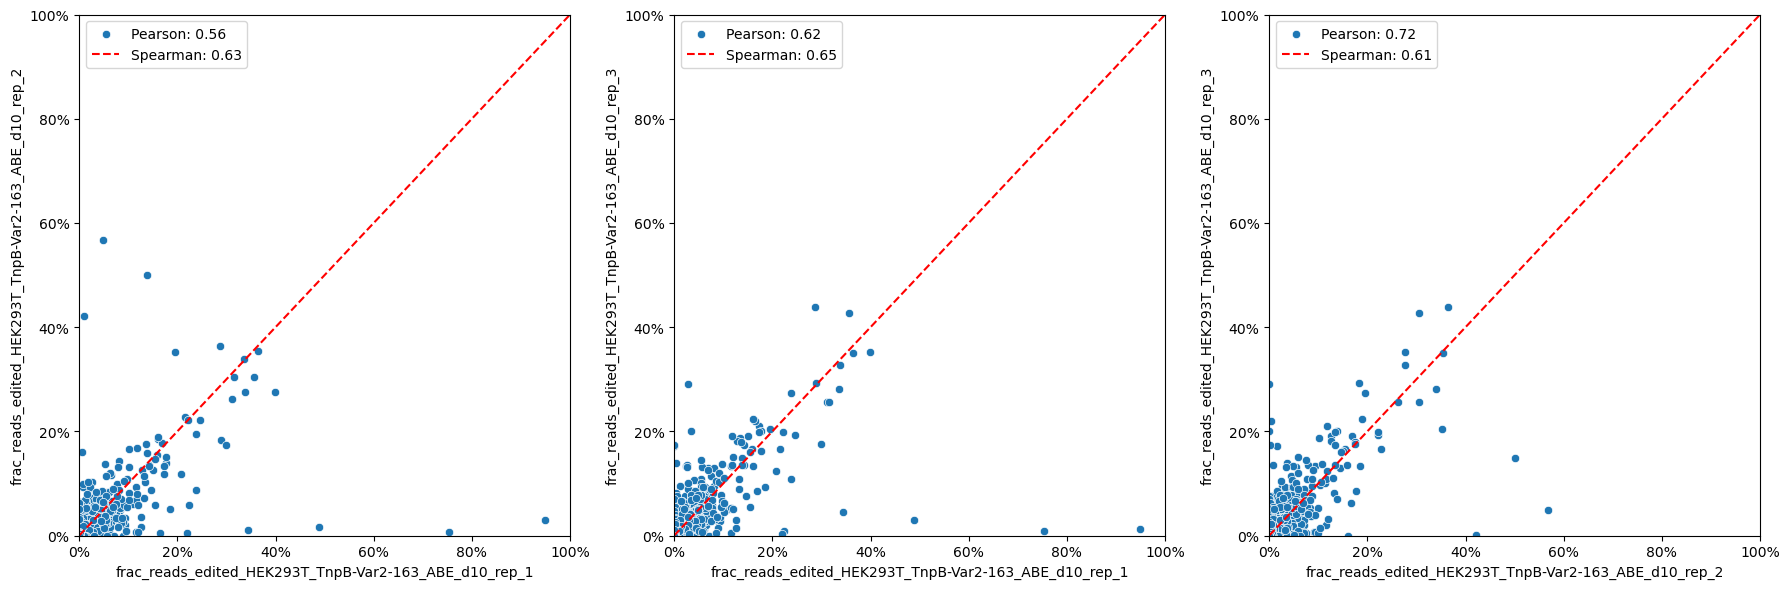

(1120, 3)


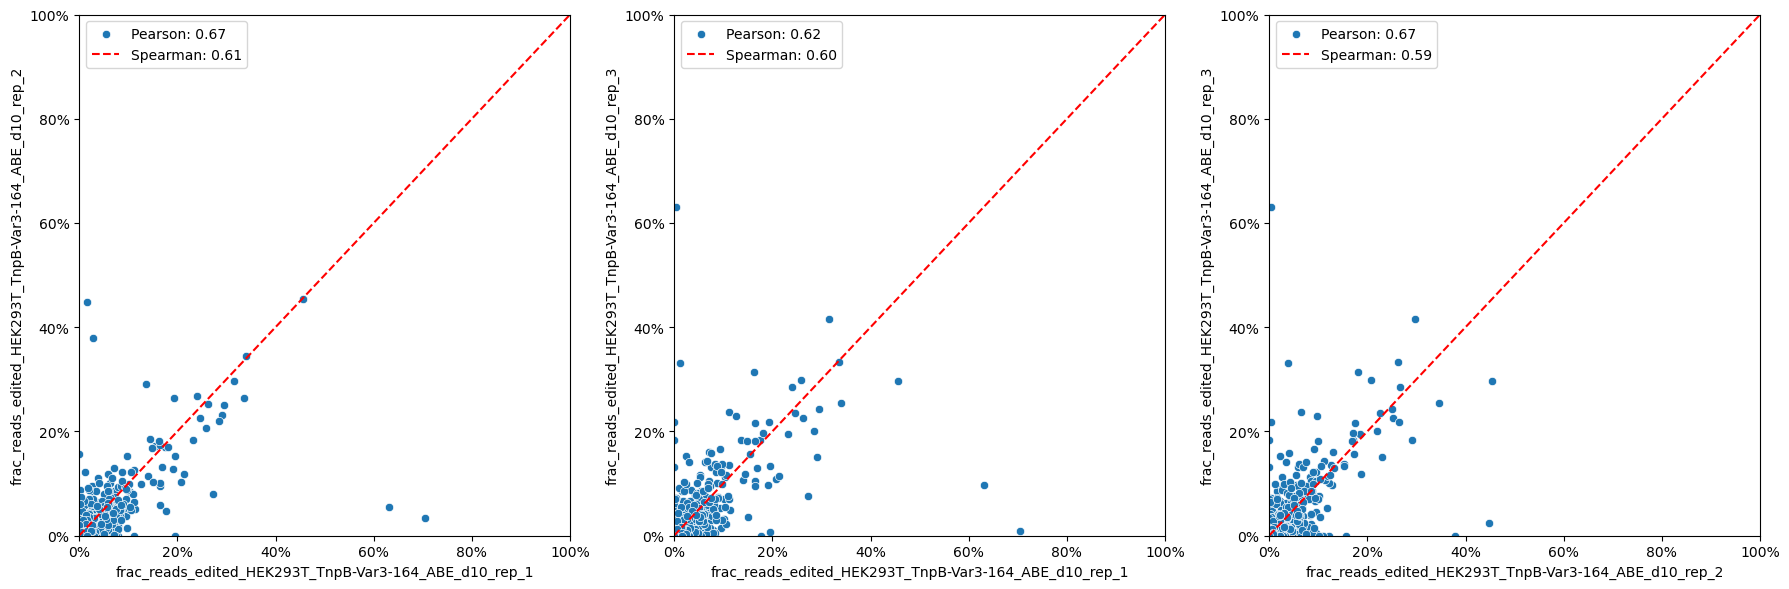

(1147, 3)


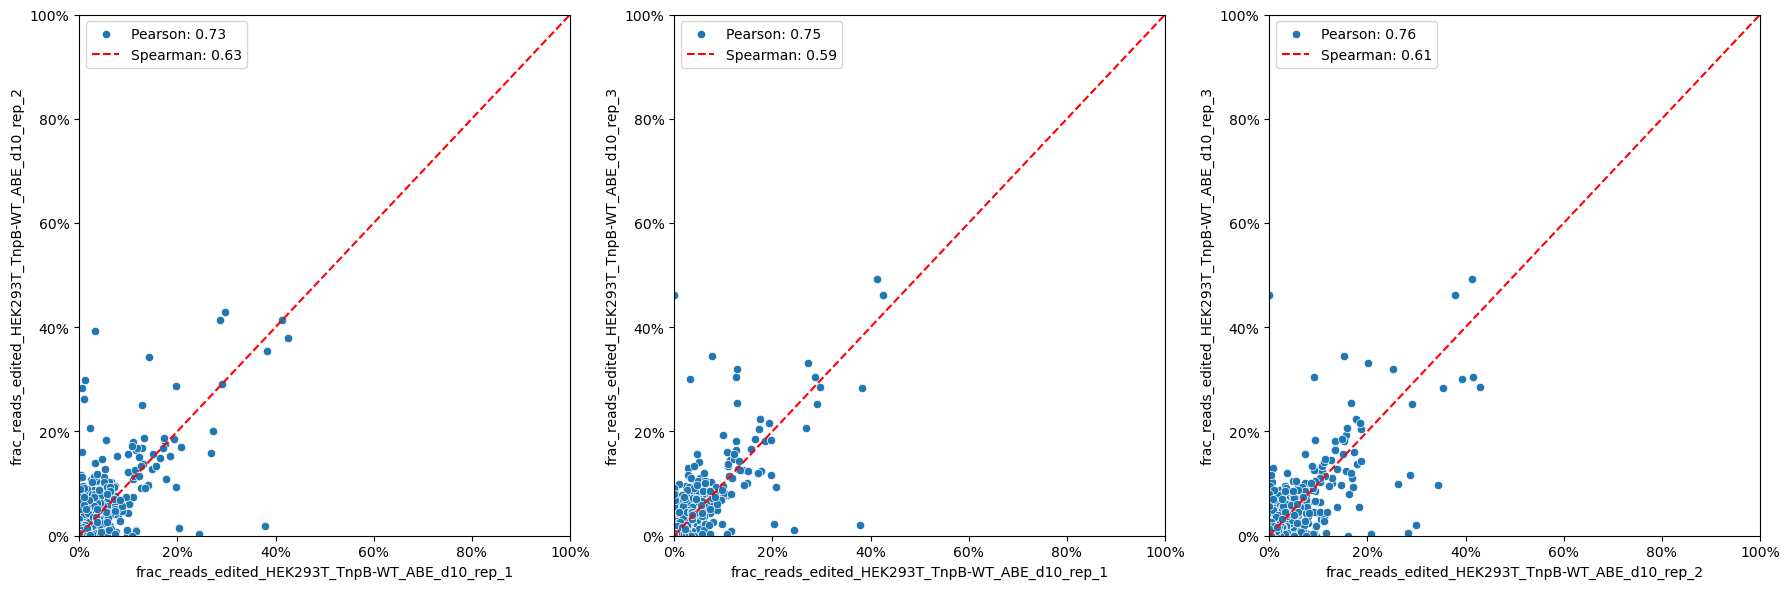

In [ ]:
#all_abe_samples_reads_editedrates_pivot_df_slim=all_abe_samples_reads_editedrates_pivot_df.loc[:,list(editor_columns)]
all_abe_samples_reads_editedrates_pivot_df_slim=all_abe_samples_reads_editedrates_pivot_df.loc[all_abe_samples_reads_editedrates_pivot_df["TAM_"]=="TTGAT",list(editor_columns)]
print(all_abe_samples_reads_editedrates_pivot_df_slim.shape)
all_abe_samples_reads_editedrates_pivot_df_slim
# Iterate over every 3 columns
for i in range(0, len(all_abe_samples_reads_editedrates_pivot_df_slim.columns), 3):
    if i + 2 < len(all_abe_samples_reads_editedrates_pivot_df_slim.columns):
        col1 = all_abe_samples_reads_editedrates_pivot_df_slim.columns[i]
        col2 = all_abe_samples_reads_editedrates_pivot_df_slim.columns[i + 1]
        col3 = all_abe_samples_reads_editedrates_pivot_df_slim.columns[i + 2]

        test=all_abe_samples_reads_editedrates_pivot_df_slim[[col1,col2,col3]]
        test = test.dropna()
        print(test.shape)
        sample_name=all_abe_samples_reads_editedrates_pivot_df_slim.columns[i].split("_rep")[0].split("edited_")[-1]
        plot_correlation(test, col1, col2, col3,save_figure=True, figure_folder=NAS_folder,
                         figure_name=f"Read_level_correlation_afterNormalisation_TTGAT(TAM)_{sample_name}")

# this means the correlation before is caused by same bias as in the control that cause editing rate 

(887, 12)
(802, 3)


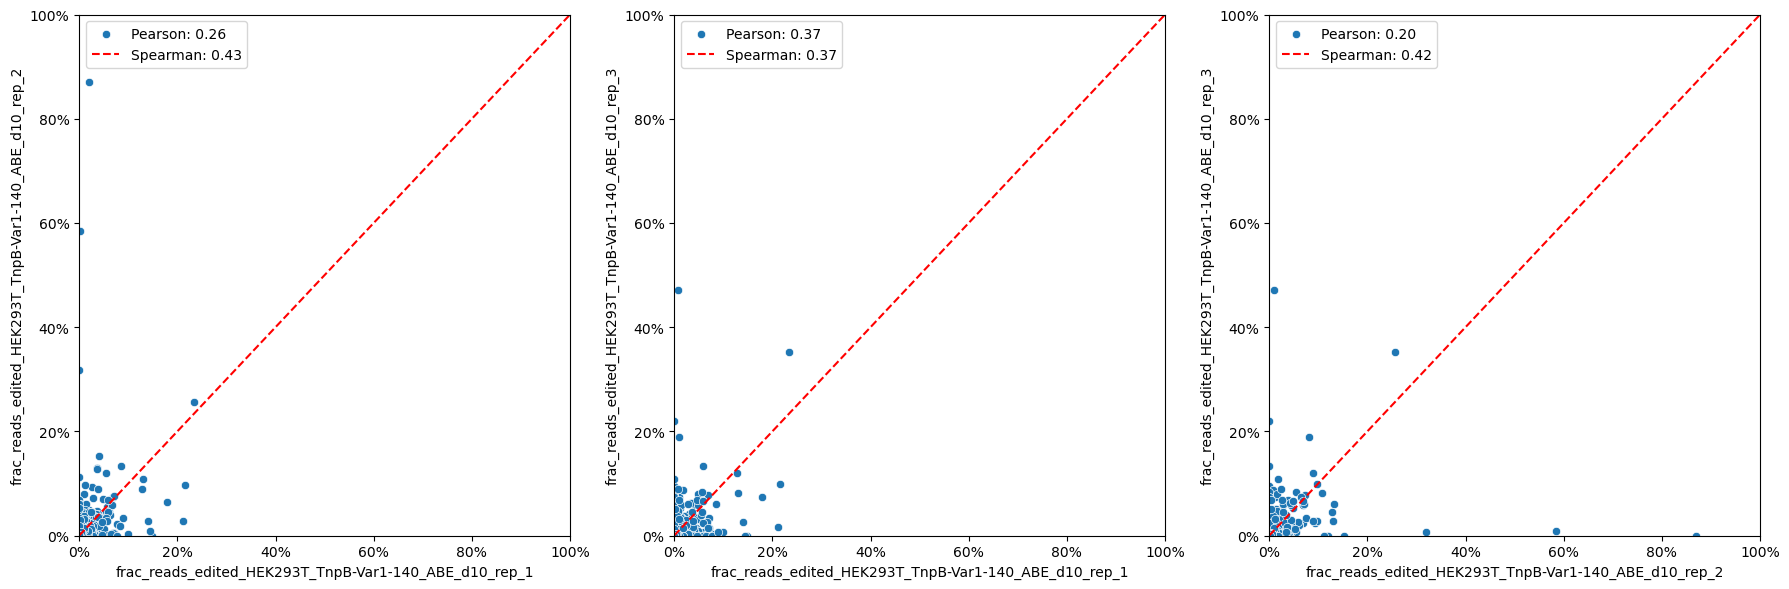

(812, 3)


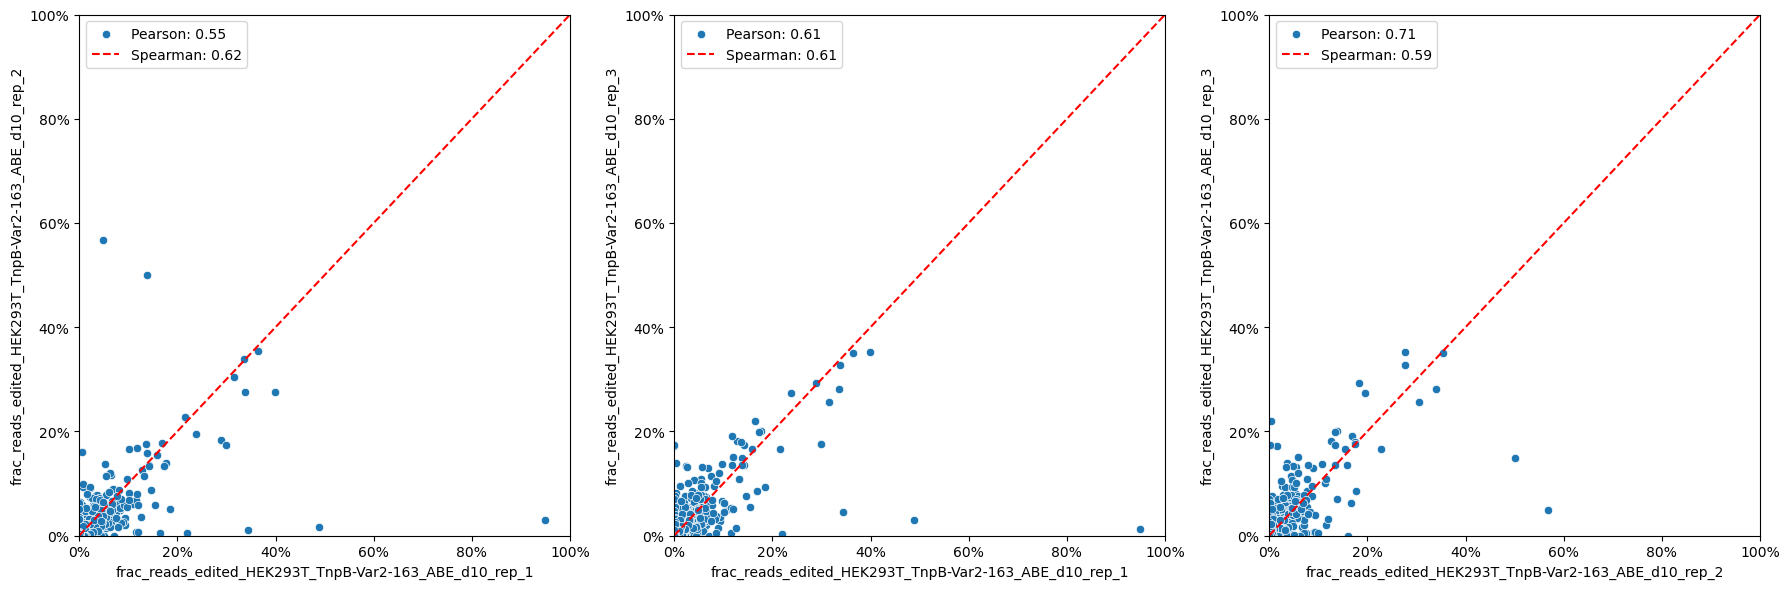

(795, 3)


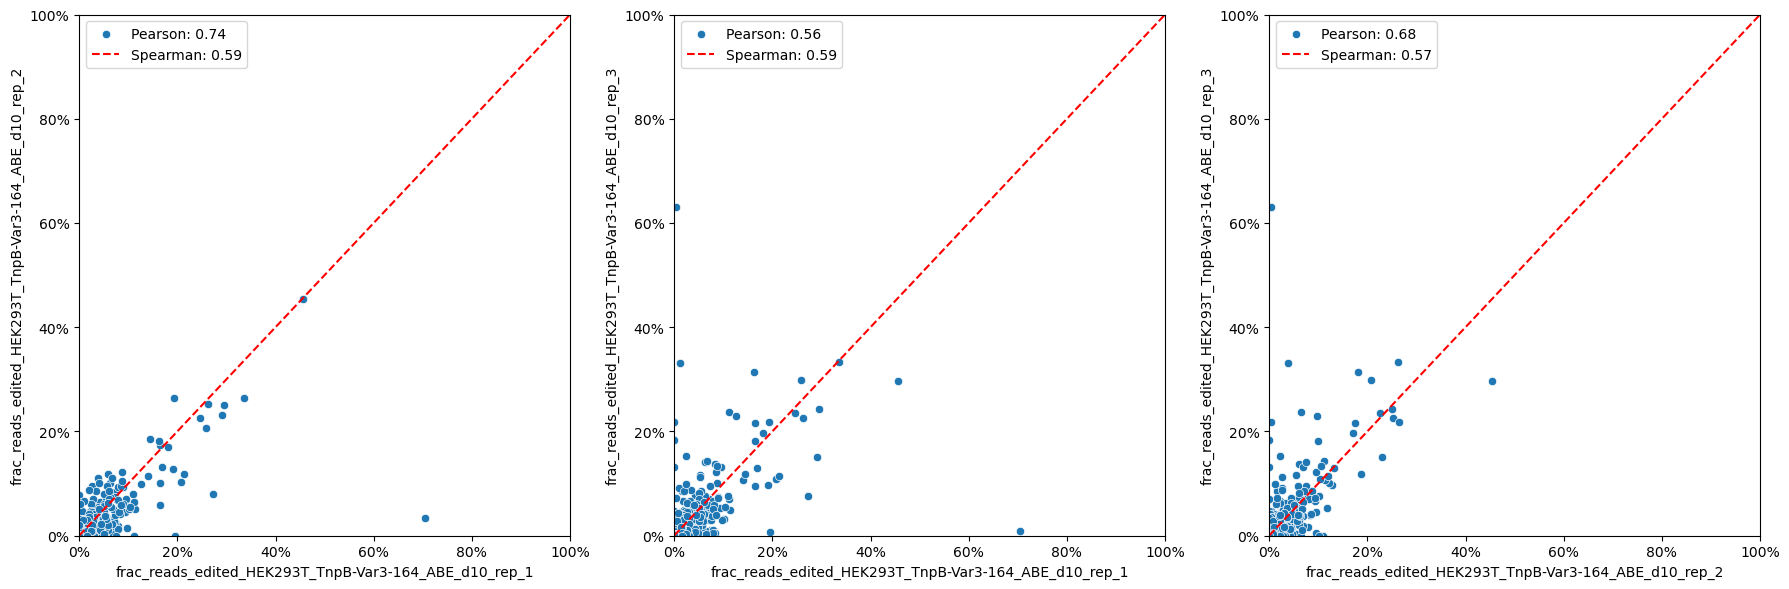

(822, 3)


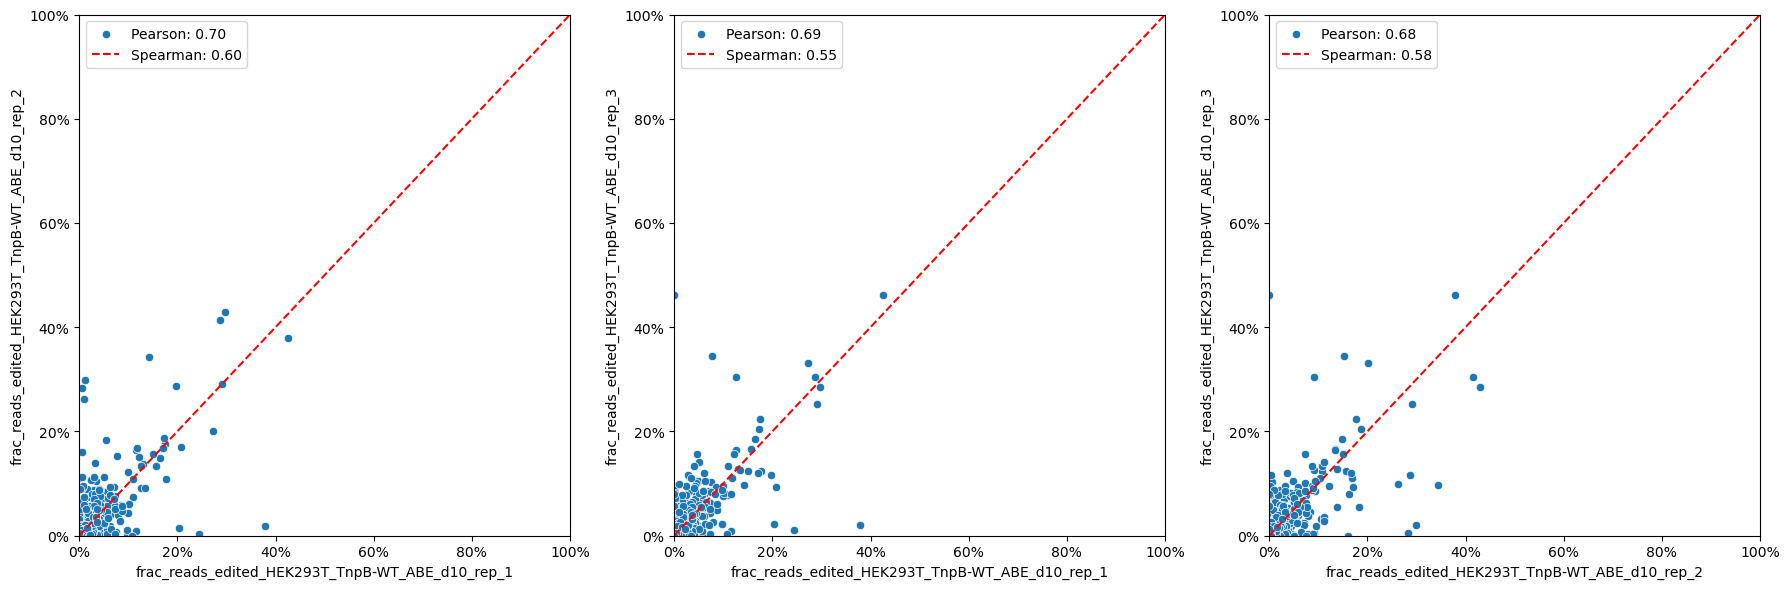

In [ ]:
all_abe_samples_reads_editedrates_pivot_df_slim = all_abe_samples_reads_editedrates_pivot_df.merge(lib[['barcode', 'lib_section']], left_on='barcode_', right_on='barcode', how='left')

all_abe_samples_reads_editedrates_pivot_df_slim=all_abe_samples_reads_editedrates_pivot_df_slim.loc[all_abe_samples_reads_editedrates_pivot_df_slim["lib_section"]=="MM_TTGAT_20BP_",list(editor_columns)]
print(all_abe_samples_reads_editedrates_pivot_df_slim.shape)
all_abe_samples_reads_editedrates_pivot_df_slim
# Iterate over every 3 columns
for i in range(0, len(all_abe_samples_reads_editedrates_pivot_df_slim.columns), 3):
    if i + 2 < len(all_abe_samples_reads_editedrates_pivot_df_slim.columns):
        col1 = all_abe_samples_reads_editedrates_pivot_df_slim.columns[i]
        col2 = all_abe_samples_reads_editedrates_pivot_df_slim.columns[i + 1]
        col3 = all_abe_samples_reads_editedrates_pivot_df_slim.columns[i + 2]

        test=all_abe_samples_reads_editedrates_pivot_df_slim[[col1,col2,col3]]
        test = test.dropna()
        print(test.shape)
        plot_correlation(test, col1, col2, col3)
        #break

        

In [ ]:
# First, filter groups that have exactly 3 replicates,
# then calculate the mean of "frac_reads_edited" for each group.
all_abe_samples_reads_editedrates_averaged_strict = (
    all_abe_samples_reads_editedrates.groupby(["editor", "barcode","TAM"])
    .filter(lambda x: len(x) == 3)
    .groupby(["editor", "barcode","TAM"])["frac_reads_edited"]
    .mean()
    .reset_index()
)
print(all_abe_samples_reads_editedrates_averaged_strict.shape)

(18390, 4)


In [ ]:
def plot_all_mean_editing_rates(df, figure_size=(15, 7)):
    plt.figure(figsize=figure_size)
    # Plot individual data points with stripplot
    ax = sns.stripplot(data=df, x="TAM", y="frac_reads_edited", hue="editor", jitter=True, dodge=True, alpha=0.5)
    # Overlay means with pointplot using prominent markers
    sns.pointplot(
        data=df,
        x="TAM",
        y="frac_reads_edited",
        hue="editor",
        estimator=np.mean,
        dodge=0.6,
        join=False,
        markers="_",  # Horizontal line for means
        scale=1.5,  # Larger markers
        color="black",
        ci=None,
        ax=ax,
        zorder=10,  # Ensure means are on top
        legend=False  # Hide legend for means
    )
    plt.title("Fraction Reads Edited by Editor Across TAM Groups")
    plt.xlabel("TAM")
    plt.ylabel("Fraction Reads Edited")
    plt.xticks(rotation=45)
    plt.legend(title="Editor")
    plt.show()

# check aggregated results 

## check change compare with WT per samples 

In [ ]:
# print("aggregating ABE replicates")
# d = pd.read_csv(config.edit_rate('all-abe-samples-normalized'), index_col=0)
# d=d.loc[~d["edit_rate"].isna(),:]
# # Group by the specified columns and filter groups with exactly all replicates
# d = d.groupby(['editor', 'barcode', 'TAM', 'edit_position']).filter(lambda x: len(x) == 3)
# d = screen_utils.aggregate_replicates(d,
#     cols_group=['editor','barcode','TAM','edit_position'], # here editor and barcoe(library) combination is a biological replicate, PAM/TAM is not consider here ?
#     col_rate='edit_rate'                             # PAM/TAM is not consider here ?
# ).drop(columns=['sample_name', 'replicate'])
# d.to_csv(config.edit_rate('all-abe-editors'))

# def aggregate_replicates(data: pd.DataFrame, cols_group = ['sublibrary','site_id', 'PAM', 'bioreplicate'], col_rate='edit_rate') -> pd.DataFrame:
#     """ Aggregate replicates by taking the mean editing rate.

#     Args:
#         data (pd.DataFrame): data to aggregate
#         cols_group (List[str]): columns to group by
#         col_rate (str): column name for editing rate
#     Returns:
#         pd.DataFrame: aggregated data
#     """
#     agg_funcs = {col: 'first' for col in data.columns if col not in cols_group + [col_rate]}
#     agg_funcs[col_rate] = 'mean'
#     return data.groupby(cols_group).agg(agg_funcs).reset_index()

In [ ]:
all_abe_samples_not_normalized= pd.read_csv(config.edit_rate('all-abe-samples-not-normalized'), index_col=0)
print(all_abe_samples_not_normalized.shape)
all_abe_samples_not_normalized=all_abe_samples_not_normalized.loc[~all_abe_samples_not_normalized["edit_rate"].isna(),:]
print(all_abe_samples_not_normalized.shape)
all_abe_samples_not_normalized.head(n=3)

(501105, 15)
(474589, 15)


,barcode,TAM,edit_position,num_reads,target_site,spacer,spacer_lib,target_site_lib,most_common_diff_target_site,most_common_diff_target_site_num,edit_rate,editor,sample_name,is_ctrl,replicate
0,AAAAAAA,TAGAT,2,1965,AAACATTGTCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,38.0,0.001527,TnpB-WT_ABE_d10,HEK293T_TnpB-WT_ABE_d10_rep_1,False,1
1,AAAAAAA,TAGAT,3,1965,AAACATTGTCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,38.0,0.001527,TnpB-WT_ABE_d10,HEK293T_TnpB-WT_ABE_d10_rep_1,False,1
2,AAAAAAA,TAGAT,5,1965,AAACATTGTCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,38.0,0.003053,TnpB-WT_ABE_d10,HEK293T_TnpB-WT_ABE_d10_rep_1,False,1


In [ ]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_not_normalized=all_abe_samples_not_normalized.loc[all_abe_samples_not_normalized['editor'] != "TnpB-NONE_ABE_mock_d10",:]
print(all_abe_samples_not_normalized.shape) 

(378485, 15)


In [ ]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

Editors_all_samples_not_normalized=all_abe_samples_not_normalized.loc[all_abe_samples_not_normalized['editor'] != "TnpB-WT_ABE_d10",:]
print(Editors_all_samples_not_normalized.shape)
WT_all_samples_not_normalized=all_abe_samples_not_normalized.loc[all_abe_samples_not_normalized['editor'] == "TnpB-WT_ABE_d10",:]
WT_all_samples_not_normalized.shape

(283638, 15)


(94847, 15)

In [ ]:
# Group by the specified columns and filter groups with exactly all replicates
WT_all_samples_not_normalized = WT_all_samples_not_normalized.groupby(['editor', 'barcode', 'TAM', 'edit_position']).filter(lambda x: len(x) == 3)

In [ ]:
WT_all_samples_not_normalized_avg = WT_all_samples_not_normalized.groupby(
    ['editor', 'barcode', 'TAM', 'edit_position'], as_index=False
)['edit_rate'].mean()
print(WT_all_samples_not_normalized_avg.shape)
WT_all_samples_not_normalized_avg.head()

(30947, 5)


,editor,barcode,TAM,edit_position,edit_rate
0,TnpB-WT_ABE_d10,AAAAAAA,TAGAT,2,0.003853
1,TnpB-WT_ABE_d10,AAAAAAA,TAGAT,3,0.001239
2,TnpB-WT_ABE_d10,AAAAAAA,TAGAT,5,0.002934
3,TnpB-WT_ABE_d10,AAAAAAA,TAGAT,8,0.009117
4,TnpB-WT_ABE_d10,AAAAAAA,TAGAT,14,0.000864


In [ ]:
import numpy as np

# Merge the two dataframes on "barcode" and "TAM"
Editors_all_samples_not_normalized_logFC = Editors_all_samples_not_normalized.merge(
    WT_all_samples_not_normalized_avg,
    on=['barcode', 'TAM', 'edit_position'],
    how='left',
    suffixes=("_editor", "_wt")
)

# Calculate log fold change
Editors_all_samples_not_normalized_logFC["logFC"] = np.log2(Editors_all_samples_not_normalized_logFC["edit_rate_editor"] / Editors_all_samples_not_normalized_logFC["edit_rate_wt"])

Editors_all_samples_not_normalized_logFC.shape

/mnt/mnemo2/opt/conda/envs/tnpb-analysis/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


(283638, 18)

In [ ]:
# Filter out rows with infinite or -infinite logFC values
Editors_all_samples_not_normalized_logFC = Editors_all_samples_not_normalized_logFC[np.isfinite(Editors_all_samples_not_normalized_logFC['logFC'])]
print(Editors_all_samples_not_normalized_logFC.shape)

(217753, 18)


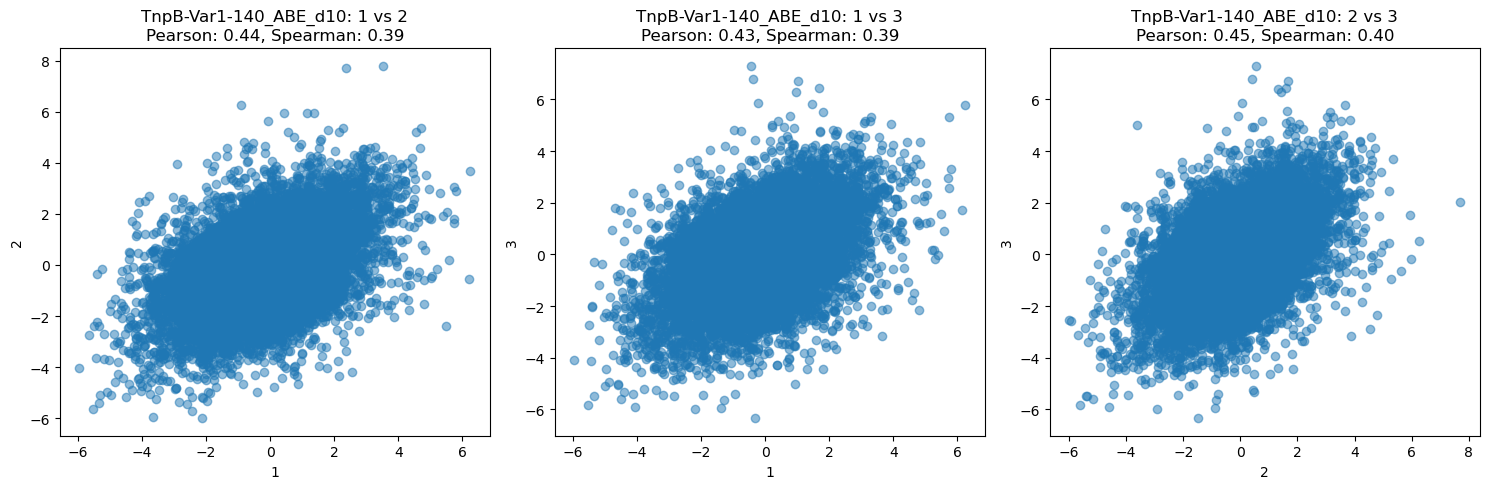

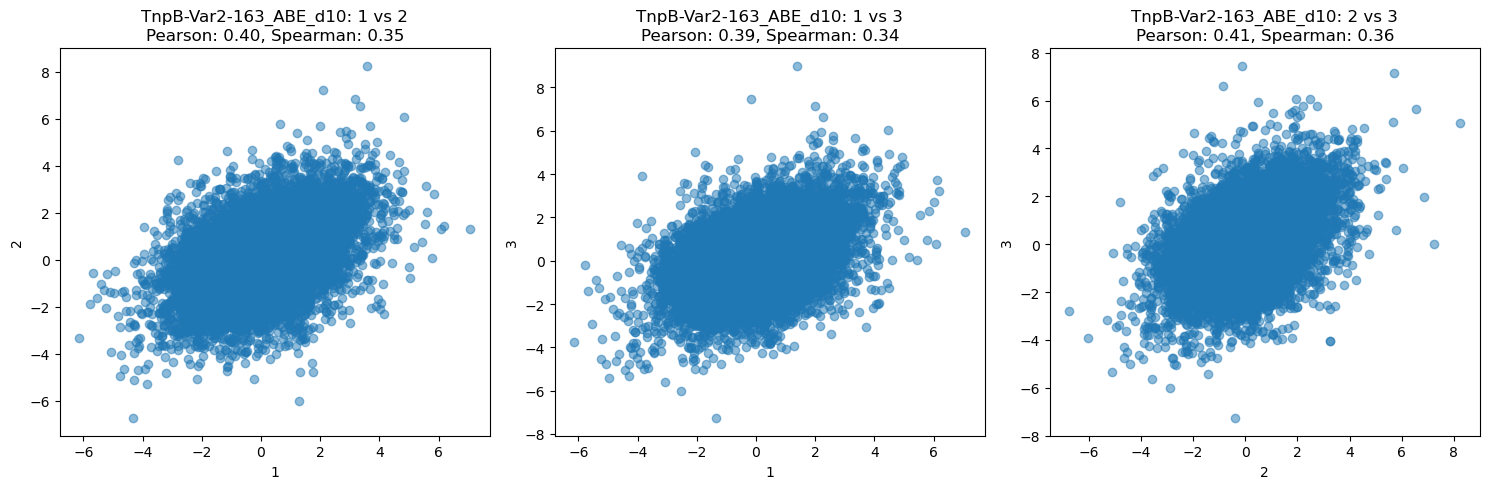

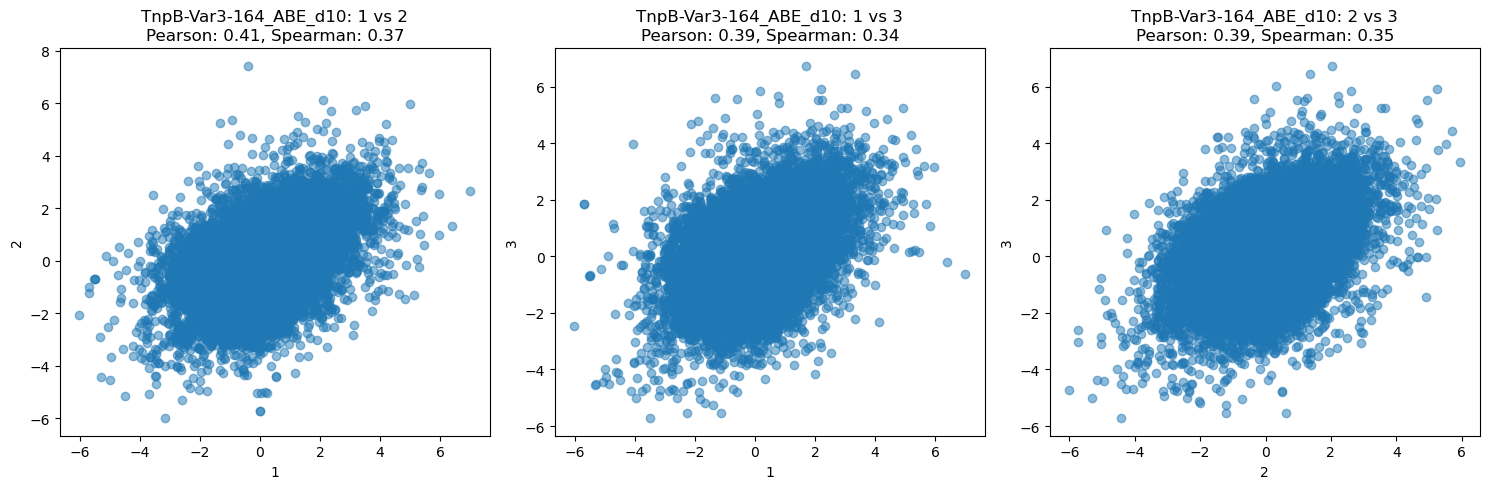

In [ ]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import itertools
from scipy.stats import pearsonr, spearmanr

# Choose the replicate column (change if needed)
replicate_col = "replicate_editor" if "replicate_editor" in Editors_all_samples_not_normalized_logFC.columns else "replicate"

# Iterate over each editor
for ed in Editors_all_samples_not_normalized_logFC["editor_editor"].unique():
    df_ed = Editors_all_samples_not_normalized_logFC[Editors_all_samples_not_normalized_logFC["editor_editor"] == ed]
    # Pivot so rows are identified by barcode and edit_position and columns are replicates
    pivot_df = df_ed.pivot_table(index=["barcode", "edit_position"], columns=replicate_col, values="logFC")

    # Get all pairs of replicate columns
    rep_cols = pivot_df.columns.tolist()
    pairs = list(itertools.combinations(rep_cols, 2))

    num_pairs = len(pairs)
    fig, axes = plt.subplots(1, num_pairs, figsize=(5*num_pairs, 5), squeeze=False)

    # Iterate through all replicate pairs to make scatter plots with correlation stats in the title
    for ax, (r1, r2) in zip(axes[0], pairs):
        x = pivot_df[r1]
        y = pivot_df[r2]
        valid = x.notna() & y.notna()
        x_valid = x[valid]
        y_valid = y[valid]
        if len(x_valid) > 0:
            pearson_corr, _ = pearsonr(x_valid, y_valid)
            spearman_corr, _ = spearmanr(x_valid, y_valid)
        else:
            pearson_corr = np.nan
            spearman_corr = np.nan

        ax.scatter(x, y, alpha=0.5)
        ax.set_xlabel(r1)
        ax.set_ylabel(r2)
        ax.set_title(f"{ed}: {r1} vs {r2}\nPearson: {pearson_corr:.2f}, Spearman: {spearman_corr:.2f}")

    plt.tight_layout()
    plt.show()

In [ ]:
all_abe_samples_normalized= pd.read_csv(config.edit_rate('all-abe-samples-normalized'), index_col=0)
print(all_abe_samples_normalized.shape)
all_abe_samples_normalized=all_abe_samples_normalized.loc[~all_abe_samples_normalized["edit_rate"].isna(),:]
print(all_abe_samples_normalized.shape)
all_abe_samples_normalized.head(n=3)

(352476, 15)
(348392, 15)


,barcode,TAM,edit_position,num_reads,target_site,spacer,spacer_lib,target_site_lib,most_common_diff_target_site,most_common_diff_target_site_num,edit_rate,editor,sample_name,is_ctrl,replicate
0,AAAAAAA,TAGAT,2,1965,AAACATTGTCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,38.0,0.000000,TnpB-WT_ABE_d10,HEK293T_TnpB-WT_ABE_d10_rep_1,False,1
1,AAAAAAA,TAGAT,3,1965,AAACATTGTCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,38.0,0.000000,TnpB-WT_ABE_d10,HEK293T_TnpB-WT_ABE_d10_rep_1,False,1
2,AAAAAAA,TAGAT,5,1965,AAACATTGTCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTGTCGGTATCTTGA,38.0,0.001406,TnpB-WT_ABE_d10,HEK293T_TnpB-WT_ABE_d10_rep_1,False,1


In [ ]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

Editors_all_samples_normalized=all_abe_samples_normalized.loc[all_abe_samples_normalized['editor'] != "TnpB-WT_ABE_d10",:]
print(Editors_all_samples_normalized.shape)
WT_all_samples_normalized=all_abe_samples_normalized.loc[all_abe_samples_normalized['editor'] == "TnpB-WT_ABE_d10",:]
WT_all_samples_normalized.shape

(261112, 15)


(87280, 15)

In [ ]:
# Group by the specified columns and filter groups with exactly all replicates
WT_all_samples_normalized = WT_all_samples_normalized.groupby(['editor', 'barcode', 'TAM', 'edit_position']).filter(lambda x: len(x) == 3)

In [ ]:
WT_all_samples_normalized_avg = WT_all_samples_normalized.groupby(
    ['editor', 'barcode', 'TAM', 'edit_position'], as_index=False
)['edit_rate'].mean()
print(WT_all_samples_normalized_avg.shape)
WT_all_samples_normalized_avg.head()

(28776, 5)


,editor,barcode,TAM,edit_position,edit_rate
0,TnpB-WT_ABE_d10,AAAAAAA,TAGAT,2,0.001693
1,TnpB-WT_ABE_d10,AAAAAAA,TAGAT,3,0.000000
2,TnpB-WT_ABE_d10,AAAAAAA,TAGAT,5,0.001286
3,TnpB-WT_ABE_d10,AAAAAAA,TAGAT,8,0.008199
4,TnpB-WT_ABE_d10,AAAAAAA,TAGAT,14,0.000088


In [ ]:
import numpy as np

# Merge the two dataframes on "barcode" and "TAM"
Editors_all_samples_normalized_logFC = Editors_all_samples_normalized.merge(
    WT_all_samples_normalized_avg,
    on=['barcode', 'TAM', 'edit_position'],
    how='left',
    suffixes=("_editor", "_wt")
)

# Calculate log fold change
Editors_all_samples_normalized_logFC["logFC"] = np.log2(Editors_all_samples_normalized_logFC["edit_rate_editor"] / Editors_all_samples_normalized_logFC["edit_rate_wt"])

Editors_all_samples_normalized_logFC.shape

/mnt/mnemo2/opt/conda/envs/tnpb-analysis/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


(261112, 18)

In [ ]:
# Filter out rows with infinite or -infinite logFC values
Editors_all_samples_normalized_logFC = Editors_all_samples_normalized_logFC[np.isfinite(Editors_all_samples_normalized_logFC['logFC'])]
print(Editors_all_samples_normalized_logFC.shape)

(107162, 18)


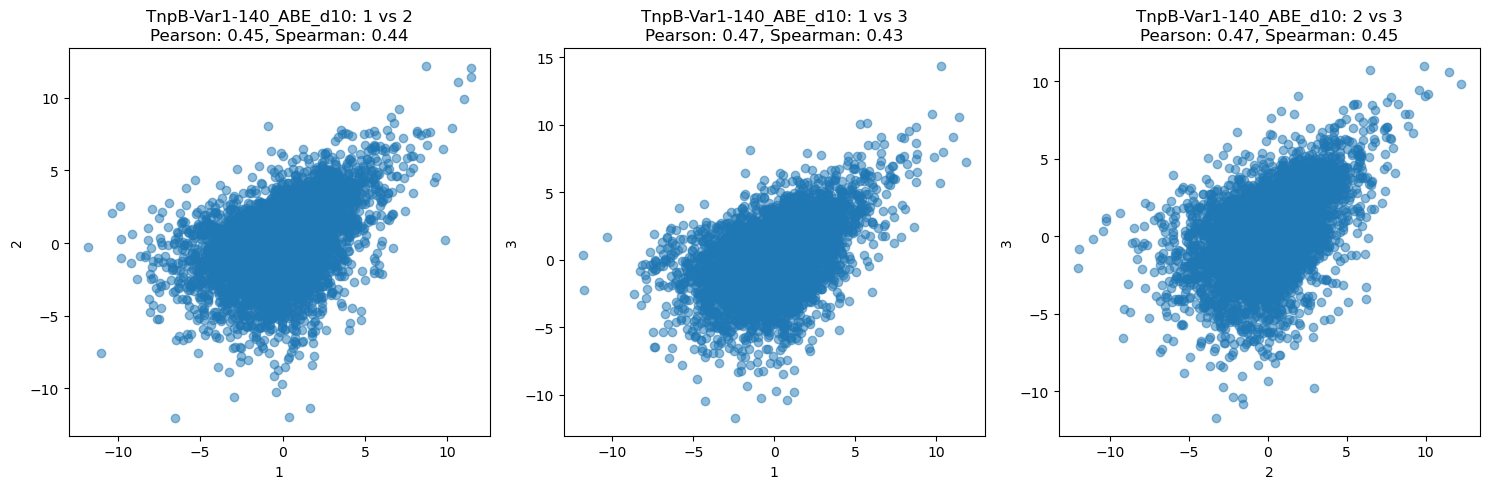

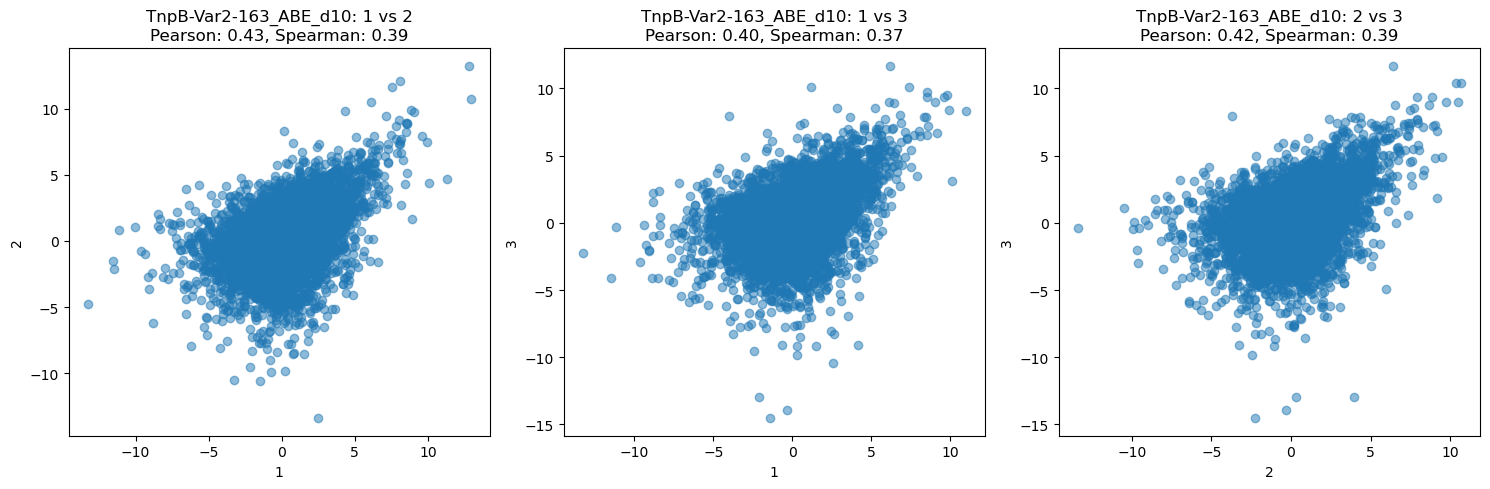

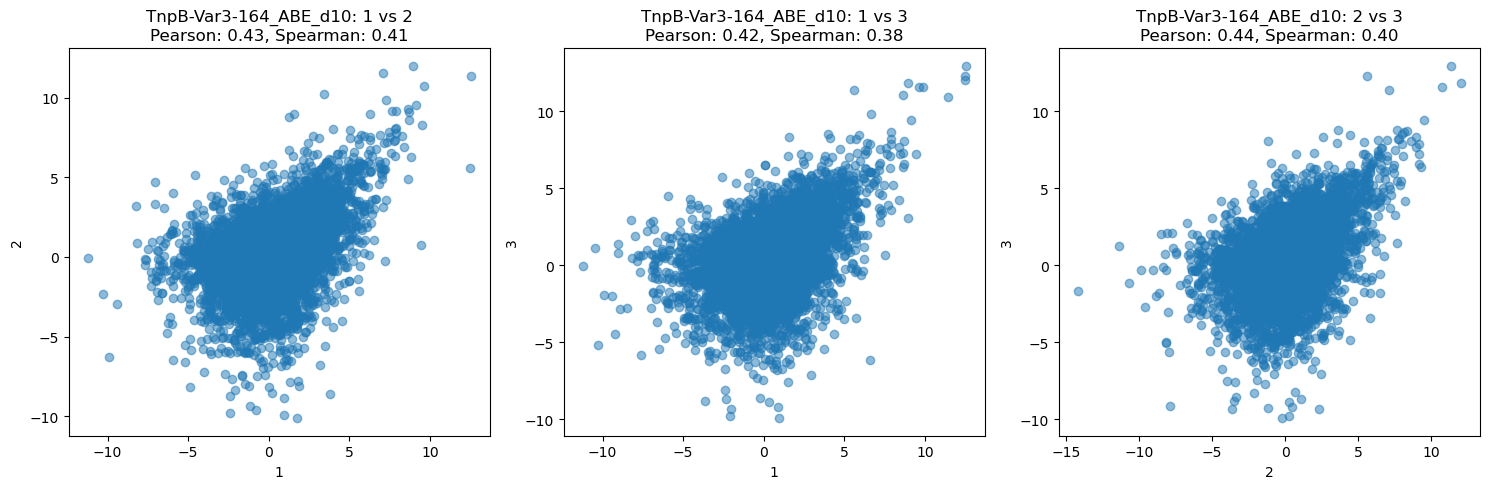

In [ ]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import itertools
from scipy.stats import pearsonr, spearmanr

# Choose the replicate column (change if needed)
replicate_col = "replicate_editor" if "replicate_editor" in Editors_all_samples_normalized_logFC.columns else "replicate"

# Iterate over each editor
for ed in Editors_all_samples_normalized_logFC["editor_editor"].unique():
    df_ed = Editors_all_samples_normalized_logFC[Editors_all_samples_normalized_logFC["editor_editor"] == ed]
    # Pivot so rows are identified by barcode and edit_position and columns are replicates
    pivot_df = df_ed.pivot_table(index=["barcode", "edit_position"], columns=replicate_col, values="logFC")

    # Get all pairs of replicate columns
    rep_cols = pivot_df.columns.tolist()
    pairs = list(itertools.combinations(rep_cols, 2))

    num_pairs = len(pairs)
    fig, axes = plt.subplots(1, num_pairs, figsize=(5*num_pairs, 5), squeeze=False)

    # Iterate through all replicate pairs to make scatter plots with correlation stats in the title
    for ax, (r1, r2) in zip(axes[0], pairs):
        x = pivot_df[r1]
        y = pivot_df[r2]
        valid = x.notna() & y.notna()
        x_valid = x[valid]
        y_valid = y[valid]
        if len(x_valid) > 0:
            pearson_corr, _ = pearsonr(x_valid, y_valid)
            spearman_corr, _ = spearmanr(x_valid, y_valid)
        else:
            pearson_corr = np.nan
            spearman_corr = np.nan

        ax.scatter(x, y, alpha=0.5)
        ax.set_xlabel(r1)
        ax.set_ylabel(r2)
        ax.set_title(f"{ed}: {r1} vs {r2}\nPearson: {pearson_corr:.2f}, Spearman: {spearman_corr:.2f}")

    plt.tight_layout()
    plt.show()

In [ ]:
results_df=pd.read_csv(config.edit_rate('all-abe-editors'),index_col=False)
print(results_df.shape)
results_df = results_df[results_df['num_reads'] >= 100]     # 100,1000
print(results_df.shape)
results_df = results_df[results_df['edit_rate'] >=0.00] # 0.01
print(results_df.shape)

(114608, 14)
(114608, 14)
(114608, 14)


In [ ]:


results_df=check_A_to_A_or_C(results_df)
results_df
merged_df = results_df.merge(lib[['barcode', 'finalname', 'lib_section', 'specific_primerpart']], on='barcode', how='left')
merged_df = merged_df.drop(columns=['target_site'])
merged_df.to_csv(config.result_dir / 'results_picked.csv', index=False)

In [ ]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import numpy as np

# Create a lookup series for the reference edit_rate per group (barcode, edit_position)
ref_series = merged_df.loc[merged_df["editor"] == "TnpB-WT_ABE_d10"] \
    .groupby(["barcode", "edit_position"])["edit_rate"].first()

# Map the reference value back to the full dataframe
merged_df["ref_val"] = merged_df.set_index(["barcode", "edit_position"]).index.map(ref_series.to_dict())
# Fill missing reference values with zero
merged_df["ref_val"] = merged_df["ref_val"].fillna(0)

# Compute logFC with vectorized operations
epsilon = 1e-6
merged_df["logFC"] = np.log2((merged_df["edit_rate"] + epsilon) / (merged_df["ref_val"] + epsilon))

merged_df_logfc = merged_df
merged_df_logfc

,Unnamed: 0,editor,barcode,TAM,edit_position,num_reads,spacer,spacer_lib,target_site_lib,most_common_diff_target_site,most_common_diff_target_site_num,is_ctrl,edit_rate,valid_diff_nt,finalname,lib_section,specific_primerpart,ref_val,logFC
0,0,TnpB-Var1-140_ABE_d10,AAAAAAA,TAGAT,2,2065,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTACCTTGA,9.0,False,0.001500,19,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA,0.001693,-0.174310
1,1,TnpB-Var1-140_ABE_d10,AAAAAAA,TAGAT,3,2065,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTACCTTGA,9.0,False,0.000253,19,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA,0.000000,7.987190
2,2,TnpB-Var1-140_ABE_d10,AAAAAAA,TAGAT,5,2065,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTACCTTGA,9.0,False,0.000096,19,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA,0.001286,-3.731469
3,3,TnpB-Var1-140_ABE_d10,AAAAAAA,TAGAT,8,2065,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTACCTTGA,9.0,False,0.002493,19,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA,0.008199,-1.717294
4,4,TnpB-Var1-140_ABE_d10,AAAAAAA,TAGAT,14,2065,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTATCTTGA,GAACATTATCGGTACCTTGA,9.0,False,0.001363,19,4853_TAM_PERMUT_TAGAT_100MEMBER_spacer_53,TAM_PERMUT_TAGAT_,AGAGCCATTTGTCTCGCTGA,0.000088,3.941496
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114603,114603,TnpB-WT_ABE_d10,TTTTTTT,TTTAT,3,953,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAG,10.0,False,0.000000,20,289_MM_ENDO_TTTAT_20BP_Chr15_77000569_77001267...,MM_ENDO_TTTAT_20BP_,AGAGCCATTTGTCTCGCTGA,0.000000,0.000000
114604,114604,TnpB-WT_ABE_d10,TTTTTTT,TTTAT,16,953,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAG,10.0,False,0.000181,20,289_MM_ENDO_TTTAT_20BP_Chr15_77000569_77001267...,MM_ENDO_TTTAT_20BP_,AGAGCCATTTGTCTCGCTGA,0.000181,0.000000
114605,114605,TnpB-WT_ABE_d10,TTTTTTT,TTTAT,17,953,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAG,10.0,False,0.000090,20,289_MM_ENDO_TTTAT_20BP_Chr15_77000569_77001267...,MM_ENDO_TTTAT_20BP_,AGAGCCATTTGTCTCGCTGA,0.000090,0.000000
114606,114606,TnpB-WT_ABE_d10,TTTTTTT,TTTAT,19,953,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAA,TAAGGTTGGTGTGTGAAGAG,10.0,False,0.001922,20,289_MM_ENDO_TTTAT_20BP_Chr15_77000569_77001267...,MM_ENDO_TTTAT_20BP_,AGAGCCATTTGTCTCGCTGA,0.001922,0.000000
